# V-JEPA 2 烹飪導引：逐段執行

每一段的**輸入 → 輸出**都寫在段落開頭，可以單獨重跑任何一段來檢查中間結果。

| 段 | 做什麼 | 需要 GPU |
|---|---|---|
| 1 | 環境設定（解開程式碼、確認 GPU） | |
| 2 | 參數 | |
| 3 | 下載標註、權重、影片 | |
| 4 | 載入 World Model（encoder + predictor）與 Probe | ✓ |
| 5 | 解剖一個時間點：影片 → latent state → 預測的 state → 動詞/名詞 | ✓ |
| 6 | 整部影片每秒預測一次，存成 `.npz` | ✓ |
| 7 | 食譜步驟（HD-EPIC 原文） | |
| 8 | VLM 為每一步寫手部動作標籤 | |
| 9 | Action Bank：把標籤變成矩陣 | |
| 10 | Step Tracker：每秒判斷目前步驟、計算準確率 | |
| 11 | 檢查單一秒的 Tracker 計算 | |
| 12 | Latency：一次預測要多久、能否即時 | ✓ |
| 13 | Coach 的輸入：食譜、做過的動作、現在的預測（不看未來） | |
| 14 | Coach AI（Muse Glimmer on NIM）：建議下一步 | |
| 15 | Decision Model（Liquid AI d1-2B）：從 Actions Bank 選下一個動作 | ✓ |
| 16 | 多久給一次建議 | |
| 17 | Coach 設定比較：Glimmer 推理開／低／關、max_tokens → 自動選一個 | |
| 18 | 時間軸：每次步驟切換問 Coach、每秒問 d1 | ✓ |
| 19 | 一部影片同時看 World Model、Coach、Decision Model；19b 匯出到 Demo 網頁 | |
| 20 | （選用）渲染導引影片 | |
| 21 | 記憶：食譜清單（做完／進行中／還沒做）與每秒「看到了」的規則 | |
| 22 | 「該做」vs「正在做」：不一致就叫 Coach；有記憶的 Coach prompt | |
| 23 | 有記憶的完整迴圈，並和沒有記憶的 Coach 比較 | ✓ |
| 24 | 把每秒預測合成「動作片段」 | |
| 25 | 事件記憶：Coach 看最近 N 個動作片段 | |
| 26 | 每 N 個動作才給一次建議（N = 3／5／10），重要事件才提早；比較；26b 重建記憶內容；26c d1 不推薦做完的步驟 | ✓ |
| 27 | 程序記憶：問 Coach 一次，食譜哪幾步會重複 | |
| 28 | HSMM 步驟追蹤（有時間長度、只看過去） | |
| 29 | 會數輪次的清單 | |
| 30 | 三層意圖：Now／Goal／Next | |
| 31 | 自適應時機（步驟切換、沒照建議做、退避），和每 10 個動作比較 | ✓ |
| 32 | 上限：用 HD-EPIC 標註當動作片段，重跑第 26、31 段 | ✓ |
| 33 | 用目標評估：記得做過的步驟（含時間）、提醒還沒做的步驟 | |
| 34 | 記憶：「開始做了」要看哪些動作（只重播，不用 GPU） | |
| 35 | 提醒還沒做的步驟、收尾前檢查、退避上限 90 秒 | ✓ |
| 36 | 人為漏掉一步：系統會不會提醒 | ✓ |
| 37 | 天花板：用人工標註當完美的 Probe，重跑第 35、36 段 | ✓ |
| 38 | 證據不清楚時看畫面（小的視覺模型確認步驟狀態） | ✓ |
| 39 | Coach 自己要求看畫面（80 GB A100：Glimmer + d1 + 11B） | ✓ |

**在 VS Code 連上 Colab GPU**：安裝 Google Colab 擴充套件 → 右上角 *Select Kernel* → *Colab* → *New Colab Server* → 選 GPU（T4）。
T4 約 1.15 compute units/小時，用完記得在 Colab 擴充套件裡關掉 server。
第 7–11 段只需要第 6 段的 `.npz`，不需要 GPU。

> 程式在 `src/coach/`（套件），這個 notebook 只負責呼叫與記錄結果；改了 `src/coach/` 之後執行 `python3 scripts/build_bundle.py`，把套件重新打包進第 1 段的 `BUNDLE`。
> 舊的 `archive/make_notebook.py` 只會產生第 1–11 段，已不再使用。

## 1. 環境設定
**輸入**：這一格最長那一行 `BUNDLE`（壓縮過的 `src/coach/` 套件，不用看）。**輸出**：`/content/coach/src/coach/`（Colab）或直接用這個 repo（本機）；`DEVICE`。

In [1]:
import base64, io, os, sys, zipfile
from pathlib import Path

def unpack(bundle: str) -> Path:
    """On Colab, unzip this notebook's copy of src/coach/ into /content/coach; locally, use the repo."""
    if not Path("/content").is_dir():
        here = Path.cwd()
        return next(p for p in (here, *here.parents) if (p / "src" / "coach").is_dir())
    root = Path("/content/coach")
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(bundle))) as zf:
        zf.extractall(root)  # always refresh the code from this notebook
    return root

BUNDLE = "..."
ROOT = unpack(BUNDLE)
ON_COLAB = ROOT == Path("/content/coach")
os.chdir(ROOT)  # the Colab kernel may start later cells back in /content, so paths below are absolute
sys.path.insert(0, str(ROOT / "src"))  # the coach package (pip install -e . also works)

try:
    import torch
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gpu = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none"
    print(f"torch {torch.__version__}, device {DEVICE}, GPU: {gpu}")
except Exception as e:  # stages 7-11 still run without torch
    torch, DEVICE = None, None
    print("no torch here:", e)
print("working in", ROOT)

import time

def timed(fn, n=10, warmup=2) -> float:
    """Median seconds of fn() over n runs, after warmup runs; waits for the GPU so its time counts."""
    sync = (lambda: torch.cuda.synchronize()) if DEVICE is not None and DEVICE.type == "cuda" else (lambda: None)
    for _ in range(warmup):
        fn()
    out = []
    for _ in range(n):
        sync()
        t0 = time.perf_counter()
        fn()
        sync()
        out.append(time.perf_counter() - t0)
    return sorted(out)[len(out) // 2]

torch 2.11.0+cu130, device cuda, GPU: Tesla T4
working in /content/coach


## 2. 參數
改這裡就能換影片或只跑前幾分鐘（`END = 120`）。HD-EPIC 的影片 id 與食譜 id 對照在 `complete_recipes.json`。

In [2]:
VIDEO_ID = "P08-20240614-085000"   # HD-EPIC video
RECIPE = "P08_R03"                  # Scrambled Eggs, 7 steps
STRIDE = 1.0                        # seconds between predictions
END = None                          # stop after this many seconds (None = whole video)
BATCH = 4                           # clips per GPU call
T_INSPECT = 300.0                   # the moment stage 5 and 11 look at

VIDEO = ROOT / "data/raw/hd-epic" / f"{VIDEO_ID}.mp4"
PRED = ROOT / "data/processed" / f"{VIDEO_ID}{'' if END is None else f'_to{int(END)}'}.npz"
PRED.parent.mkdir(parents=True, exist_ok=True)

## 3. 下載
**輸入**：網址。**輸出**：`data/raw/` 裡的
- EPIC-KITCHENS 類別表、HD-EPIC 食譜與標註（幾 MB）
- Probe `ek100-vitl-256.pt`（0.2 GB，Meta）
- World Model 權重：下載 5.1 GB 的 `vitl.pt`，只留 encoder + predictor → `vitl-enc-pred.pt`（1.3 GB）
- 影片（P08 約 0.7 GB，從 Bristol 大學 8 條連線平行下載，約 10 分鐘）

已存在的檔案會跳過。下載不吃 GPU，但 server 開著就會計 compute units。

In [3]:
from coach.data import fetch
fetch.prepare(videos=[], hd_video=VIDEO_ID)

vjepa2 commit 204698b45b3712590f06245fbfba32d3be539812
done; 250.6 GB free


## 4. 載入 World Model 與 Probe
**輸入**：權重檔。**輸出**：`model`（V-JEPA 2 ViT-L encoder + predictor）、`probe`（Meta 在 EPIC-KITCHENS-100 上訓練的分類器）。

In [4]:
from coach.perception.anticipate import load_model
from coach.perception import clips

model, probe, maps = load_model(DEVICE)
millions = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"encoder {millions(model.encoder):.0f}M, predictor {millions(model.predictor):.0f}M, probe {millions(probe):.0f}M parameters")
print(f"probe outputs: {len(maps['verbs'])} verbs, {len(maps['nouns'])} nouns, {len(maps['actions'])} actions")

encoder 304M, predictor 22M, probe 53M parameters
probe outputs: 97 verbs, 289 nouns, 3568 actions


## 5. 解剖一個時間點
**輸入**：`T_INSPECT` 之前的 32 張 frame。**輸出**：
1. encoder 的 latent state（現在）
2. predictor 想像的未來 latent state
3. Probe 把兩者轉成動詞、名詞、動作機率

最後一格比較：只給 Probe「現在」的 state（不用 predictor）時，答案有沒有不同；以及 HD-EPIC 標註者記錄的真實動作。

| World Model 規格 | |
|---|---|
| 輸入 | 32 張 RGB frame，256×256。30 fps 影片每 3 張取 1 張 → 涵蓋過去 **3.2 秒** |
| 最小單位 | tubelet：2 張 frame × 16×16 像素 = 1 個 token，所以不能只輸入 1 張 frame |
| Encoder 輸出 | 現在的 state：4096 tokens（16 個時間片 × 16×16 區塊）× 1024 維 |
| Predictor 輸出 | 未來的 state：256 tokens = **1 個時間片**，約在最後一張 frame 之後 **0.8 秒** |
| 解讀 | V-JEPA 2 沒有 decoder，不能還原成畫面；要靠 Probe 把 latent 轉成動詞/名詞/動作 |
| 頻率 | 由我們決定（`STRIDE`）；每次往後滑一段，取最近 32 張重新預測 |

video 30 fps; the model sees 32 frames over the last 3.2 s (296.8-300.0 s) and imagines ~0.8 s past the last one
input tensor (1, 3, 32, 256, 256)


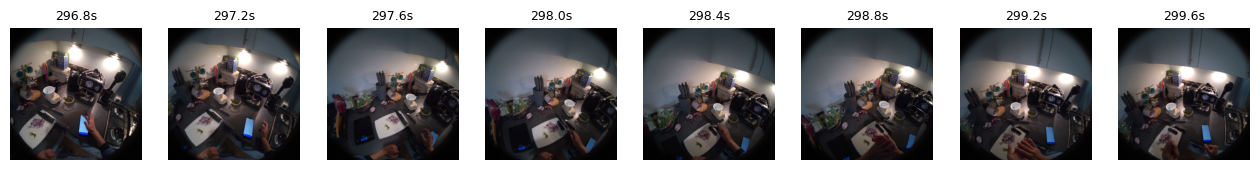

In [5]:
import cv2, numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)
step = int(fps / clips.FPS)                       # 30 fps video -> every 3rd frame
end_frame = int(T_INSPECT * fps)
idx = np.clip(np.arange(end_frame - clips.FRAMES * step, end_frame, step), 0, None)
frames = clips.read_frames(cap, idx)
x = clips.to_tensor(frames).unsqueeze(0).to(DEVICE)   # [1, 3, 32, 256, 256]
span = clips.FRAMES * step / fps
ahead = clips.ANTICIPATION_SEC * clips.FPS * step / fps  # the predictor counts in 8 fps steps
print(f"video {fps:.0f} fps; the model sees {clips.FRAMES} frames over the last {span:.1f} s "
      f"({T_INSPECT - span:.1f}-{T_INSPECT:.1f} s) and imagines ~{ahead:.1f} s past the last one")
print("input tensor", tuple(x.shape))

fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
for a, i in zip(ax, range(0, clips.FRAMES, 4)):
    a.imshow(frames[i]); a.set_title(f"{idx[i] / fps:.1f}s", fontsize=9); a.axis("off")
plt.show()

In [6]:
with torch.no_grad():
    z = model(x, torch.tensor([clips.ANTICIPATION_SEC], device=DEVICE))
n_pred = model.grid_size ** 2 * (model.num_output_frames // model.tubelet_size)
z_now, z_future = z[:, :-n_pred], z[:, -n_pred:]
print("model output      ", tuple(z.shape), "= encoder tokens + predicted tokens")
print("state now (encoder)", tuple(z_now.shape), f"= {clips.FRAMES // model.tubelet_size} time slices x {model.grid_size}x{model.grid_size} patches")
print("predicted state    ", tuple(z_future.shape), "= one future time slice")

/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


model output       (1, 4352, 1024) = encoder tokens + predicted tokens
state now (encoder) (1, 4096, 1024) = 16 time slices x 16x16 patches
predicted state     (1, 256, 1024) = one future time slice


In [7]:
import pandas as pd
from coach.data.vocab import Vocab
from coach.render.guide_video import action_names
from coach.data.extractors import HDEpicExtractor

vocab = Vocab.load()
hd = HDEpicExtractor(vocab)
NAMES = {"verb": sorted(vocab.verb_row, key=vocab.verb_row.get),
         "noun": sorted(vocab.noun_row, key=vocab.noun_row.get), "action": action_names()}

def read(tokens):
    with torch.no_grad():
        return {k: torch.sigmoid(v[0].float()).cpu().numpy() for k, v in probe(tokens).items()}

def top5(p, kind):
    return ", ".join(f"{NAMES[kind][j]} {p[j]:.2f}" for j in np.argsort(-p)[:5])

with_pred, now_only = read(z), read(z_now)
display(pd.DataFrame({"now + predicted (what the guide uses)": [top5(with_pred[k], k) for k in NAMES],
                      "now only (no predictor)": [top5(now_only[k], k) for k in NAMES]}, index=list(NAMES)))

narr = hd.narr[hd.narr.video_id == VIDEO_ID]
t_true = T_INSPECT + ahead
now = narr[(narr.start_timestamp <= t_true) & (narr.end_timestamp >= t_true)]
print(f"HD-EPIC narration at {t_true:.1f} s:", "; ".join(now.narration) or "(nothing annotated)")

/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


,now + predicted (what the guide uses),now only (no predictor)
verb,"open 0.45, take 0.21, put 0.18, turn-off 0.16,...","open 0.47, take 0.25, put 0.18, turn-off 0.15,..."
noun,"cupboard 0.46, glass 0.18, light 0.17, fridge ...","cupboard 0.47, fridge 0.19, glass 0.18, light ..."
action,"open cupboard 0.44, open fridge 0.20, take sal...","open cupboard 0.42, open fridge 0.20, take sal..."


HD-EPIC narration at 300.8 s: (nothing annotated)


## 6. 整部影片：每秒一次預測
**輸入**：影片。**輸出**：`PRED`（`.npz`）：`t`（每次預測的時間）、`verb [T, 97]`、`noun [T, 289]`、`action [T, 3568]` 機率。

影片從頭到尾解碼一次，保留最近 32 張 frame，每 `STRIDE` 秒送一次進模型。T4 上整部 P08（877 秒）約 30 分鐘。已有檔案就直接讀取；要重算請把 `RERUN` 設成 `True`。

In [8]:
from coach.perception import precompute
RERUN = False
if RERUN or not PRED.exists():
    precompute.run(VIDEO, PRED, STRIDE, DEVICE, BATCH, END)
pred = dict(np.load(PRED))
print({k: v.shape for k, v in pred.items() if k != "fps"})
display(pd.DataFrame({"t": pred["t"][:8].round(1),
                      "top verb": [NAMES["verb"][j] for j in pred["verb"][:8].argmax(1)],
                      "top noun": [NAMES["noun"][j] for j in pred["noun"][:8].argmax(1)],
                      "top action": [NAMES["action"][j] for j in pred["action"][:8].argmax(1)]}))

{'t': (877,), 'verb': (877, 97), 'noun': (877, 289), 'action': (877, 3568)}


,t,top verb,top noun,top action
0,3.2,check,phone,open cupboard
1,4.2,close,phone,close cupboard
2,5.2,put,phone,put phone
3,6.2,put,phone,put phone
4,7.2,take,phone,put phone
5,8.2,open,fridge,open fridge
6,9.2,open,fridge,open fridge
7,10.2,take,box,take box


## 7. 食譜步驟
**輸入**：HD-EPIC 的 `complete_recipes.json`。**輸出**：`texts`，也就是食譜原文的步驟。沒有用到模型。

（第 7–11 段不需要 GPU。只要有第 6 段的 `.npz`，本機也能跑。本機要先跑第 1、2 段，以及第 5 段第三格裡載入 `vocab` / `hd` / `NAMES` 的部分。）

In [9]:
if "hd" not in globals():  # stage 5 was skipped (e.g. running locally without torch)
    import numpy as np, pandas as pd
    import matplotlib.pyplot as plt
    from coach.data.vocab import Vocab
    from coach.render.guide_video import action_names
    from coach.data.extractors import HDEpicExtractor
    vocab = Vocab.load()
    hd = HDEpicExtractor(vocab)
    NAMES = {"verb": sorted(vocab.verb_row, key=vocab.verb_row.get),
             "noun": sorted(vocab.noun_row, key=vocab.noun_row.get), "action": action_names()}
    pred = dict(np.load(PRED))

hd_steps = hd.extract_steps(RECIPE)
texts = [s.text for s in hd_steps]
name = hd.recipes[RECIPE]["name"]
print(name)
for k, t in enumerate(texts, 1):
    print(f"{k}. {t}")

Scrambled Eggs
1. Crack the eggs into a medium bowl. Whisk until smooth and combined, with no streaks of egg white remaining.
2. Spray olive oil in a small nonstick skillet. Bring to medium heat.
3. Add chopped red onions and finger chillies to a pan and saute until soft
4. Pour in the eggs, and let them cook for a few seconds without stirring. Pull a rubber spatula across the bottom of the pan to form large, soft curds of scrambled eggs.
5. Continue cooking over medium-low heat, folding and stirring the eggs every few seconds. Scrape the spatula along the bottom and sides of the pan often to form more curds and to prevent any part of the eggs from drying out
6. Remove the pan from the heat when the eggs are mostly set, but a little liquid egg remains. Season to taste with salt and pepper.
7. Add cottage cheese to plate and season to taste with salt, pepper, oregano and olive oil.


## 8. VLM：每一步的手部動作標籤
**輸入**：菜名 + 第 7 段的步驟文字（**不看影片**）。**輸出**：`steps`，每一步 3–6 組 Probe 認得的「動詞 名詞」。

- `USE_VLM = True`：呼叫 NVIDIA NIM 上的 Llama 3.2 90B Vision（約 30–120 秒），需要 `NVIDIA_API_KEY`（會跳出輸入框，不會存進 notebook）。
- `USE_VLM = False`：讀取 demo 頁使用的那份結果（只適用 P08_R03）。
- `STEP_TAGS = "hdepic"`：改用 HD-EPIC 標註者在**這部影片**裡記下的動作當標籤（等於先看過答案，是樂觀的參考上限）；第 26 段的結果檔名會多 `_hdtags`，不會蓋掉 VLM 版本。

In [10]:
import getpass, json
from coach.data.extractors import ManualRecipeExtractor, NIMRecipeExtractor
from coach.data.vocab import class_frequencies

STEP_TAGS = "vlm"   # "vlm": tags written from the recipe text (works for any new recipe)
                    # "hdepic": the actions HD-EPIC's annotators saw in THIS video (an optimistic reference)
USE_VLM = False
SAVED = ROOT / f"data/processed/steps_{RECIPE}.json"   # tags the VLM wrote for this recipe in an earlier run
if not SAVED.exists():
    SAVED = ROOT / "data/processed/nim_hand_P08_R03.json"   # the scrambled eggs' tags (the demo page's first dish)
TAGS_SUFFIX = "" if STEP_TAGS == "vlm" else "_hdtags"   # keeps the two versions' results apart (stage 26)
if STEP_TAGS == "hdepic":
    steps = hd_steps
    STEPS_JSON = ROOT / f"data/processed/steps_hdepic_{RECIPE}.json"
    STEPS_JSON.write_text(json.dumps({"aligned_to": RECIPE, "source": "HD-EPIC annotations", "steps": [
        {"id": s.step_id, "text": s.text, "pairs": [[v, n] for v, n, _ in s.pairs]} for s in steps]}, indent=1))
elif USE_VLM:
    if not os.environ.get("NVIDIA_API_KEY"):
        env = ROOT / ".env"
        line = [l for l in env.read_text().splitlines() if l.startswith("NVIDIA_API_KEY=")] if env.exists() else []
        os.environ["NVIDIA_API_KEY"] = line[0].split("=", 1)[1].strip() if line else getpass.getpass("NVIDIA_API_KEY: ")
    from coach.domain import StepSpec
    VLM_CHUNK = 8  # long recipes go in chunks: for 15 steps the VLM kept returning 16 tag lists

    def tag_chunk(chunk: list[str]) -> list:
        for attempt in range(3):  # a wrong count is usually a one-off: ask again
            vlm = NIMRecipeExtractor(vocab, hand_level=True, frequencies=class_frequencies())
            try:
                return vlm, vlm.tag_steps(name, chunk)
            except ValueError as e:
                print(f"attempt {attempt + 1}: {e}")
        raise RuntimeError("the VLM did not return one tag list per step in 3 attempts")

    steps = []
    for start in range(0, len(texts), VLM_CHUNK):
        vlm, part = tag_chunk(texts[start:start + VLM_CHUNK])
        steps += [StepSpec(f"S{start + k + 1:02d}", s.text, start + k, s.pairs) for k, s in enumerate(part)]
    if len(texts) > VLM_CHUNK:
        print(f"{len(texts)} steps tagged in {-(-len(texts) // VLM_CHUNK)} chunks of up to {VLM_CHUNK}")
    print("synonyms rewritten:", [f"{a} -> {b}" for _, a, b in vlm.mapped])
    print("dropped (not in the probe's vocabulary):", vlm.rejected)
    STEPS_JSON = ROOT / f"data/processed/steps_{RECIPE}.json"
    STEPS_JSON.write_text(json.dumps({"aligned_to": RECIPE, "steps": [
        {"id": s.step_id, "text": s.text, "pairs": [[v, n] for v, n, _ in s.pairs]} for s in steps]}, indent=1))
else:
    STEPS_JSON = SAVED
    steps = ManualRecipeExtractor(vocab).extract_steps(str(SAVED))
for s in steps:
    print(f"{s.order + 1}. " + ", ".join(f"{v} {n}" for v, n, _ in s.pairs))

1. take bowl, take egg, break egg, put egg, take whisk, mix egg
2. take bottle, spray oil, put bottle, take pan, put pan
3. take knife, take onion, cut onion, put onion, take chilli, cut chilli
4. take spatula, pour egg, move spatula
5. move spatula, scrape spatula, put spatula
6. remove pan, take salt, sprinkle salt, take pepper, sprinkle pepper
7. take plate, take cheese, put cheese, take oregano, sprinkle oregano, take oil, spray oil


## 9. Action Bank
**輸入**：`steps`。**輸出**：兩個矩陣 `V [步驟數, 97]`、`Nn [步驟數, 289]`：每一步的動詞、名詞分布（各列加總為 1，另外均勻分 2% 給所有詞，避免沒列到的詞讓分數歸零）。

In [11]:
from coach.perception.action_bank import ActionBankRepository
bank = ActionBankRepository(vocab).from_steps(steps)
V, Nn = bank.get_batched_embeddings()
print("V", V.shape, " Nn", Nn.shape)
for k in range(len(steps)):
    tv = ", ".join(f"{NAMES['verb'][j]} {V[k, j]:.2f}" for j in np.argsort(-V[k])[:3])
    tn = ", ".join(f"{NAMES['noun'][j]} {Nn[k, j]:.2f}" for j in np.argsort(-Nn[k])[:3])
    print(f"step {k + 1}: verbs {tv} | nouns {tn}")

V (7, 97)  Nn (7, 289)
step 1: verbs take 0.49, put 0.16, mix 0.16 | nouns egg 0.65, whisk 0.16, bowl 0.16
step 2: verbs take 0.39, put 0.39, spray 0.20 | nouns pan 0.39, bottle 0.39, oil 0.20
step 3: verbs take 0.49, cut 0.33, put 0.16 | nouns onion 0.49, chilli 0.33, knife 0.16
step 4: verbs take 0.33, pour 0.33, move 0.33 | nouns spatula 0.65, egg 0.33, raspberry 0.00
step 5: verbs put 0.33, move 0.33, scrape 0.33 | nouns spatula 0.98, raspberry 0.00, airer 0.00
step 6: verbs take 0.39, sprinkle 0.39, remove 0.20 | nouns pepper 0.39, salt 0.39, pan 0.20
step 7: verbs take 0.56, put 0.14, sprinkle 0.14 | nouns cheese 0.28, oregano 0.28, oil 0.28


## 10. Step Tracker
**輸入**：第 6 段的每秒預測 + 第 9 段的矩陣。**輸出**：每秒的「目前步驟」，以及和 HD-EPIC 標註比較的準確率。

每秒：
1. 比對分數 = log(預測動詞 · V) + log(預測名詞 · Nn)
2. 加上 0.3 × 順序先驗（留在原步驟 0.45，下一步 0.35）
3. softmax
4. 新步驟領先 0.15 以上、連續 2 秒才切換

準確率的算法：每一秒，把 Tracker 認為的步驟，和標註中 1 秒後正在進行的步驟比較。只計算有標註步驟的秒數。下面同時列出用 HD-EPIC 標註當標籤的版本當參考（偏樂觀，因為標籤來自同一部影片）。

,these steps (stage 8),HD-EPIC annotated tags (reference)
ticks_with_annotated_step,391.000,391.000
step_accuracy,0.504,0.575
chance,0.156,0.156
pauses,26.000,20.000
step_starts,7.000,7.000
starts_with_a_pause_within_10s,5.000,5.000


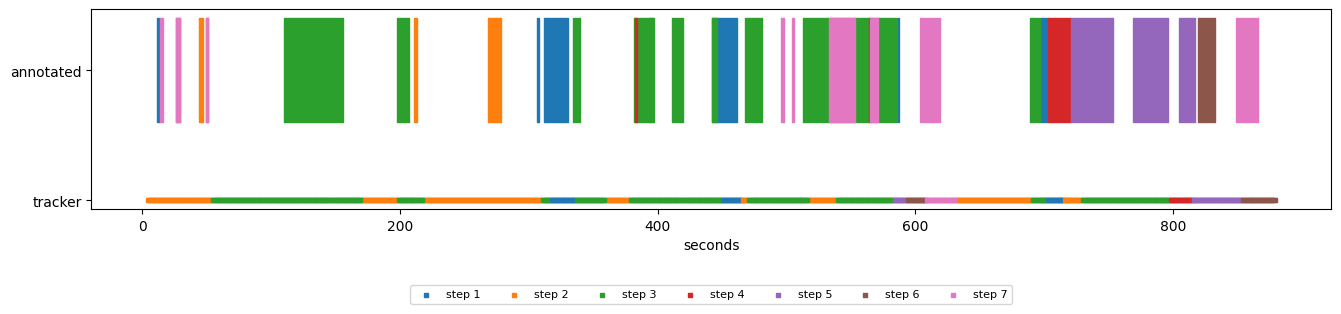

In [12]:
from coach.render.guide_video import evaluate, replay, truth_steps
truth = truth_steps(hd, RECIPE, VIDEO_ID)
results = replay(bank, pred)
current = np.array([r.extras["current"] for r in results])
ref = replay(ActionBankRepository(vocab).from_steps(hd_steps), pred)
display(pd.DataFrame({"these steps (stage 8)": evaluate(results, pred["t"], truth, len(steps)),
                      "HD-EPIC annotated tags (reference)": evaluate(ref, pred["t"], truth, len(steps))}))

fig, ax = plt.subplots(figsize=(16, 2.6))
colours = plt.cm.tab10(np.arange(len(steps)))
for k, s0, s1 in truth:
    ax.broken_barh([(s0, s1 - s0)], (1.1, 0.8), color=colours[k])
for k in range(len(steps)):
    on = current == k
    ax.scatter(pred["t"][on], np.full(on.sum(), 0.5), color=colours[k], s=6, marker="s", label=f"step {k + 1}")
ax.set_yticks([0.5, 1.5], ["tracker", "annotated"]); ax.set_xlabel("seconds")
ax.legend(ncol=len(steps), fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.35))
plt.show()

## 11. 檢查單一秒
**輸入**：`T_INSPECT` 那一秒的預測。**輸出**：每一步的比對分數、順序先驗、最後的機率，以及 Tracker 的決定。

In [13]:
from coach.perception.scorer import PRIOR_WEIGHT, match_scores, order_prior, softmax
i = int(np.searchsorted(pred["t"], T_INSPECT))
prev = int(current[i - 1]) if i else -1
m = match_scores(bank, pred["verb"][i:i + 1].astype(float), pred["noun"][i:i + 1].astype(float))[0]
prior = PRIOR_WEIGHT * order_prior(len(steps), prev)
display(pd.DataFrame({"step": [s.text[:60] for s in steps], "match": m.round(2), "prior x0.3": prior.round(2),
                      "posterior": softmax(m + prior).round(3)}, index=range(1, len(steps) + 1)))
print(f"t = {pred['t'][i]:.1f}s, step before: {prev + 1 or 'not started'}, tracker now: {current[i] + 1}, "
      f"annotated 1 s later: {sorted(k + 1 for k, s0, s1 in truth if s0 <= pred['t'][i] + 1 <= s1) or 'none'}")

,step,match,prior x0.3,posterior
1,Crack the eggs into a medium bowl. Whisk until...,-9.11,-0.97,0.063
2,Spray olive oil in a small nonstick skillet. B...,-8.20,-0.24,0.322
3,Add chopped red onions and finger chillies to ...,-8.56,-0.31,0.209
4,"Pour in the eggs, and let them cook for a few ...",-9.08,-0.97,0.065
5,"Continue cooking over medium-low heat, folding...",-9.11,-0.97,0.063
6,Remove the pan from the heat when the eggs are...,-8.52,-0.97,0.113
7,Add cottage cheese to plate and season to tast...,-8.14,-0.97,0.166


t = 300.2s, step before: 2, tracker now: 2, annotated 1 s later: none


## 12. Latency：能不能即時？
**輸入**：第 5 段的 32 張 frame 與 `x`。**輸出**：每個環節的中位數耗時（10 次），以及 `WM_LATENCY`（一次預測的秒數）。

- 即時的條件：一次預測（前處理 + 模型）要比 `STRIDE` 短，否則預測會越來越落後。
- fp16（`torch.autocast`）在 T4 的 tensor core 上通常快 2–3 倍；同時檢查 fp16 的前 5 名動詞/名詞是否和 fp32 一樣。
- 現場攝影機不需要「解碼影片檔」，每秒只要前處理新進的 ~10 張 frame；這裡也列出 32 張全部重做的上限。

In [14]:
ant = torch.tensor([clips.ANTICIPATION_SEC], device=DEVICE)

def world_model(half: bool, batch: int = 1):
    xb = x.expand(batch, -1, -1, -1, -1)
    def run():
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=half):
            return probe(model(xb, ant.expand(batch)))
    return run

new_frames = int(round(STRIDE * fps / step))  # frames that arrive per tick
lat = {
    "preprocess 32 frames (upper bound)": timed(lambda: clips.to_tensor(frames).to(DEVICE), n=5),
    f"preprocess {new_frames} new frames (live camera)": timed(lambda: clips.to_tensor(frames[:new_frames]).to(DEVICE), n=5),
    "encoder + predictor + probe, fp32": timed(world_model(False)),
    "encoder + predictor + probe, fp16": timed(world_model(True)),
    "same, fp16, batch 4 (per clip)": timed(world_model(True, 4), n=5) / 4,
}
display(pd.DataFrame({"seconds": [round(v, 3) for v in lat.values()]}, index=list(lat)))

o32, o16 = world_model(False)(), world_model(True)()
same = {k: len(set(o32[k][0].float().topk(5).indices.tolist()) & set(o16[k][0].float().topk(5).indices.tolist()))
        for k in ("verb", "noun")}
print(f"fp16 vs fp32: top-5 overlap verbs {same['verb']}/5, nouns {same['noun']}/5")

WM_HALF = same["verb"] >= 4 and same["noun"] >= 4 and lat["encoder + predictor + probe, fp16"] < lat["encoder + predictor + probe, fp32"]
WM_LATENCY = lat[f"preprocess {new_frames} new frames (live camera)"] + lat[f"encoder + predictor + probe, {'fp16' if WM_HALF else 'fp32'}"]
print(f"one live tick = {WM_LATENCY:.2f} s ({'fp16' if WM_HALF else 'fp32'}); "
      f"real time at STRIDE={STRIDE:g} s: {'yes' if WM_LATENCY < STRIDE else 'no'}; "
      f"fastest possible stride ~{WM_LATENCY:.1f} s")

/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


,seconds
preprocess 32 frames (upper bound),0.084
preprocess 10 new frames (live camera),0.019
"encoder + predictor + probe, fp32",1.777
"encoder + predictor + probe, fp16",0.471
"same, fp16, batch 4 (per clip)",0.487


/usr/lib/python3.13/contextlib.py:109: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


fp16 vs fp32: top-5 overlap verbs 5/5, nouns 5/5
one live tick = 0.49 s (fp16); real time at STRIDE=1 s: yes; fastest possible stride ~0.5 s


## 13. Coach 的輸入（不看未來）
**輸入**：食譜（第 7 段）、Actions Bank（第 8 段）、每秒預測（第 6 段）、Step Tracker（第 10 段）。**輸出**：`coach_prompt(t)`，在時間 `t` 給 Coach 的完整文字。

只用 `t` 以前的資料：
- **做過的動作**：過去每秒預測的第 1 名動作，連續相同的合併成一段，例如 `12–19 s take egg`，保留最近 `N_RUNS` 段。
  `HISTORY = "annotations"` 改用 HD-EPIC 標註者記錄的動作（標準答案，用來比較 Coach 在「看得準」時的表現）。
- **現在**：約 0.8 秒後的前 3 名預測動作，以及 Step Tracker 判斷的目前步驟。

In [15]:
T_COACH = 240.0          # the moment to coach (seconds)
HISTORY = "model"        # "model" = what V-JEPA 2 predicted; "annotations" = HD-EPIC narrations (oracle)
N_RUNS = 30              # how many past action runs go into the prompt
COACH_LANGUAGE = "English"

def history(t_end: float) -> list[str]:
    if HISTORY == "annotations":
        rows = hd.narr[(hd.narr.video_id == VIDEO_ID) & (hd.narr.end_timestamp <= t_end)].sort_values("start_timestamp")
        out = [f"{r.start_timestamp:.0f}-{r.end_timestamp:.0f} s: {r.narration.strip()}" for r in rows.itertuples()]
        return out[-N_RUNS:]
    keep = np.flatnonzero(pred["t"] <= t_end)
    assert all(pred["t"][keep] <= t_end), "history must not see the future"
    runs = []
    for i in keep:
        label = NAMES["action"][int(pred["action"][i].argmax())]
        if runs and runs[-1][2] == label:
            runs[-1][1] = pred["t"][i]
        else:
            runs.append([pred["t"][i], pred["t"][i], label])
    return [f"{a:.0f}-{b:.0f} s: {lab}" for a, b, lab in runs][-N_RUNS:]

def moment(t: float) -> int:
    """Index of the last prediction made at or before t."""
    return max(0, int(np.searchsorted(pred["t"], t, side="right")) - 1)

def coach_prompt(t: float) -> str:
    i = moment(t)
    p = pred["action"][i].astype(float)
    now = ", ".join(f"{NAMES['action'][j]} ({p[j]:.2f})" for j in np.argsort(-p)[:3])
    cur = int(current[i])
    recipe = "\n".join(f"{k + 1}. {s}" for k, s in enumerate(texts))
    bank = "\n".join(f"{s.order + 1}. " + ", ".join(dict.fromkeys(f"{v} {n}" for v, n, _ in s.pairs)) for s in steps)
    source = ("an action-recognition model (often wrong about objects)" if HISTORY == "model"
              else "a human annotator")
    return f"""You are a cooking coach watching a home cook through a head-mounted camera.

Recipe: {name}
{recipe}

Hand actions each step usually involves:
{bank}

What the cook has done so far, from {source}:
{chr(10).join(history(pred['t'][i]))}

Now (t = {pred['t'][i]:.0f} s) the model expects in about 1 s: {now}.
A step tracker thinks the cook is on {'step ' + str(cur + 1) if cur >= 0 else 'no step yet'} (it is right about half the time).

Answer in {COACH_LANGUAGE}, briefly, with these three headings:
Fundamentals: the 1-3 principles of this dish that matter at this moment.
Where: which step the cook is on and what is done or still missing.
Next: the single next thing the cook should do, and why (2-3 sentences)."""

T_COACH = min(T_COACH, float(pred["t"][-1]))
COACH_PROMPT = coach_prompt(T_COACH)
print(COACH_PROMPT)

You are a cooking coach watching a home cook through a head-mounted camera.

Recipe: Scrambled Eggs
1. Crack the eggs into a medium bowl. Whisk until smooth and combined, with no streaks of egg white remaining.
2. Spray olive oil in a small nonstick skillet. Bring to medium heat.
3. Add chopped red onions and finger chillies to a pan and saute until soft
4. Pour in the eggs, and let them cook for a few seconds without stirring. Pull a rubber spatula across the bottom of the pan to form large, soft curds of scrambled eggs.
5. Continue cooking over medium-low heat, folding and stirring the eggs every few seconds. Scrape the spatula along the bottom and sides of the pan often to form more curds and to prevent any part of the eggs from drying out
6. Remove the pan from the heat when the eggs are mostly set, but a little liquid egg remains. Season to taste with salt and pepper.
7. Add cottage cheese to plate and season to taste with salt, pepper, oregano and olive oil.

Hand actions each st

## 14a.（選用）在 A100 上自架 Muse Glimmer（vLLM）
**輸入**：Hugging Face 上的 `meta-models/Muse-Glimmer-30B`（Apache 2.0，59.6 GB BF16）。**輸出**：本機 `http://localhost:8000/v1` 的 OpenAI 相容服務，第 14 段的 `Glimmer self-hosted` 設定會用它。

- 全精度需要 64 GB；Colab 的 A100 是 40 GB，所以載入時線上量化成 **FP8**，並只開文字輸入（不載入影像編碼器）：權重約 28.6 GB，KV cache 還有 5.6 GB。A100 沒有原生 FP8，vLLM 用 Marlin kernel 做「只壓縮權重」。
- 預設（`GLIMMER_SHARE_GPU = False`）把剩下的記憶體都給 KV cache；要讓 d1 一起放在同一張 40 GB A100 上，設 `GLIMMER_SHARE_GPU = True`（不用 CUDA graph、一次一個請求，約省 3 GB），並在第 15 段之前啟動。
- 自架時推理強度用 chat template 的 `reasoning_strength`（low／medium／high／xhigh，預設 high），**沒有完全關閉**的選項。
- 第一次：安裝 vLLM 約 5 分鐘、下載權重約 5–10 分鐘、載入約 5 分鐘。`SELF_HOST_GLIMMER = False` 時整段跳過。

In [ ]:
SELF_HOST_GLIMMER = False      # True on an A100 or bigger GPU
GLIMMER_DIR = Path("/content/glimmer/weights")
GLIMMER_URL = "http://localhost:8000/v1"
GLIMMER_SHARE_GPU = False      # True: leave ~5 GB of a 40 GB A100 for d1 (start Glimmer before loading d1)
GLIMMER_EAGER = False          # with GLIMMER_SHARE_GPU: True skips CUDA graphs (less memory, ~4x slower answers)

def glimmer_up() -> bool:
    import urllib.request
    try:
        urllib.request.urlopen(GLIMMER_URL + "/models", timeout=5)
        return True
    except Exception:
        return False

if SELF_HOST_GLIMMER and not glimmer_up():
    import importlib.util, subprocess
    if importlib.util.find_spec("vllm") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "vllm", "hf_transfer"], check=True)
    if not (GLIMMER_DIR / "config.json").exists():
        subprocess.run(["hf", "download", "meta-models/Muse-Glimmer-30B", "--local-dir", str(GLIMMER_DIR)], check=True,
                       env=dict(os.environ, HF_HUB_ENABLE_HF_TRANSFER="1"))
    gpu_gb = torch.cuda.get_device_properties(0).total_memory / 2**30
    if GLIMMER_SHARE_GPU:  # one request at a time, small batches; on 40 GB, 0.80 leaves ~8 GB for d1 (it uses ~4.7);
        # on 80 GB, 0.45 (36 GB) leaves room for d1 and stage 38's 11B vision model (~22 GB) as well
        util = "0.45" if gpu_gb > 70 else "0.80"
        sizing = ["--max-num-seqs", "1", "--max-num-batched-tokens", "2048", "--gpu-memory-utilization", util]
        sizing += ["--enforce-eager"] if GLIMMER_EAGER else []
    else:
        sizing = ["--max-num-seqs", "4", "--gpu-memory-utilization", "0.95"]
    log = open(GLIMMER_DIR.parent / "vllm.log", "w")
    server = subprocess.Popen(["vllm", "serve", str(GLIMMER_DIR), "--served-model-name", "glimmer", "--quantization", "fp8",
                               # sharing: 4096 tokens (a coach call is ~1.1k in + up to 1k out) leaves room for CUDA graphs
                               "--max-model-len", "4096" if GLIMMER_SHARE_GPU else "8192", "--port", "8000", *sizing,
                               # text only: skips the image encoder (28.6 instead of 32.8 GB, 5.6 GB left for KV cache)
                               "--limit-mm-per-prompt", '{"image": 0, "video": 0}'],
                              stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    t0 = time.time()
    while not glimmer_up() and server.poll() is None and time.time() - t0 < 1200:
        time.sleep(10)
    if server.poll() is not None:  # vLLM gave up (usually GPU memory): show why instead of waiting
        print((GLIMMER_DIR.parent / "vllm.log").read_text()[-1500:])
print("self-hosted Glimmer:", "up at " + GLIMMER_URL if glimmer_up() else "off")

## 14. Coach AI（NVIDIA NIM）
**輸入**：第 13 段的 `COACH_PROMPT`。**輸出**：`coach_text`（建議）、`coach_thinking`（模型的推理過程）、`COACH_LATENCY`（秒）。

`COACH_CONFIGS` 列出 Muse Glimmer 的可選設定（推理開／低／關、max_tokens），`COACH_CONFIG` 是目前使用的那一個；第 17 段會比較全部設定並自動選出 `COACH_CHOICE`。
Glimmer 是 reasoning model：先產生推理（`reasoning_content`），再給答案；延遲大約和輸出 token 數成正比。
NIM 沒有完全關掉 Glimmer 推理的開關，`enable_thinking=False` + `reasoning_effort="none"` 能把推理縮到很短。
需要 `NVIDIA_API_KEY`（讀 `.env` 或跳出輸入框，不會存進 notebook）。

In [16]:
import getpass, importlib.util, subprocess, time
if importlib.util.find_spec("openai") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openai"], check=True)
from openai import OpenAI

if not os.environ.get("NVIDIA_API_KEY"):
    env = ROOT / ".env"
    line = [l for l in env.read_text().splitlines() if l.startswith("NVIDIA_API_KEY=")] if env.exists() else []
    os.environ["NVIDIA_API_KEY"] = line[0].split("=", 1)[1].strip() if line else getpass.getpass("NVIDIA_API_KEY: ")

GLIMMER = "meta/muse-glimmer-30b"
NO_THINKING = {"chat_template_kwargs": {"enable_thinking": False}, "reasoning_effort": "none"}
COACH_CONFIGS = {  # name -> model, max_tokens, extra request fields; all Muse Glimmer, varying reasoning and length
    "Glimmer, reasoning on, 8192 tok": dict(model=GLIMMER, max_tokens=8192),
    "Glimmer, reasoning on, 2048 tok": dict(model=GLIMMER, max_tokens=2048),
    "Glimmer, reasoning on, 1024 tok": dict(model=GLIMMER, max_tokens=1024),
    "Glimmer, reasoning low, 1024 tok": dict(model=GLIMMER, max_tokens=1024, extra={"reasoning_effort": "low"}),
    "Glimmer, reasoning off, 1024 tok": dict(model=GLIMMER, max_tokens=1024, extra=NO_THINKING),
    "Glimmer, reasoning off, 512 tok": dict(model=GLIMMER, max_tokens=512, extra=NO_THINKING),
}
if "glimmer_up" in globals() and glimmer_up():  # stage 14a: Glimmer served on this machine (FP8 on an A100)
    COACH_CONFIGS["Glimmer self-hosted, reasoning low, 1024 tok"] = dict(
        model="glimmer", max_tokens=1024, local=True, extra={"chat_template_kwargs": {"reasoning_strength": "low"}, "skip_special_tokens": False})
COACH_CONFIG = "Glimmer, reasoning low, 1024 tok"
client = OpenAI(base_url="https://integrate.api.nvidia.com/v1", api_key=os.environ["NVIDIA_API_KEY"], timeout=900)
local_client = OpenAI(base_url=GLIMMER_URL, api_key="none", timeout=900) if "GLIMMER_URL" in globals() else None

def coach(prompt: str, config: str | None = None) -> tuple[str, str, float, dict]:
    cfg = COACH_CONFIGS[config or COACH_CONFIG]
    t0 = time.perf_counter()
    c = (local_client if cfg.get("local") else client).chat.completions.create(model=cfg["model"], messages=[{"role": "user", "content": prompt}],
                                       temperature=1, top_p=0.95, max_tokens=cfg["max_tokens"], stream=False,
                                       extra_body=cfg.get("extra") or None)
    m = c.choices[0].message
    thinking = getattr(m, "reasoning_content", None) or (m.model_extra or {}).get("reasoning_content") or ""
    text = m.content or ""
    if "to=user<|message|>" in text:  # self-hosted: "<reasoning><|eom|><|start|>assistant to=user<|message|><answer>"
        thinking, text = text.split("to=user<|message|>", 1)
        thinking = thinking.split("<|message|>", 1)[-1].replace("<|eom|>", "").replace("<|start|>assistant", "")
        text = text.replace("<|eom|>", "").replace("<|end|>", "")
    return text.strip(), thinking.strip(), time.perf_counter() - t0, c.usage.model_dump()

coach_text, coach_thinking, COACH_LATENCY, usage = coach(COACH_PROMPT)
print(f"{COACH_CONFIG}: {COACH_LATENCY:.1f} s, {usage['prompt_tokens']} prompt + {usage['completion_tokens']} completion tokens\n")
print(coach_text)
print("\n--- reasoning (first 1500 characters) ---\n" + coach_thinking[:1500])

447.2 s, 800 prompt + 2049 completion tokens

**Fundamentals:** 
The dish is about a smooth egg base and gentle heat. Eggs must be fully whisked to no streaks before cooking for even curds. The pan needs oil and medium heat first, then aromatics softened, and the eggs finished off heat with a little liquid remaining to avoid dry rubbery curds. Focus is critical because scrambled eggs overcook in seconds.

**Where:**
The step tracker says step 2, but the evidence does not support it. There is no take bowl / take egg / break egg / whisk actions for step 1, and no clear take pan / put pan / heat actions for step 2. The log is dominated by take phone / put phone / check phone and mis-labelled actions such as put cucumber / cut cucumber, serve biscuit, open cupboard, take salt. At best a veg chopping action may be happening, probably onion/chilli mis-labelled as cucumber, but the core of step 1 is missing and step 2 is not verified. The cook is effectively off-task / pre-step 1.

**Next:**


## 15. Decision Model：Liquid AI d1-2B
**輸入**：Coach 的推理與建議 + Actions Bank。**輸出**：下一個動作（Actions Bank 裡每個動作的機率）、下一步、是否該開口提醒；`D1_LATENCY`（秒）。

d1 不是聊天模型：它讀一段 state 和幾個「問題」，一次 forward 就回傳每個選項的機率，不生成文字，所以很快。
- `next_action`：選擇題，選項 = Actions Bank 的每個「步驟：動詞 名詞」
- `next_step`：選擇題，選項 = 7 個步驟
- `should_speak`：是非題，Coach 是否認為現在要提醒使用者做改變

模型卡建議 bf16；T4 不支援 bf16，所以先試 fp16，結果不正常再改 fp32（約 7.7 GB，和 V-JEPA 2 一起放得進 T4）。

In [17]:
from importlib.metadata import version, PackageNotFoundError
def _major_minor(v): return tuple(int(p) for p in v.split(".")[:2])
try:
    need = _major_minor(version("transformers")) < (5, 19)
except PackageNotFoundError:
    need = True
if need:  # coach never imports transformers, so the fresh install loads without a restart
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers>=5.19"], check=True)
# coach.perception.anticipate puts a stand-in "timm" in sys.modules to load V-JEPA 2; transformers checks for timm
# with importlib and fails on the stand-in, so drop it (V-JEPA 2 is already loaded and keeps working)
for m in [m for m in sys.modules if m == "timm" or m.startswith("timm.")]:
    if getattr(sys.modules[m], "__spec__", None) is None:
        del sys.modules[m]
from transformers import AutoModel

D1_INCLUDE_THINKING = True   # give d1 the coach's reasoning as well as its answer
if globals().get("D1") is not None:  # already loaded (e.g. a second video): only the recipe's options below change
    print("d1 already loaded in", D1_DTYPE)
for dt in (torch.float16, torch.float32) if globals().get("D1") is None else ():
    try:
        D1 = AutoModel.from_pretrained("LiquidAI/d1-2B", trust_remote_code=True, dtype=dt).to(DEVICE).eval()
        probe_q = {"ok": {"type": "noul", "instructions": "Is the cook handling eggs?"}}
        if np.isfinite(D1.system_one("The cook is whisking eggs in a bowl.", probe_q)["answers"]["ok"]["noul"]):
            D1_DTYPE = dt
            break
    except Exception as e:
        print(f"d1 in {dt} failed: {type(e).__name__}: {e}")
    D1 = None
assert D1 is not None, "d1 did not load"
print("d1 ready,", D1_DTYPE)

ACTIONS = {}  # Actions Bank as d1 choices: "s3_cut_onion" -> "Step 3 (Add chopped red onions…): cut onion"
for s in steps:
    for v, n, _ in s.pairs:
        ACTIONS.setdefault(f"s{s.order + 1}_{v}_{n}".replace(" ", "_").replace(":", "_"),
                           f"Step {s.order + 1} ({s.text[:45]}…): {v} {n}")
STEP_CHOICES = {f"step{k + 1}": t for k, t in enumerate(texts)}
D1_QUESTIONS = {
    "next_action": {"type": "choice", "instructions": "Which action should the cook do next, following the coach?",
                    "criteria": ACTIONS},
    "next_step": {"type": "choice", "instructions": "Which recipe step should the cook do next?",
                  "criteria": STEP_CHOICES},
    "should_speak": {"type": "noul",
                     "instructions": "Does the coach say the cook should change or start something now, rather than keep going?"},
}

def d1_state(t: float, advice: str, thinking: str) -> dict:
    i = moment(t)
    state = {"time_s": round(float(pred["t"][i])), "tracker_step": int(current[i]) + 1,
             "predicted_next_actions": [NAMES["action"][j] for j in np.argsort(-pred["action"][i].astype(float))[:3]],
             "coach_advice": advice}
    if D1_INCLUDE_THINKING:
        state["coach_reasoning"] = thinking[-6000:]
    return state

def decide(state: dict) -> dict:
    with torch.no_grad():
        return D1.system_one(state, D1_QUESTIONS)["answers"]

state = d1_state(T_COACH, coach_text, coach_thinking)
ans = decide(state)
D1_LATENCY = timed(lambda: decide(state), n=10)
top = sorted(ans["next_action"]["probabilities"].items(), key=lambda kv: -kv[1])[:3]
print(f"d1: {D1_LATENCY * 1000:.0f} ms per decision\n")
print("next action:", "; ".join(f"{ACTIONS[k].split(': ')[-1]} [{k.split('_')[0]}] {p:.2f}" for k, p in top))
print("next step:  ", ans["next_step"]["choice"], f"(confidence {ans['next_step']['confidence']:.2f})")
print("speak now:  ", f"P = {ans['should_speak']['noul']:.2f}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/2.90k [00:00<?, ?B/s]

native_lfm3_vl.py:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

video_processing_lfm3_vl.py:   0%|          | 0.00/18.2k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-2B:
- video_processing_lfm3_vl.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


configuration_lfm3_vl.py:   0%|          | 0.00/9.89k [00:00<?, ?B/s]

... (54 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/12.7k [00:00<?, ?B/s]

d1 loaded in torch.float16


d1: 1095 ms per decision

next action: take egg [s1] 0.41; take bowl [s1] 0.15; spray oil [s2] 0.07
next step:   step1 (confidence 0.73)
speak now:   P = 0.95


## 16. 多久給一次建議？
**輸入**：第 12、14、15 段量到的延遲，以及第 10 段 Step Tracker 在整部影片上的切換時間。**輸出**：延遲總表、三種建議頻率的比較、建議做法，以及 3 次真實的 Coach + d1 範例。

比較的頻率策略：每 10 秒、每 30 秒、Step Tracker 切換步驟時。Coach 一次只能處理一個請求，所以實際間隔不會短於 `COACH_LATENCY`。
「延遲」= 從 Step Tracker 切換步驟，到使用者收到下一則建議的時間。

In [18]:
tick = max(STRIDE, WM_LATENCY)
display(pd.DataFrame({"seconds": [round(WM_LATENCY, 2), round(COACH_LATENCY, 1), round(D1_LATENCY, 3)],
                      "can run every": [f"{tick:.1f} s", f"{COACH_LATENCY:.0f} s at most", f"tick ({tick:.1f} s)"]},
                     index=["World Model (one tick)", "Coach AI (Glimmer)", "Decision Model (d1)"]))

t0, t1 = float(pred["t"][0]), float(pred["t"][-1])
changes = [r.timestamp for r in results if r.should_pause]

def schedule(policy) -> list[float]:
    """Times the coach is called; one call at a time, so calls never start before the last one finished."""
    wants = changes if policy == "on step change" else list(np.arange(t0, t1, policy))
    calls, free = [], t0
    for w in wants:
        if w >= free:
            calls.append(w)
            free = w + COACH_LATENCY
    return calls

rows = {}
for policy in (10.0, 30.0, "on step change"):
    calls = schedule(policy)
    delays = [min((c + COACH_LATENCY for c in calls if c >= e), default=np.inf) - e for e in changes]
    finite = [d for d in delays if np.isfinite(d)]
    rows[f"every {policy:g} s" if policy != "on step change" else policy] = {
        "coach calls": len(calls), "calls per minute": round(len(calls) / ((t1 - t0) / 60), 1),
        "step changes answered": f"{len(finite)}/{len(changes)}",
        "median delay after a change (s)": round(float(np.median(finite)), 1) if finite else None}
display(pd.DataFrame(rows).T)
print(f"""Suggested: call the coach on events (the tracker changes step, or d1 says speak with P > 0.5),
never more often than once per {COACH_LATENCY:.0f} s; keep showing the last advice in between;
run d1 every tick ({tick:.1f} s) on the last advice + the fresh prediction to re-rank the next action.""")

,seconds,can run every
World Model (one tick),0.490,1.0 s
Coach AI (Glimmer),447.200,447 s at most
Decision Model (d1),1.095,tick (1.0 s)


,coach calls,calls per minute,step changes answered,median delay after a change (s)
every 10 s,2,0.1,11/26,589.2
every 30 s,2,0.1,11/26,589.2
on step change,2,0.1,12/26,587.2


Suggested: call the coach on events (the tracker changes step, or d1 says speak with P > 0.5),
never more often than once per 447 s; keep showing the last advice in between;
run d1 every tick (1.0 s) on the last advice + the fresh prediction to re-rank the next action.


In [19]:
# three real rounds at the first tracker step changes (or evenly spaced if there are fewer)
moments = changes[:3] if len(changes) >= 3 else list(np.linspace(t0 + 10, t1, 3))
for t in moments:
    text, thinking, sec, _ = coach(coach_prompt(t))
    a = decide(d1_state(t, text, thinking))
    best = max(a["next_action"]["probabilities"].items(), key=lambda kv: kv[1])
    nxt = text.split("Next:")[-1].strip() if "Next:" in text else text[-300:]
    print(f"t = {t:.0f} s  (coach {sec:.0f} s)  tracker step {int(current[moment(t)]) + 1}")
    print(f"  coach next: {nxt[:300]}")
    print(f"  d1: {ACTIONS[best[0]].split(': ')[-1]} [{best[0].split('_')[0]}] {best[1]:.2f}, "
          f"step {a['next_step']['choice']}, speak P={a['should_speak']['noul']:.2f}\n")

t = 4 s  (coach 215 s)  tracker step 2
  coach next: ** the single next thing the cook should do, and why
Get the eggs into a medium bowl and whisk them until smooth and streak-free before committing the pan to heat. The model is about to open a lid and the tracker is biased to step 2, but cooking begins with whisked eggs; heating oil with no eggs rea
  d1: take bowl [s1] 0.49, step step1, speak P=0.56



t = 55 s  (coach 138 s)  tracker step 3
  coach next: ** the single next thing the cook should do, and why.
Stop the unrelated fridge/drawer activity and start Step 1: take a medium bowl, crack the eggs in and whisk until smooth with no white streaks. No egg prep has been seen at all, and whisked eggs are a prerequisite for every later step, including 
  d1: take egg [s1] 0.44, step step1, speak P=0.90



t = 170 s  (coach 201 s)  tracker step 2
  coach next: ** the single next thing the cook should do, and why
Put the phone down and start the cook line: crack the eggs into a bowl and whisk until smooth, and at the same time get a small non-stick skillet on medium heat and spray with olive oil. 
Why: you have no evidence the eggs are whisked and you have
  d1: take egg [s1] 0.48, step step1, speak P=0.78



## 17. Coach 設定比較：需要推理嗎？max_tokens 可以多小？
**輸入**：`EVAL_MOMENTS` 個時間點的 Coach prompt（第 13 段，只用過去的資料），每個設定各問一次。**輸出**：每個設定的步驟正確率、是否被 `max_tokens` 截斷、延遲，以及自動選出的 `COACH_CHOICE`。

**怎麼評分**：要求 Coach 最後多寫一行 `STEP: <數字>`（現在該做哪一步）。兩份標準答案：
- **這位廚師實際做的**：這一刻正在做的步驟；不在任何步驟時（滑手機、拿東西），取接下來最先開始的步驟
- **食譜順序**：正在做的步驟，或還沒開始、編號最小的步驟（例如還沒打蛋就該先打蛋，即使這位廚師先切了洋蔥）

選擇時用「符合任一份」。對照組：Step Tracker 自己（不用 LLM）的判斷。

**怎麼選**：
1. 所有時間點都有回答（有 `STEP:` 那一行）
2. 正確率在最好的設定「差一題以內」→ 進入決選
3. 決選者各再問 `SERIAL_RUNS` 次、**一次一個**（現場就是這樣呼叫），選延遲中位數最短的

10 個問題同時送出時的延遲包含 NIM 共用端點的排隊，所以只當參考。樣本很小，temperature=1，差一兩題不代表真的比較好。
結果存到 `coach_eval_<影片>.json`，檔案已存在就直接讀（`RERUN_EVAL = True` 重問）。

In [ ]:
import concurrent.futures, re

EVAL_MOMENTS = 10
RERUN_EVAL = False
SERIAL_RUNS = 3          # one-at-a-time calls per finalist, the way the live coach would call
EVAL_FILE = ROOT / f"results/coach_eval_{VIDEO_ID}.json"
STEP_LINE = "\nFinally, on a line of its own, write STEP: <the number of the recipe step the cook should work on now>."
# measured one at a time in an earlier full run (stages 14 and 16), not worth repeating at ~5 min a call
SERIAL_KNOWN = {"Glimmer, reasoning on, 8192 tok": [447.2, 215.0, 138.0, 201.0]}

def actual_next(t: float) -> set[int]:
    """What this cook did: the step being worked on at t (+1 s), or else the next step to start."""
    now = {k for k, s0, s1 in truth if s0 <= t + 1 <= s1}
    if now:
        return now
    later = sorted((s0, k) for k, s0, s1 in truth if s0 > t)
    return {later[0][1]} if later else set()

def recipe_next(t: float) -> set[int]:
    """What the recipe says: a step in progress, or the lowest-numbered step not started yet."""
    now = {k for k, s0, s1 in truth if s0 <= t + 1 <= s1}
    started = {k for k, s0, s1 in truth if s0 <= t}
    left = [k for k in range(len(texts)) if k not in started]
    return now | ({min(left)} if left else set())

def parse_step(text: str):
    found = re.findall(r"^\W*STEP\W*(\d+)", text or "", re.I | re.M)
    return int(found[-1]) - 1 if found else None

def ask(config: str, t: float) -> dict:
    try:
        text, thinking, sec, usage = coach(coach_prompt(t) + STEP_LINE, config)
        return dict(config=config, t=t, text=text, thinking_chars=len(thinking), sec=round(sec, 1),
                    tokens=usage["completion_tokens"], step=parse_step(text), error=None)
    except Exception as e:
        return dict(config=config, t=t, text="", thinking_chars=0, sec=None, tokens=None, step=None,
                    error=f"{type(e).__name__}: {e}"[:200])

moments = [float(pred["t"][moment(t)]) for t in np.linspace(30, float(pred["t"][-1]) - 10, EVAL_MOMENTS)]
saved = json.loads(EVAL_FILE.read_text()) if EVAL_FILE.exists() and not RERUN_EVAL else {}
eval_rows = [r for r in saved.get("rows", []) if r["config"] in COACH_CONFIGS]
serial = {c: v for c, v in saved.get("serial", {}).items() if c in COACH_CONFIGS}
if eval_rows:
    print(f"loaded {len(eval_rows)} answers from {EVAL_FILE.name}")
for config in COACH_CONFIGS:
    if any(r["config"] == config for r in eval_rows):
        continue  # already asked
    t0 = time.perf_counter()
    with concurrent.futures.ThreadPoolExecutor(len(moments)) as pool:
        got = list(pool.map(lambda t: ask(config, t), moments))
    eval_rows += got
    print(f"{config:36} {time.perf_counter() - t0:6.0f} s wall, errors: {sum(r['error'] is not None for r in got)}", flush=True)
for k, r in enumerate(eval_rows):  # calls that failed under parallel load get one more try, alone
    if r["error"]:
        eval_rows[k] = ask(r["config"], r["t"])
        print(f"retried {r['config']} at {r['t']:.0f} s: {'ok' if not eval_rows[k]['error'] else eval_rows[k]['error']}")
for r in eval_rows:
    r["step"] = parse_step(r["text"])
    r["truncated"] = bool(r["tokens"] and r["tokens"] >= COACH_CONFIGS[r["config"]]["max_tokens"])

def summary_row(rows):
    ok = [r for r in rows if r["step"] is not None]
    secs = [r["sec"] for r in rows if r["sec"] is not None]
    hit = lambda f: round(float(np.mean([r["step"] in f(r["t"]) for r in rows])), 2)
    return {"answered": f"{len(ok)}/{len(rows)}", "cut off by max_tokens": sum(r["truncated"] for r in rows),
            "acc: what the cook did": hit(actual_next), "acc: recipe order": hit(recipe_next),
            "acc: either": hit(lambda t: actual_next(t) | recipe_next(t)),
            "median s (10 at once)": round(float(np.median(secs)), 1) if secs else None,
            "median output tokens": int(np.median([r["tokens"] for r in rows if r["tokens"]])) if secs else None,
            "median words": int(np.median([len(r["text"].split()) for r in ok])) if ok else None}

table = pd.DataFrame({c: summary_row([r for r in eval_rows if r["config"] == c]) for c in COACH_CONFIGS}).T
tracker_row = {"answered": f"{len(moments)}/{len(moments)}", "cut off by max_tokens": 0}
for col, f in (("acc: what the cook did", actual_next), ("acc: recipe order", recipe_next),
               ("acc: either", lambda t: actual_next(t) | recipe_next(t))):
    tracker_row[col] = round(float(np.mean([int(current[moment(t)]) in f(t) for t in moments])), 2)

# finalists: answered every moment, accuracy within one answer of the best; then time them one call at a time
full = table[table["answered"] == f"{len(moments)}/{len(moments)}"]
if full.empty:
    raise RuntimeError("no setting answered every moment; see the table")
best = full["acc: either"].max()
finalists = list(full[full["acc: either"] >= best - 1 / len(moments) - 1e-9].index)
for config in finalists:
    if config in SERIAL_KNOWN:
        serial[config] = SERIAL_KNOWN[config]
    elif len(serial.get(config, [])) < SERIAL_RUNS:
        serial[config] = [coach(coach_prompt(t) + STEP_LINE, config)[2] for t in moments[:SERIAL_RUNS]]
table["median s (one at a time)"] = [round(float(np.median(serial[c])), 1) if c in serial else None for c in table.index]
EVAL_FILE.write_text(json.dumps({"moments": moments, "rows": eval_rows, "serial": serial}, indent=1))
table.loc["Step tracker alone (no LLM)"] = pd.Series(tracker_row)
display(table)

COACH_CHOICE = min(finalists, key=lambda c: np.median(serial[c]))
COACH_CHOICE_LATENCY = float(np.median(serial[COACH_CHOICE]))
print(f"best accuracy (either answer key) {best:.2f}; within one answer of it: {', '.join(finalists)}")
print(f"COACH_CHOICE = {COACH_CHOICE!r}: the fastest of those, {COACH_CHOICE_LATENCY:.0f} s per call one at a time")
print(f"{len(moments)} moments at temperature 1: one answer = {1 / len(moments):.0%}, so 1-2 answers apart is noise")


In [ ]:
# the same moment, every setting: what does each coach actually say?
t_show = moments[len(moments) // 2]
print(f"t = {t_show:.0f} s, the cook did: step {sorted(k + 1 for k in actual_next(t_show))}, "
      f"recipe order: step {sorted(k + 1 for k in recipe_next(t_show))}, "
      f"tracker: step {int(current[moment(t_show)]) + 1}\n")
for r in eval_rows:
    if r["t"] == t_show:
        nxt = r["text"].split("Next:")[-1] if "Next:" in r["text"] else r["text"]
        nxt = " ".join(nxt.replace("*", "").split())
        print(f"[{r['config']}]  {r['sec']} s, {r['tokens']} tokens, STEP {None if r['step'] is None else r['step'] + 1}"
              f"{'  (cut off)' if r['truncated'] else ''}{'  ERROR ' + r['error'] if r['error'] else ''}\n  {nxt[:400]}\n")

## 18. 時間軸：Coach 在事件時被問、d1 每秒決定
**輸入**：整部影片的每秒預測、Coach（第 14a 段自架的 Glimmer 有開就用它，否則用第 17 段的 `COACH_CHOICE`）、d1。**輸出**：`coach_timeline_<影片>.json`：每次 Coach 呼叫（何時問、何時回來、說了什麼），以及每秒 d1 的前 3 名下一個動作、下一步、是否該提醒。

模擬「真的在現場」的情況：
- Coach 一次只能處理一個請求；Step Tracker 切換步驟、或距離上次超過 `COACH_EVERY` 秒時才再問。
- 建議要等 Coach **真的回覆後**（問的時間 + 實際延遲）才看得到。
- 每一秒，d1 讀「目前看得到的最新建議」+「這一秒 World Model 的預測」，重新排序下一個動作。

分兩步、可在不同機器上跑：(1) Coach 呼叫存成 `coach_calls_<影片>.json`；(2) d1 讀它做每秒決定。已有檔案就直接讀取（`RERUN_TIMELINE = True` 重跑）。整部 P08 約需 Coach 數十次呼叫 + d1 約 880 次決定。

In [ ]:
COACH_EVERY = 60.0
RERUN_TIMELINE = False
TIMELINE_FILE = ROOT / f"results/coach_timeline_{VIDEO_ID}.json"
D1_BATCH = 16

def next_part(text: str) -> str:
    part = text.split("Next:")[-1] if "Next:" in text else text
    return " ".join(part.replace("*", "").replace("STEP:", " STEP:").split())

CALLS_FILE = ROOT / f"results/coach_calls_{VIDEO_ID}.json"
SELF_HOSTED = "Glimmer self-hosted, reasoning low, 1024 tok"
# same model and reasoning level as stage 17's choice; served on this machine it answers 2-3x faster
TIMELINE_COACH = SELF_HOSTED if SELF_HOSTED in COACH_CONFIGS else globals().get("COACH_CHOICE", COACH_CONFIG)

if TIMELINE_FILE.exists() and not RERUN_TIMELINE:
    timeline = json.loads(TIMELINE_FILE.read_text())
    print(f"loaded {TIMELINE_FILE.name}: {len(timeline['calls'])} coach calls, {len(timeline['ticks'])} d1 decisions")
else:
    # 1. coach calls in simulated real time (can run on a different machine from d1: the result is saved)
    if CALLS_FILE.exists() and not RERUN_TIMELINE:
        saved_calls = json.loads(CALLS_FILE.read_text())
        calls, TIMELINE_COACH = saved_calls["calls"], saved_calls["coach"]
        print(f"loaded {len(calls)} coach calls ({TIMELINE_COACH}) from {CALLS_FILE.name}")
    else:
        calls, free_at, last_call, last_step = [], -1.0, -1e9, None
        for i, tt in enumerate(pred["t"]):
            tt = float(tt)
            changed = int(current[i]) != last_step
            if tt >= free_at and (changed or tt - last_call >= COACH_EVERY):
                text, thinking, sec, _ = coach(coach_prompt(tt), TIMELINE_COACH)
                calls.append(dict(t=tt, ready=tt + sec, sec=round(sec, 1), step=int(current[i]), text=text,
                                  thinking=thinking[-4000:], next=next_part(text)))
                free_at, last_call, last_step = tt + sec, tt, int(current[i])
                print(f"coach asked at {tt:5.0f} s, ready at {tt + sec:5.0f} s ({sec:.0f} s)", flush=True)
        CALLS_FILE.write_text(json.dumps({"coach": TIMELINE_COACH, "calls": calls}, indent=1))
        print("wrote", CALLS_FILE)

    # 2. d1 every tick, on the advice visible at that moment (needs stage 15)
    if "D1" not in globals() or D1 is None:
        raise SystemExit(f"coach calls saved; run this cell again where d1 is loaded (stage 15), with {CALLS_FILE.name}")

    def visible(tt):
        ready = [c for c in calls if c["ready"] <= tt]
        return ready[-1] if ready else None

    states = []
    for tt in pred["t"]:
        c = visible(float(tt))
        states.append(d1_state(float(tt), c["text"] if c else "No advice yet.", c["thinking"] if c else ""))
    answers = []
    t0 = time.perf_counter()
    for k in range(0, len(states), D1_BATCH):
        chunk = states[k:k + D1_BATCH]
        with torch.no_grad():
            try:
                outs = D1.system_one_batch([(s, D1_QUESTIONS) for s in chunk])
            except Exception:
                outs = [D1.system_one(s, D1_QUESTIONS) for s in chunk]
        answers += [o["answers"] for o in outs]
    print(f"d1: {len(answers)} decisions in {time.perf_counter() - t0:.0f} s")

    def top_actions(a, k=3):
        items = sorted(a["next_action"]["probabilities"].items(), key=lambda kv: -kv[1])[:k]
        return [[ACTIONS[key].split(": ")[-1], int(key.split("_")[0][1:]), round(float(p), 3)] for key, p in items]

    timeline = {"video": VIDEO_ID, "recipe": RECIPE, "coach": TIMELINE_COACH, "d1_dtype": str(D1_DTYPE),
                "steps": texts, "truth": [[int(k), float(s0), float(s1)] for k, s0, s1 in truth], "calls": calls,
                "ticks": [{"t": float(tt), "tracker": int(current[i]),
                           "wm": [[NAMES["action"][j], round(float(pred["action"][i][j]), 3)]
                                  for j in np.argsort(-pred["action"][i].astype(float))[:3]],
                           "d1": top_actions(a), "d1_step": int(a["next_step"]["choice"][4:]),
                           "speak": round(float(a["should_speak"]["noul"]), 3)}
                          for i, (tt, a) in enumerate(zip(pred["t"], answers))]}
    TIMELINE_FILE.write_text(json.dumps(timeline, indent=1))
    print("wrote", TIMELINE_FILE)

calls = timeline["calls"]
print(f"coach ({timeline['coach']}): {len(calls)} calls, median {np.median([c['sec'] for c in calls]):.0f} s, "
      f"max {max(c['sec'] for c in calls):.0f} s")
display(pd.DataFrame([{"asked (s)": round(c["t"]), "ready (s)": round(c["ready"]), "tracker step": c["step"] + 1,
                       "next": c["next"][:110]} for c in calls[:12]]))

## 19. 一部影片：World Model、Coach、Decision Model
**輸入**：影片 + 第 18 段的 `coach_timeline_<影片>.json`（不需要 GPU）。**輸出**：`coach_<影片>.mp4`。

右側由上到下只放各模型的**輸出**（白底框）；Description／Model／Input 的說明放在 Demo 網頁影片下方的三張卡片（`SHOW_ABOUT = True` 可畫回影片裡）：
1. **World Model's User Next Actions Predictions**：約 0.8 秒後最可能的 3 個動作，以及 Step Tracker 判斷的步驟（和標註的步驟）
2. **Coach's Suggestions**（廚師圖示）：目前看得到的最新建議（「Next」那一段）；Coach 正在想時會顯示「thinking…」與已等待秒數
3. **Decision Model: Next Recipe Move**（食譜圖示）：寫出 d1 的輸入（Coach 最新建議與推理、World Model 前 3 名、Step Tracker 步驟、時間），以及 Actions Bank 裡最可能的下一個動作（含所屬步驟）、建議的下一步、該不該提醒（新建議送達後 `BANNER_S` 秒內、且 P > 0.5 時，畫面左下角出現提示）

下方時間條：上排是標註的步驟，下排標出每次 Coach 從問到回覆的時間。
渲染只用 CPU：Mac 上整部約 10 分鐘，Colab 慢約 5 倍，所以在 Colab 上預設只渲染前 `COMBINED_END` 秒。

In [ ]:
import functools, json, textwrap, time
import cv2, numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from coach.render.guide_video import ACCENT, GOOD, H, INK, MUTED, PANEL, SIDE, W, font
font = functools.lru_cache(maxsize=None)(font)  # loading the TrueType file on every call was the slowest part

COMBINED_END = 120 if ON_COLAB else None   # seconds to render (None = whole video)
OUT_FPS = 15
BANNER_S = 6                 # seconds the advice stays on the video after it arrives
TIMELINE_NAME = "coach_timeline"   # "coach_memory_timeline" (stage 23) or "coach_events_N5" (stage 26)
VIDEO_NAME = {"coach_timeline": "coach"}.get(TIMELINE_NAME, TIMELINE_NAME.replace("_timeline", ""))
COMBINED = ROOT / f"results/{VIDEO_NAME}_{VIDEO_ID}{'' if COMBINED_END is None else f'_to{COMBINED_END}'}.mp4"
TL = json.loads((ROOT / f"results/{TIMELINE_NAME}_{VIDEO_ID}.json").read_text())
T_TICKS = np.array([k["t"] for k in TL["ticks"]])
STRIP_H, BLUE = 56, (86, 160, 233)
ICONS = {k: Image.open(ROOT / f"site/icons/{k}.png").convert("RGBA").resize((28, 28), Image.LANCZOS)
         for k in ("chef", "recipe")}
steps_txt = TL["steps"]

def wrap(d, text, width, size, x, y, fill, max_lines, bold=False):
    for line in textwrap.wrap(text, width)[:max_lines]:
        d.text((x, y), line, font=font(size, bold), fill=fill)
        y += size + 5
    return y

def bars(d, x, y, rows, colour):
    for label, p in rows:
        d.rectangle([x, y + 4, x + int(140 * min(1.0, p)), y + 16], fill=colour)
        d.text((x + 150, y), f"{label}  {p:.2f}", font=font(15), fill=INK)
        y += 22
    return y

cap = cv2.VideoCapture(str(VIDEO))
vfps = cap.get(cv2.CAP_PROP_FPS)
end = min(cap.get(cv2.CAP_PROP_FRAME_COUNT) / vfps, float(T_TICKS[-1]) + 1, COMBINED_END or 1e9)
strip = Image.new("RGB", (W, STRIP_H), (18, 18, 24))
sd = ImageDraw.Draw(strip)
x0s, x1s = 120, W - 10
to_x = lambda t: x0s + (x1s - x0s) * t / end
sd.text((8, 6), "annotated step", font=font(11), fill=MUTED)
sd.text((8, 32), "coach thinking", font=font(11), fill=MUTED)
colours = [tuple(int(255 * c) for c in plt.cm.tab10(k)[:3]) for k in range(len(steps_txt))]
for k, s0, s1 in TL["truth"]:
    if s0 < end:
        sd.rectangle([to_x(s0), 8, max(to_x(s0) + 1, to_x(min(s1, end))), 22], fill=colours[int(k)])
for c in TL["calls"]:
    if c["t"] < end:
        sd.rectangle([to_x(c["t"]), 34, max(to_x(c["t"]) + 2, to_x(min(c["ready"], end))), 48], fill=BLUE)

writer = cv2.VideoWriter(str(COMBINED), cv2.VideoWriter_fourcc(*"avc1"), OUT_FPS, (W, H + STRIP_H))
skip = max(0, int(vfps / OUT_FPS) - 1)
t_start = time.perf_counter()

SHOW_ABOUT = False   # the Description / Model / Input bullets are on the demo page, the video shows outputs only
OUT_BG, OUT_INK, OUT_MUTED = (255, 255, 255), (25, 25, 32), (100, 100, 112)
BAR_WM, BAR_D1, LABEL = (214, 140, 40), (40, 150, 85), (175, 175, 190)
ABOUT = {  # one sentence each: what it does, which model, what it reads
    "wm": [("Description", "Predicts what the cook will do about a second from now."),
           ("Model", "Meta V-JEPA 2 with an EPIC-KITCHENS action probe."),
           ("Input", "The last 3.2 seconds of the cooking video.")],
    "coach": [("Description", "Says what to do next and why, using the recipe."),
              ("Model", "Meta Muse Glimmer 30B."),
              ("Input", "The recipe, the cook's recent actions and the world model's prediction.")],
    "d1": [("Description", "Picks the next recipe action, every second."),
           ("Model", "Liquid AI d1-2B."),
           ("Input", "The coach's advice, the world model's prediction and the current step.")],
}

def section(img, d, x, y, title, colour, icon, about) -> int:
    """Title plus Description / Model / Input bullets; returns the y below them."""
    tx = x
    if icon:
        img.paste(ICONS[icon], (x, y - 5), ICONS[icon])
        tx = x + 34
    d.text((tx, y), title, font=font(16, True), fill=colour)
    y += 24
    for label, text in about if SHOW_ABOUT else []:
        d.text((x + 2, y), "•", font=font(12, True), fill=LABEL)
        d.text((x + 14, y), f"{label}:", font=font(12, True), fill=LABEL)
        lx = x + 14 + d.textlength(f"{label}: ", font=font(12, True))
        d.text((lx, y), text, font=font(12), fill=MUTED)
        y += 16
    return y + (4 if SHOW_ABOUT else 6)

def out_box(d, x, y, h) -> None:
    d.rounded_rectangle([x - 8, y, W - 14, y + h], radius=8, fill=OUT_BG)

BAR_LEN, BAR_TRACK = 130, (218, 218, 224)

def out_bars(d, x, y, rows, colour) -> int:
    """A grey track as long as confidence 1.0, filled in colour up to the confidence."""
    for label, p in rows:
        d.rounded_rectangle([x, y + 4, x + BAR_LEN, y + 15], radius=3, fill=BAR_TRACK)
        fill = int(round(BAR_LEN * min(1.0, max(0.0, p))))
        if fill >= 2:
            d.rounded_rectangle([x, y + 4, x + fill, y + 15], radius=3, fill=colour)
        d.text((x + 142, y), f"{label}  {p:.2f}", font=font(15), fill=OUT_INK)
        y += 21
    return y

def draw_panel(t: float, i: int, ready: list, asked: list) -> np.ndarray:
    """Strip + right-hand panel as a BGR frame; the video is pasted over its left part per frame."""
    tick = TL["ticks"][i]
    memory = "ledger" in tick
    img = Image.new("RGB", (W, H + STRIP_H), PANEL)
    img.paste(strip, (0, H))
    d = ImageDraw.Draw(img, "RGBA")
    x = SIDE + 22
    d.text((x, 8), f"t = {int(t // 60)}:{int(t % 60):02d}", font=font(20, True), fill=INK)

    # 1. world model
    y = section(img, d, x, 40, "World Model's User Next Actions Predictions", ACCENT, None, ABOUT["wm"])
    recent = tick.get("recent")  # stage 26: the action segments the coach reasons over
    box_h = 92 + (20 if recent else 0)
    out_box(d, x, y, box_h)
    yy = out_bars(d, x + 4, y + 7, [(a, p) for a, p in tick["wm"]], BAR_WM)
    ann = sorted(int(k) + 1 for k, s0, s1 in TL["truth"] if s0 <= t <= s1)
    d.text((x + 4, yy + 2), f"step tracker: step {tick['tracker'] + 1}   ·   annotated: {', '.join(map(str, ann)) or 'none'}",
           font=font(13), fill=OUT_MUTED)
    if recent:
        acts = " → ".join(r.split(" s ", 1)[-1].split(" (")[0] for r in recent)
        d.text((x + 4, yy + 22), textwrap.shorten(f"recent actions: {acts}", 72, placeholder="…"), font=font(13, True), fill=OUT_INK)
    y += box_h + 12

    # 2. coach
    about = ABOUT["coach"] if not memory else ABOUT["coach"][:2] + [
        ("Input", "The recipe, its checklist, recent actions and what the cook should vs. is doing.")]
    y = section(img, d, x, y, "Coach's Suggestions", BLUE, "chef", about)
    advice = textwrap.wrap(ready[-1]["next"], 60)[:(5 if memory else 6) + (0 if SHOW_ABOUT else 3)] if ready else []
    h = 14 + 18 * (bool(ready) + bool(asked)) + 20 * max(1, len(advice))
    out_box(d, x, y, h)
    yy = y + 7
    if asked:
        d.text((x + 4, yy), f"thinking… asked at {asked[-1]['t']:.0f} s, {t - asked[-1]['t']:.0f} s so far",
               font=font(13), fill=OUT_MUTED)
        yy += 18
    if ready:
        c = ready[-1]
        why = f" · {c['trigger']}" if c.get("trigger") else ""
        d.text((x + 4, yy), f"advice from {c['t']:.0f} s (answered in {c['sec']:.0f} s{why})", font=font(13), fill=OUT_MUTED)
        yy += 18
        for line in advice:
            d.text((x + 4, yy), line, font=font(15), fill=OUT_INK)
            yy += 20
    else:
        d.text((x + 4, yy), "no advice yet", font=font(15), fill=OUT_MUTED)
    y += h + 12

    # 3. decision model
    about = ABOUT["d1"] if not memory else ABOUT["d1"][:2] + [
        ("Input", "The coach's advice, the checklist, the prediction and the current step.")]
    y = section(img, d, x, y, "Decision Model: Next Recipe Move", GOOD, "recipe", about)
    h = 14 + 21 * 3 + 21 * 3 + (44 if memory else 0)
    out_box(d, x, y, h)
    yy = out_bars(d, x + 4, y + 7, [(f"{a}  (step {s})", p) for a, s, p in tick["d1"]], BAR_D1)
    def labelled(yl, label, text, fill=OUT_INK):
        d.text((x + 4, yl), label, font=font(14, True), fill=OUT_INK)
        d.text((x + 8 + d.textlength(label, font=font(14, True)), yl), text, font=font(14), fill=fill)
    cur_k = tick["tracker"] + 1
    labelled(yy + 1, "User Current Step:", f"{cur_k}. " + textwrap.shorten(steps_txt[cur_k - 1], 40, placeholder="…"))
    labelled(yy + 22, "Next Step:", f"{tick['d1_step']}. " + textwrap.shorten(steps_txt[tick['d1_step'] - 1], 46, placeholder="…"))
    labelled(yy + 43, "Remind the Cook Now?", f"P = {tick['speak']:.2f}", BAR_D1 if tick["speak"] > 0.5 else OUT_MUTED)
    yy += 21
    if memory:  # stage 23: the coach's checklist and should-vs-doing
        marks = {"done": "✓", "in progress": "▶", "not started": "○"}
        d.text((x + 4, yy + 43), "checklist:  " + "   ".join(f"{marks[s]}{k + 1}" for k, s in enumerate(tick["ledger"])),
               font=font(15, True), fill=OUT_INK)
        state = "aligned" if tick["aligned"] else f"misaligned {tick['streak']} s"
        d.text((x + 4, yy + 64), textwrap.shorten(f"should: {tick['should']}  ·  doing: {tick['wm'][0][0]}  ·  {state}", 68,
                                                   placeholder="…"), font=font(13), fill=BAR_D1 if tick["aligned"] else (200, 70, 50))
    return cv2.cvtColor(np.asarray(img), cv2.COLOR_RGB2BGR)

def draw_banner(text: str) -> np.ndarray:
    """The advice overlay for the video's bottom edge (black = see-through)."""
    lines_ = textwrap.wrap(text, 52)[:3]
    img = Image.new("RGB", (SIDE, 52 + 26 * len(lines_)), (0, 0, 0))
    d = ImageDraw.Draw(img)
    d.text((20, 12), "COACH", font=font(20, True), fill=BLUE)
    for k, line in enumerate(lines_):
        d.text((20, 44 + 26 * k), line, font=font(19), fill=INK)
    return cv2.cvtColor(np.asarray(img), cv2.COLOR_RGB2BGR)

key, frame_base, banner = None, None, None
cursor = (INK[2], INK[1], INK[0])
while True:
    ok, bgr = cap.read()
    if not ok:
        break
    t = cap.get(cv2.CAP_PROP_POS_FRAMES) / vfps
    if t > end:
        break
    for _ in range(skip):
        cap.grab()
    i = max(0, int(np.searchsorted(T_TICKS, t, side="right")) - 1)
    ready = [c for c in TL["calls"] if c["ready"] <= t]
    asked = [c for c in TL["calls"] if c["t"] <= t < c["ready"]]
    show = bool(ready) and t - ready[-1]["ready"] <= BANNER_S and TL["ticks"][i]["speak"] > 0.5
    new_key = (i, int(t), len(ready), len(asked), show)
    if new_key != key:  # the panel changes about once a second, not every frame
        key, frame_base = new_key, draw_panel(t, i, ready, asked)
        banner = draw_banner(ready[-1]["next"]) if show else None
    frame = frame_base.copy()
    frame[:H, :SIDE] = cv2.resize(bgr, (SIDE, SIDE), interpolation=cv2.INTER_AREA)
    if banner is not None:
        rows = frame[H - banner.shape[0]:H, :SIDE]
        text = banner.any(axis=2)
        rows[:] = (rows * 0.25).astype(np.uint8)
        rows[text] = banner[text]
    xc = int(to_x(t))
    cv2.line(frame, (xc, H + 2), (xc, H + STRIP_H - 2), cursor, 2)
    writer.write(frame)
writer.release()
print(f"wrote {COMBINED} ({COMBINED.stat().st_size / 1e6:.0f} MB, {end:.0f} s of video) in {time.perf_counter() - t_start:.0f} s")


## 19b. 匯出到 Demo 網頁
**輸入**：第 18、26 段的時間軸與第 19 段渲染的影片（`EXPORT_RUNS` 列出要放上網頁的版本）。**輸出**：`site/coach.js`（`window.COACH_RUNS`）與各版本的影片；網頁上方可以切換版本。

In [ ]:
import shutil
DEMO_DIR = ROOT / "site"
EXAMPLES = {  # dish on the page -> (video, {version label -> timeline file}); the first of each is shown first
    "Scrambled Eggs": ("P08-20240614-085000", {
        "Every 10 actions": "coach_events_N10", "Every 5 actions": "coach_events_N5", "Every 3 actions": "coach_events_N3",
        "Every 10 actions · HD-EPIC tags": "coach_events_N10_hdtags", "Step change / 60 s (no memory)": "coach_timeline",
        "Adaptive timing · HD-EPIC tags": "coach_adaptive_timing_loops_hdtags",
        "Reminders · HD-EPIC tags": "coach_adaptive_remind_hdtags"}),
    "Bacon & Egg Sandwich": ("P02-20240210-113925", {"Every 10 actions": "coach_events_N10",
                                                    "Every 5 actions": "coach_events_N5", "Every 3 actions": "coach_events_N3",
                                                    "Every 10 actions · HD-EPIC tags": "coach_events_N10_hdtags",
                                                    "Adaptive timing · HD-EPIC tags": "coach_adaptive_timing_loops_hdtags",
                                                    "Reminders · HD-EPIC tags": "coach_adaptive_remind_hdtags"}),
    "Aloo Paratha": ("P06-20240510-140459", {"Every 10 actions": "coach_events_N10",
                                             "Every 10 actions · HD-EPIC tags": "coach_events_N10_hdtags",
                                             "Adaptive timing · HD-EPIC tags": "coach_adaptive_timing_loops_hdtags"}),
}

def when_list(tl: dict) -> list[str]:
    if tl.get("settings", {}).get("variant", {}).get("remind"):  # stage 35
        return ["The recipe step changes", "The cook stays off the advised step for 1 minute", "A recipe step looks skipped",
                "The cook starts the last step while some steps show no sign yet", "1 minute off the recipe",
                "Every 10 actions, only if something changed (at most 90 s quiet)"]
    if tl.get("settings", {}).get("variant"):  # stage 31
        return ["The recipe step changes", "The cook stays off the advised step for 1 minute", "A recipe step looks skipped",
                "1 minute off the recipe", "Every 10 actions, only if something changed"]
    if tl.get("N"):
        return [f"Every {tl['N']} actions (action segments)", "A recipe step looks skipped", "1 minute off the recipe"]
    return ["Step changes", "1 minute without advice"]

examples = {}
for dish, (video_id, versions) in EXAMPLES.items():
    runs = {}
    for label, name in versions.items():
        f = ROOT / f"results/{name}_{video_id}.json"
        if not f.exists():
            print(f"skip {dish} / {label}: no {f.name}")
            continue
        tl = json.loads(f.read_text())
        video_file = f"{({'coach_timeline': 'coach'}).get(name, name.replace('_timeline', ''))}_{video_id}.mp4"
        if not (ROOT / f"results/{video_file}").exists():
            print(f"skip {dish} / {label}: {video_file} not rendered yet (stage 19)")
            continue
        shutil.copy2(ROOT / f"results/{video_file}", DEMO_DIR / video_file)
        secs = [c["sec"] for c in tl["calls"]]
        runs[label] = {"video": video_file if (DEMO_DIR / video_file).exists() else None, "recipe": tl["recipe"],
                       "coach": tl["coach"], "steps": tl["steps"], "truth": tl["truth"], "when": when_list(tl),
                       "calls": [{k: c.get(k) for k in ("t", "ready", "sec", "step", "text", "thinking", "next", "trigger", "remind")}
                                 for c in tl["calls"]],
                       "ticks": tl["ticks"],
                       "latency": {"coach_median_s": float(np.median(secs)), "coach_max_s": float(max(secs)), "calls": len(secs)}}
        print(f"{dish[:12]:12} {label:32} {len(secs):3d} coach calls, video {'yes' if runs[label]['video'] else 'missing'}")
    if runs:
        examples[dish] = runs
(DEMO_DIR / "coach.js").write_text("window.COACH_EXAMPLES = " + json.dumps(examples, ensure_ascii=False) + ";\n", encoding="utf-8")
print(f"wrote {DEMO_DIR / 'coach.js'} ({(DEMO_DIR / 'coach.js').stat().st_size / 1e6:.1f} MB): {', '.join(f'{d} ({len(r)})' for d, r in examples.items())}")


## 20. （選用）渲染導引影片
**輸入**：影片、`PRED`、`STEPS_JSON`。**輸出**：MP4（`RENDER_END` 秒為止）。渲染只用 CPU，本機（Mac）比 Colab 快約 5 倍；
可以先把 `PRED` 的 `.npz`（約 6 MB）帶回本機再渲染。

In [20]:
from coach.render import guide_video
RENDER_END = 120
out = ROOT / f"results/guide_{VIDEO_ID}_to{RENDER_END}.mp4"
print(guide_video.render(VIDEO, PRED, RECIPE, out, 1.0, STEPS_JSON, None, RENDER_END))
print("wrote", out)

{'ticks_with_annotated_step': 391, 'step_accuracy': 0.504, 'chance': 0.156, 'pauses': 26, 'step_starts': 7, 'starts_with_a_pause_within_10s': 5, 'recipe': 'P08_R03', 'steps_from': 'NIM VLM, hand-level tags'}
wrote /content/coach/jepa/results/guide_P08-20240614-085000_to120.mp4


## 21. 記憶：使用者已經做完什麼
**輸入**：Actions Bank（第 8 段）、每秒預測（第 6 段）。**輸出**：`new_ledger()`、`rule_update()`，以及這條規則對照 HD-EPIC 標註的準確度。

框架：**World Model 是眼睛**（看到做了什麼、接下來要做什麼）、**Coach 是理解者**（記得做完、該做、還沒做的事）、**Decision Model 是導航**（每秒說下一步）。

記憶 = 一份食譜清單 `ledger`：
- `steps[k]`：`not started`／`in progress`／`done`，以及最後一次是誰（`rule` 或 `coach`）在什麼時候改的
- `seen`：Actions Bank 裡每個動作「被看到」的第一次、最後一次、總秒數

**每秒的規則**（快、便宜，但會被 World Model 的雜訊影響）：World Model 的動作頭對某個 Actions Bank 動作的機率連續 `SEEN_K` 秒 ≥ `SEEN_P` → 記為「看到了」；
這個動作屬於的、還沒做完的最前面那一步從 `not started` 變成 `in progress`。**只有 Coach 能把一步標成 `done`。**

In [ ]:
import copy, re
SEEN_P, SEEN_K = 0.25, 2   # tuned once on P08: 0.15 -> 22% of seen-seconds narrated, 0.25 -> 50%
ACTION_ROW = {name: j for j, name in enumerate(NAMES["action"])}
BANK = []  # (key, step index, "verb noun", action-head row), one row per Actions Bank tag
for s in steps:
    for v, n, _ in s.pairs:
        key = f"s{s.order + 1}_{v}_{n}".replace(" ", "_").replace(":", "_")
        if f"{v} {n}" in ACTION_ROW and key not in {b[0] for b in BANK}:
            BANK.append((key, s.order, f"{v} {n}", ACTION_ROW[f"{v} {n}"]))
BANK_NAMES = sorted({b[2] for b in BANK})
BANK_ROWS = np.array([ACTION_ROW[a] for a in BANK_NAMES])
STEPS_OF = {a: sorted({b[1] for b in BANK if b[2] == a}) for a in BANK_NAMES}

def new_ledger() -> dict:
    return {"steps": [{"status": "not started", "t": None, "by": None} for _ in texts], "seen": {}, "streak": {}}

def rule_update(ledger: dict, i: int) -> list:
    """One second of evidence: returns the actions seen for the first time this second."""
    t, p, first = float(pred["t"][i]), pred["action"][i].astype(float)[BANK_ROWS], []
    for a, pa in zip(BANK_NAMES, p):
        run = ledger["streak"].get(a, 0) + 1 if pa >= SEEN_P else 0
        ledger["streak"][a] = run
        if run < SEEN_K:
            continue
        if a not in ledger["seen"]:
            first.append(a)
        rec = ledger["seen"].setdefault(a, [t, t, 0])
        rec[1], rec[2] = t, rec[2] + 1
        open_steps = [k for k in STEPS_OF[a] if ledger["steps"][k]["status"] != "done"]
        if open_steps and ledger["steps"][open_steps[0]]["status"] == "not started":
            ledger["steps"][open_steps[0]].update(status="in progress", t=t, by="rule")
    return first

# how good is "seen"? replay the rule alone and check each seen-second against the narrations (±3 s)
narr = hd.narr[hd.narr.video_id == VIDEO_ID]
def narrated(a: str, t: float, slack: float = 3.0) -> bool:
    near = narr[(narr.start_timestamp - slack <= t) & (narr.end_timestamp + slack >= t)]
    return any(f"{hd.verb_key.get(v)} {hd.noun_key.get(n)}" == a for r in near.itertuples() for v, n in r.main_action_classes)

probe_ledger, hits = new_ledger(), []
for i in range(len(pred["t"])):
    rule_update(probe_ledger, i)
    for a, run in probe_ledger["streak"].items():
        if run >= SEEN_K:
            hits.append((a, narrated(a, float(pred["t"][i]))))
by_action = pd.DataFrame(hits, columns=["action", "narrated"]).groupby("action").narrated.agg(["size", "mean"])
print(f"rule (p >= {SEEN_P}, {SEEN_K} s): {len(hits)} seen-seconds, {np.mean([h for _, h in hits]):.0%} of them match a narrated action within 3 s")
display(by_action.sort_values("size", ascending=False).rename(columns={"size": "seconds seen", "mean": "matches narration"}).round(2))
print("steps the rule alone would mark in progress:",
      {k + 1: round(s["t"]) for k, s in enumerate(probe_ledger["steps"]) if s["t"] is not None})

## 22. 「該做」vs「正在做」，以及有記憶的 Coach
**輸入**：第 21 段的清單、d1 的建議、World Model 的預測。**輸出**：`aligned()`、`memory_prompt()`、`parse_ledger()`、`d1_state_mem()`。

每一秒：
- **該做（should）** = d1 第 1 名的下一個動作（和它屬於的步驟）
- **正在做（doing）** = World Model 前 3 名動作，對回 Actions Bank 的步驟
- **一致（aligned）** = 該做的動作在 World Model 前 5 名裡，或正在做的步驟 = 該做的步驟

Coach 什麼時候被叫：步驟切換、**連續 `MIS_K` 秒不一致**（新）、或 60 秒沒問過；一次只處理一個請求。

有記憶的 Coach prompt = 第 13 段的 prompt（食譜、Actions Bank、最近的動作、現在的預測）**加上**：目前清單、上次以來新看到的動作、上一次的建議與之後「一致」的比例、「d1 說該做 X／鏡頭看到在做 Y」。
Coach 最後要寫 `DONE:`／`IN PROGRESS:`／`LEFT:`／`STEP:` 四行；解析失敗就保留舊清單。d1 的輸入也加上清單，避免它推薦已經做完的步驟。

In [ ]:
MIS_K = 5

def top_actions_at(i: int, k: int) -> list[str]:
    return [NAMES["action"][j] for j in np.argsort(-pred["action"][i].astype(float))[:k]]

def aligned(i: int, should_action: str, should_step: int) -> bool:
    if should_action in top_actions_at(i, 5):
        return True
    doing_steps = {k for a in top_actions_at(i, 3) for k in STEPS_OF.get(a, [])}
    return should_step in doing_steps

def checklist_lines(ledger: dict) -> str:
    return "\n".join(f"{k + 1}. [{s['status']}] {texts[k][:80]}" for k, s in enumerate(ledger["steps"]))

def memory_prompt(t: float, ledger: dict, last: dict | None, aligned_share: float | None, should: str,
                  seen_since: list[str]) -> str:
    base = coach_prompt(t).split("\nAnswer in")[0]  # recipe, Actions Bank, recent actions, now, tracker
    i = moment(t)
    follow = "" if aligned_share is None else f" Since then, the camera matched the suggested next action {aligned_share:.0%} of the time."
    return base + f"""

Your checklist so far (from your earlier answers; "in progress" can also come from the camera):
{checklist_lines(ledger)}
Recipe actions the camera recognised with confidence since your last answer: {', '.join(seen_since) or 'none'}.
Your previous advice: {last['next'] if last else 'none yet'}.{follow}
Right now the decision model says the cook should: {should}. The camera says the cook appears to: {', '.join(top_actions_at(i, 3))}.

Answer in {COACH_LANGUAGE}, briefly, with two headings:
Where: what is done, what is in progress, what is still left.
Next: the single next thing the cook should do, and why (2-3 sentences). Do not repeat advice for a step that is done.
Then end with exactly these four lines:
DONE: <step numbers, or none>
IN PROGRESS: <step numbers, or none>
LEFT: <step numbers, or none>
STEP: <the step the cook should work on now>"""

def parse_ledger(text: str) -> dict | None:
    out = {}
    for key in ("DONE", "IN PROGRESS", "LEFT", "STEP"):
        found = re.findall(rf"^\W*{key}\W*:\s*(.*)$", text or "", re.I | re.M)
        if not found:
            return None
        out[key] = sorted({int(x) - 1 for x in re.findall(r"\d+", found[-1]) if 1 <= int(x) <= len(texts)})
    return out

RANK = {"not started": 0, "in progress": 1, "done": 2}

def apply_coach(ledger: dict, parsed: dict, t: float, monotonic: bool = False) -> None:
    """monotonic=True (stage 25 on): a step only moves forward, so the coach can't erase camera evidence."""
    for k in range(len(texts)):
        status = "done" if k in parsed["DONE"] else "in progress" if k in parsed["IN PROGRESS"] else "not started"
        if monotonic and RANK[status] <= RANK[ledger["steps"][k]["status"]]:
            continue
        if ledger["steps"][k]["status"] != status:
            ledger["steps"][k].update(status=status, t=t, by="coach")

def advice_part(text: str) -> str:
    """The "Next" paragraph, without the checklist lines."""
    body = re.split(r"^\W*DONE\W*:", text or "", flags=re.M | re.I)[0]
    body = body.split("Next:")[-1] if "Next:" in body else body
    return " ".join(body.replace("*", "").split())

def d1_state_mem(t: float, advice: str, thinking: str, ledger: dict) -> dict:
    state = d1_state(t, advice, thinking)
    state["checklist"] = {status: [k + 1 for k, s in enumerate(ledger["steps"]) if s["status"] == status]
                          for status in ("done", "in progress", "not started")}
    return state

# parsing check on a made-up answer and on a saved coach answer
fake = "Where: eggs whisked.\nNext: oil the pan.\nDONE: 1\nIN PROGRESS: 2, 3\nLEFT: 4, 5, 6, 7\nSTEP: 2"
print("fake answer ->", parse_ledger(fake))
saved_calls = ROOT / f"results/coach_calls_{VIDEO_ID}.json"  # stage 18's answers, if this video has them
if saved_calls.exists():
    print("saved stateless answer (no checklist lines) ->", parse_ledger(json.loads(saved_calls.read_text())["calls"][5]["text"]))
demo_ledger = new_ledger(); demo_ledger["steps"][0]["status"] = "done"
print(memory_prompt(300.0, demo_ledger, {"t": 280, "next": "Whisk the eggs."}, 0.4, "spray oil (step 2)", ["take egg"])[-1600:])

## 23. 有記憶的完整迴圈，以及和沒有記憶的 Coach 比較
**輸入**：第 14a 段自架的 Glimmer（或 NIM）、第 15 段的 d1、第 21–22 段。**輸出**：`coach_memory_timeline_<影片>.json`，以及比較表。

模擬現場（每一秒）：規則更新清單 → d1 決定該做什麼 → 比對「該做／正在做」→ 需要時問 Coach。
Coach 的建議和清單要等它**真的回覆後**才生效。已有檔案就直接讀取（`RERUN_MEMORY = True` 重跑）。
在一張 40 GB A100 上同時放 Glimmer 和 d1：第 14a 段設 `GLIMMER_GPU_UTIL = 0.82`，先啟動 Glimmer 再跑第 15 段。

比較（和第 18 段沒有記憶的那次）：
- **d1 每秒的下一步**：符合「這位廚師接下來做的」或「食譜順序」的比例；推薦**已經做完的步驟**的比例
- **Coach 的清單**：每次回覆時，DONE 對照 HD-EPIC（某步驟最後一段標註已經結束 = 做完）的 precision／recall
- **Coach 的 `STEP:`**：落在已經做完的步驟的比例（只有有記憶的版本有這一行）
- 呼叫次數（按觸發原因）與延遲

In [ ]:
RERUN_MEMORY = False
MEM_FILE = ROOT / f"results/coach_memory_timeline_{VIDEO_ID}.json"
MEM_COACH = globals().get("TIMELINE_COACH") or ("Glimmer self-hosted, reasoning low, 1024 tok"
                                                 if "Glimmer self-hosted, reasoning low, 1024 tok" in COACH_CONFIGS else COACH_CONFIG)

if MEM_FILE.exists() and not RERUN_MEMORY:
    MEM = json.loads(MEM_FILE.read_text())
    print(f"loaded {MEM_FILE.name}: {len(MEM['calls'])} coach calls, {len(MEM['ticks'])} ticks")
else:
    ledger, calls, ticks, pending = new_ledger(), [], [], []
    visible, free_at, last_call, last_step, streak, seen_since = None, -1.0, -1e9, None, 0, []
    aligned_since: list[bool] = []
    t0 = time.perf_counter()
    for i, tt in enumerate(pred["t"]):
        tt = float(tt)
        for c in [c for c in pending if c["ready"] <= tt]:  # an answer arrives: advice and checklist become visible
            pending.remove(c)
            if c["parsed"]:
                apply_coach(ledger, c["parsed"], c["ready"])
            visible, aligned_since = c, []
        seen_since += rule_update(ledger, i)
        a = decide(d1_state_mem(tt, visible["text"] if visible else "No advice yet.",
                                visible["thinking"] if visible else "", ledger))
        best = max(a["next_action"]["probabilities"].items(), key=lambda kv: kv[1])[0]
        should_action, should_step = ACTIONS[best].split(": ")[-1], int(best.split("_")[0][1:]) - 1
        ok = aligned(i, should_action, should_step)
        streak = 0 if ok else streak + 1
        aligned_since.append(ok)
        reason = None
        if tt >= free_at:
            reason = ("step change" if int(current[i]) != last_step else
                      "misaligned" if streak >= MIS_K else "refresh" if tt - last_call >= COACH_EVERY else None)
        if reason:
            share = float(np.mean(aligned_since)) if visible and aligned_since else None
            prompt = memory_prompt(tt, ledger, visible, share, f"{should_action} (step {should_step + 1})", seen_since)
            text, thinking, sec, _ = coach(prompt, MEM_COACH)
            parsed = parse_ledger(text)
            call = dict(t=tt, ready=tt + sec, sec=round(sec, 1), step=int(current[i]), trigger=reason, text=text,
                        thinking=thinking[-4000:], next=advice_part(text), parsed=parsed,
                        coach_step=parsed["STEP"][0] if parsed and parsed["STEP"] else None)
            calls.append(call); pending.append(call)
            free_at, last_call, last_step, streak, seen_since = tt + sec, tt, int(current[i]), 0, []
            print(f"{tt:5.0f} s  {reason:12} {sec:4.0f} s  parsed={'yes' if parsed else 'NO '}  "
                  f"STEP {None if call['coach_step'] is None else call['coach_step'] + 1}  {call['next'][:70]}", flush=True)
        ticks.append({"t": tt, "tracker": int(current[i]),
                      "wm": [[NAMES["action"][j], round(float(pred["action"][i][j]), 3)]
                             for j in np.argsort(-pred["action"][i].astype(float))[:3]],
                      "d1": [[ACTIONS[k].split(": ")[-1], int(k.split("_")[0][1:]), round(float(p), 3)]
                             for k, p in sorted(a["next_action"]["probabilities"].items(), key=lambda kv: -kv[1])[:3]],
                      "d1_step": int(a["next_step"]["choice"][4:]), "speak": round(float(a["should_speak"]["noul"]), 3),
                      "should": f"{should_action} (step {should_step + 1})", "aligned": ok, "streak": streak,
                      "ledger": [s["status"] for s in ledger["steps"]]})
    MEM = {"video": VIDEO_ID, "recipe": RECIPE, "coach": MEM_COACH, "d1_dtype": str(D1_DTYPE), "steps": texts,
           "truth": [[int(k), float(s0), float(s1)] for k, s0, s1 in truth], "calls": calls, "ticks": ticks,
           "settings": {"SEEN_P": SEEN_P, "SEEN_K": SEEN_K, "MIS_K": MIS_K, "COACH_EVERY": COACH_EVERY}}
    MEM_FILE.write_text(json.dumps(MEM, indent=1))
    print(f"wrote {MEM_FILE.name} in {time.perf_counter() - t0:.0f} s")

In [ ]:
def finished_by(t: float) -> set[int]:
    """Steps whose last annotated span ended before t."""
    last_end = {}
    for k, s0, s1 in truth:
        last_end[k] = max(last_end.get(k, 0), s1)
    return {k for k, e in last_end.items() if e < t}

def good_next(t: float) -> set[int]:
    """Either answer key from stage 17: what this cook did next, or the next step in recipe order."""
    now = {k for k, s0, s1 in truth if s0 <= t + 1 <= s1}
    later = sorted((s0, k) for k, s0, s1 in truth if s0 > t)
    started = {k for k, s0, s1 in truth if s0 <= t}
    left = [k for k in range(len(texts)) if k not in started]
    return now | ({later[0][1]} if not now and later else set()) | ({min(left)} if left else set())

def d1_scores(ticks):
    ts = [k["t"] for k in ticks]
    return {"d1 next step good (per second)": round(float(np.mean([k["d1_step"] - 1 in good_next(k["t"]) for k in ticks])), 2),
            "d1 proposes a finished step": round(float(np.mean([k["d1_step"] - 1 in finished_by(k["t"]) for k in ticks])), 2)}

BASE = json.loads((ROOT / f"results/coach_timeline_{VIDEO_ID}.json").read_text())
rows = {"without memory (stage 18)": {**d1_scores(BASE["ticks"]), "coach calls": len(BASE["calls"]),
                                      "median coach s": float(np.median([c["sec"] for c in BASE["calls"]]))},
        "with memory (stage 23)": {**d1_scores(MEM["ticks"]), "coach calls": len(MEM["calls"]),
                                   "median coach s": float(np.median([c["sec"] for c in MEM["calls"]]))}}
parsed = [c for c in MEM["calls"] if c["parsed"]]
tp = sum(len(set(c["parsed"]["DONE"]) & finished_by(c["t"])) for c in parsed)
said = sum(len(c["parsed"]["DONE"]) for c in parsed)
real = sum(len(finished_by(c["t"])) for c in parsed)
rows["with memory (stage 23)"].update({
    "answers with checklist lines": f"{len(parsed)}/{len(MEM['calls'])}",
    "DONE precision": round(tp / said, 2) if said else None,
    "DONE recall": round(tp / real, 2) if real else None,
    "coach STEP is a finished step": round(float(np.mean([c["coach_step"] in finished_by(c["t"]) for c in parsed
                                                          if c["coach_step"] is not None])), 2) if parsed else None})
display(pd.DataFrame(rows).T)
print("calls by trigger:", pd.Series([c["trigger"] for c in MEM["calls"]]).value_counts().to_dict())
print(f"seconds aligned (should vs doing): {np.mean([k['aligned'] for k in MEM['ticks']]):.0%}")

## 24. 動作片段：把每秒預測合成一段一段的動作
**輸入**：每秒預測（第 6 段）。**輸出**：`SEGMENTS`，每段 `[開始, 結束, 動作, 步驟]`，以及和 HD-EPIC 標註比對的邊界準確度。

做法（參考 HEM-LLM／Event-VStream 的「先切事件、再記事件」）：
1. 每秒取 World Model 第 1 名動作，用**過去** `SMOOTH_S` 秒多數決平滑（只看過去，現場也能用）
2. 連續相同的動作合併成一段；短於 `MIN_SEG_S` 秒的片段丟掉（多半是雜訊）；相隔不到 `MERGE_GAP_S` 秒、**同一個物件**的片段再合併（例如 put phone → check phone → put phone 算一段「check/put phone」）
3. 動作屬於 Actions Bank → 標上步驟；不屬於（滑手機、開櫃子…）→ `other`

一段在「下一個動作開始」時才算結束，所以 Coach 永遠只看已經結束的片段。

In [ ]:
SMOOTH_S, MIN_SEG_S, MERGE_GAP_S = 3, 2, 3
top_label = [NAMES["action"][int(j)] for j in pred["action"].astype(float).argmax(1)]

def smoothed(i: int) -> str:
    window = top_label[max(0, i - SMOOTH_S + 1): i + 1]
    return max(set(window), key=lambda a: (window.count(a), window[::-1].index(a) * -1))

def build_segments() -> list[dict]:
    labels = [smoothed(i) for i in range(len(top_label))]
    segs, start = [], 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            t0, t1 = float(pred["t"][start]), float(pred["t"][i - 1]) + 1
            if t1 - t0 >= MIN_SEG_S:
                a = labels[start]
                segs.append({"t0": t0, "t1": t1, "action": a, "steps": STEPS_OF.get(a, []), "done_at": i})
            start = i
    # one object, one segment: "put phone, check phone, put phone" is a single phone episode
    merged = []
    for sg in segs:
        prev = merged[-1] if merged else None
        if prev and prev["noun"] == sg["action"].split(" ", 1)[-1] and sg["t0"] - prev["t1"] <= MERGE_GAP_S:
            verbs = prev["verbs"] + [v for v in [sg["action"].split(" ", 1)[0]] if v not in prev["verbs"]]
            prev.update(t1=sg["t1"], done_at=sg["done_at"], verbs=verbs, action="/".join(verbs) + " " + prev["noun"],
                        steps=sorted(set(prev["steps"]) | set(sg["steps"])))
        else:
            merged.append(dict(sg, noun=sg["action"].split(" ", 1)[-1], verbs=[sg["action"].split(" ", 1)[0]]))
    return merged  # "done_at": the tick at which the segment is known to have ended

def seg_line(s: dict) -> str:
    where = "/".join(f"step {k + 1}" for k in s["steps"]) or "other"
    return f"{s['t0']:.0f}-{s['t1']:.0f} s {s['action']} ({where})"

SEGMENTS = build_segments()
minutes = (pred["t"][-1] - pred["t"][0]) / 60
in_bank = sum(bool(s["steps"]) for s in SEGMENTS)
print(f"{len(SEGMENTS)} segments ({len(SEGMENTS) / minutes:.1f} per minute), {in_bank} of them recipe actions, "
      f"median length {np.median([s['t1'] - s['t0'] for s in SEGMENTS]):.0f} s (from {len(top_label)} per-second labels)")

# boundaries against the narrations (±2 s)
narr_bounds = sorted({round(x) for r in narr.itertuples() for x in (r.start_timestamp, r.end_timestamp)})
seg_bounds = sorted({round(s["t0"]) for s in SEGMENTS})
hit = lambda b, ref: any(abs(b - r) <= 2 for r in ref)
p, r = np.mean([hit(b, narr_bounds) for b in seg_bounds]), np.mean([hit(b, seg_bounds) for b in narr_bounds])
print(f"segment starts vs narration boundaries (±2 s): precision {p:.0%}, recall {r:.0%}, F1 {2 * p * r / (p + r):.0%}")
print("\n120-240 s, per-second runs (what stage 23 gave the coach):")
print("  " + "; ".join(history(240.0)[-12:]))
print("120-240 s, segments (what stages 25-26 give it):")
for s in [s for s in SEGMENTS if 120 <= s["t0"] < 240]:
    print("  " + seg_line(s))

## 25. 事件記憶：Coach 看最近 N 個動作片段
**輸入**：已結束的片段、清單（第 21 段）。**輸出**：`event_prompt()`、`infer_order()`。

Coach 的記憶 = **清單** + **最近 N 個片段（串起來）** + **更早片段的每步摘要**（例如「step 3：6 段、48 秒，最後在 4:10」）。
參考 AntGPT（從過去動作推目標）與 PREGO（實際 vs 預期的下一個動作）：Coach 從一串動作推斷做到哪、哪裡漏了。

修正第 23 段 v1 的問題：
- 清單**只往前**（`apply_coach(..., monotonic=True)`）：Coach 可以標 done，但不能把鏡頭的證據改回 not started
- **用食譜順序推斷**：某個後面的步驟已經有 ≥ `ORDER_MIN_SEGMENTS`（3）個片段時，前面「有過證據」的步驟視為 done；**Coach 正在建議的那一步除外**
- 「該做 vs 正在做」改成比**步驟**：d1 建議的步驟 vs 最近 3 個片段的多數步驟

In [ ]:
ORDER_MIN_SEGMENTS = 3   # first runs used 2: step 3 was marked done at 7:00 while the cook was still on it

def infer_order(ledger: dict, step_segments: dict, t: float, coach_step: int | None = None,
                min_segments: int = ORDER_MIN_SEGMENTS) -> None:
    """Earlier steps with evidence count as done once a later step has min_segments segments,
    except the step the coach is advising right now (coach_step)."""
    for k, n in step_segments.items():
        if n >= min_segments:
            for j in range(k):
                if j != coach_step and ledger["steps"][j]["status"] == "in progress":
                    ledger["steps"][j].update(status="done", t=t, by="order")

def older_summary(segs: list[dict]) -> str:
    by_step = {}
    for s in segs:
        for k in s["steps"] or [None]:
            rec = by_step.setdefault(k, [0, 0.0, 0.0])
            rec[0] += 1; rec[1] += s["t1"] - s["t0"]; rec[2] = s["t1"]
    rows = [f"{'step ' + str(k + 1) if k is not None else 'other (not in the recipe)'}: {n} segments, {sec:.0f} s, last at {last:.0f} s"
            for k, (n, sec, last) in sorted(by_step.items(), key=lambda kv: (kv[0] is None, kv[0] or 0))]
    return "\n".join(rows) or "nothing yet"

def doing_step(recent: list[dict]):
    votes = [k for s in recent[-3:] for k in s["steps"]]
    return max(set(votes), key=votes.count) if votes else None

def event_prompt(t: float, ledger: dict, recent: list[dict], older: list[dict], last: dict | None, should: str,
                 reason: str) -> str:
    base = coach_prompt(t)
    head = base.split("What the cook has done so far")[0]
    now = "Now (t =" + base.split("Now (t =")[1].split("\nAnswer in")[0]
    why = {"N actions": f"The cook has finished {len(recent)} more actions since your last advice.",
           "forgotten step": "A later recipe step has started while an earlier one has no sign of being done.",
           "off task": "The cook has spent a while on things that are not in the recipe."}[reason]
    return head + f"""Your checklist so far ("in progress"/"done" can also come from the camera and the recipe order):
{checklist_lines(ledger)}

Earlier actions, summarised per recipe step:
{older_summary(older)}

The cook's last {len(recent)} actions, in order (from an action-recognition model that is often wrong about objects):
{chr(10).join(seg_line(s) for s in recent)}

{now.strip()}
Your previous advice: {last['next'] if last else 'none yet'}
The decision model now says the cook should: {should}.
Why you are asked now: {why}

Look at the whole sequence of actions, not just the last one. If a later step is clearly under way, earlier steps are probably done.
Answer in {COACH_LANGUAGE}, briefly, with two headings:
Where: what is done, what is in progress, what is still left.
Next: the single next thing the cook should do, and why (2-3 sentences). Do not repeat advice for a step that is done.
Then end with exactly these four lines:
DONE: <step numbers, or none>
IN PROGRESS: <step numbers, or none>
LEFT: <step numbers, or none>
STEP: <the step the cook should work on now>"""

# monotonic + order inference check, and the prompt at 4:00 with N = 5
chk = new_ledger(); chk["steps"][2]["status"] = "in progress"
apply_coach(chk, {"DONE": [0], "IN PROGRESS": [], "LEFT": [1, 2, 3, 4, 5, 6], "STEP": [1]}, 100.0, monotonic=True)
print("monotonic:", [s["status"] for s in chk["steps"]], "(step 3 keeps the camera's 'in progress')")
chk["steps"][1]["status"] = "in progress"; infer_order(chk, {3: 2}, 120.0)
print("order inference (step 4 has 2 segments):", [s["status"] for s in chk["steps"]])
done = [s for s in SEGMENTS if s["done_at"] <= moment(240.0)]
print(event_prompt(240.0, new_ledger(), done[-5:], done[:-5], None, "take bowl (step 1)", "N actions")[-2300:])

## 26. 每 N 個動作才給一次建議；重要事件才提早
**輸入**：第 24–25 段、d1、Coach。**輸出**：`coach_events_N<N>_<影片>.json`（每個 N 一份）與比較表。

Coach 只在**一個片段剛結束**時才可能被叫，而且要符合其中一項（參考 PrISM-Observer 的「提前提醒／忘了才通知」與 EgoProactive 的「每段決定要不要說」）：
1. **累積 N 個新片段**（N = 3／5／10，比較三種）
2. **漏了步驟**：出現步驟 k 的片段，但更前面的步驟 k′ 完全沒有證據（每個步驟只提醒一次）
3. **離題太久**：上次建議後，`other` 片段累積 ≥ `OFF_TASK_S`（60）秒

另外兩次建議至少相隔 `MIN_GAP_S` 秒，且 Coach 一次只處理一個請求。d1 照舊每秒決定（讀最新建議、清單和最近 3 個片段）。

比較：v0（第 18 段，無記憶）、v1（第 23 段，每秒觸發的記憶）、N = 3／5／10。
「重複建議」= 和上一則建議的文字相似度 > 0.8。

In [ ]:
import difflib
EVENT_NS = (3, 5, 10)
OFF_TASK_S, MIN_GAP_S = 60.0, 20.0   # 30 s fired constantly here: this cook logs nutrition on the phone a lot
RERUN_EVENTS = False
SELF_HOSTED_COACH = "Glimmer self-hosted, reasoning low, 1024 tok"
EVENT_COACH = SELF_HOSTED_COACH if SELF_HOSTED_COACH in COACH_CONFIGS else (globals().get("MEM_COACH") or COACH_CONFIG)
print("coach:", EVENT_COACH)
D1_SKIP_DONE = True   # stage 26c: tell d1 to skip steps the checklist marks done (N = 3/5/10 above were run without it)
SKIP_DONE = " Skip steps the checklist marks done, unless the coach explicitly says to go back to that step."
D1_QUESTIONS_EVENTS = json.loads(json.dumps(D1_QUESTIONS))  # this recipe's Actions Bank (stage 15)
if D1_SKIP_DONE:
    D1_QUESTIONS_EVENTS["next_action"]["instructions"] += SKIP_DONE
    D1_QUESTIONS_EVENTS["next_step"]["instructions"] += SKIP_DONE

def run_events(N: int) -> dict:
    ledger, calls, ticks, pending = new_ledger(), [], [], []
    visible, free_at, last_ask, used, reminded = None, -1.0, -1e9, 0, set()
    done_segs, step_segs, off_since = [], {}, 0.0
    for i, tt in enumerate(pred["t"]):
        tt = float(tt)
        for c in [c for c in pending if c["ready"] <= tt]:
            pending.remove(c)
            if c["parsed"]:
                apply_coach(ledger, c["parsed"], c["ready"], monotonic=True)
            visible = c
        rule_update(ledger, i)
        closed = [s for s in SEGMENTS if s["done_at"] == i]
        for s in closed:
            done_segs.append(s)
            for k in s["steps"]:
                step_segs[k] = step_segs.get(k, 0) + 1
            if not s["steps"]:
                off_since += s["t1"] - s["t0"]
        infer_order(ledger, step_segs, tt, coach_step=visible.get("coach_step") if visible else None)
        state = d1_state_mem(tt, visible["text"] if visible else "No advice yet.", visible["thinking"] if visible else "", ledger)
        state["recent_actions"] = [seg_line(s) for s in done_segs[-3:]]
        with torch.no_grad():
            a = D1.system_one(state, D1_QUESTIONS_EVENTS)["answers"]
        best = max(a["next_action"]["probabilities"].items(), key=lambda kv: kv[1])[0]
        should_action, should_step = ACTIONS[best].split(": ")[-1], int(best.split("_")[0][1:]) - 1
        now_step = doing_step(done_segs)
        reason = None
        if closed and tt >= free_at and tt - last_ask >= MIN_GAP_S:
            later = [k for s in closed for k in s["steps"]]
            forgot = [j for k in later for j in range(k) if ledger["steps"][j]["status"] == "not started" and j not in reminded]
            if len(done_segs) - used >= N:
                reason = "N actions"
            elif forgot:
                reason = "forgotten step"; reminded.update(forgot)
            elif off_since >= OFF_TASK_S:
                reason = "off task"
        if reason:
            recent = done_segs[used:] if reason == "N actions" else done_segs[-max(3, min(N, len(done_segs))):]
            prompt = event_prompt(tt, ledger, recent, done_segs[:len(done_segs) - len(recent)], visible,
                                  f"{should_action} (step {should_step + 1})", reason)
            text, thinking, sec, _ = coach(prompt, EVENT_COACH)
            parsed = parse_ledger(text)
            call = dict(t=tt, ready=tt + sec, sec=round(sec, 1), step=int(current[i]), trigger=reason, n_actions=len(recent),
                        text=text, thinking=thinking[-4000:], next=advice_part(text), parsed=parsed,
                        coach_step=parsed["STEP"][0] if parsed and parsed["STEP"] else None)
            calls.append(call); pending.append(call)
            free_at, last_ask, used, off_since = tt + sec, tt, len(done_segs), 0.0
            print(f"N={N:2d} {tt:5.0f} s  {reason:14} {len(recent):2d} actions  {sec:4.0f} s  "
                  f"STEP {None if call['coach_step'] is None else call['coach_step'] + 1}  {call['next'][:60]}", flush=True)
        ticks.append({"t": tt, "tracker": int(current[i]),
                      "wm": [[NAMES["action"][j], round(float(pred["action"][i][j]), 3)]
                             for j in np.argsort(-pred["action"][i].astype(float))[:3]],
                      "d1": [[ACTIONS[k].split(": ")[-1], int(k.split("_")[0][1:]), round(float(p), 3)]
                             for k, p in sorted(a["next_action"]["probabilities"].items(), key=lambda kv: -kv[1])[:3]],
                      "d1_step": int(a["next_step"]["choice"][4:]), "speak": round(float(a["should_speak"]["noul"]), 3),
                      "should": f"{should_action} (step {should_step + 1})",
                      "aligned": now_step is not None and now_step == should_step, "streak": 0,
                      "ledger": [s["status"] for s in ledger["steps"]],
                      "recent": [seg_line(s) for s in done_segs[-3:]]})
    return {"video": VIDEO_ID, "recipe": RECIPE, "coach": EVENT_COACH, "N": N, "steps": texts,
            "step_tags": globals().get("STEP_TAGS", "vlm"),
            "truth": [[int(k), float(s0), float(s1)] for k, s0, s1 in truth], "calls": calls, "ticks": ticks,
            "settings": {"SMOOTH_S": SMOOTH_S, "MIN_SEG_S": MIN_SEG_S, "OFF_TASK_S": OFF_TASK_S, "MIN_GAP_S": MIN_GAP_S,
                         "ORDER_MIN_SEGMENTS": ORDER_MIN_SEGMENTS, "ORDER_SPARES_COACH_STEP": True, "D1_SKIP_DONE": D1_SKIP_DONE}}

EVENTS = {}
for N in EVENT_NS:
    f = ROOT / f"results/coach_events_N{N}{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
    if f.exists() and not RERUN_EVENTS:
        EVENTS[N] = json.loads(f.read_text())
        print(f"N={N}: loaded {len(EVENTS[N]['calls'])} coach calls")
    else:
        t0 = time.perf_counter()
        EVENTS[N] = run_events(N)
        f.write_text(json.dumps(EVENTS[N], indent=1))
        print(f"N={N}: {len(EVENTS[N]['calls'])} coach calls, wrote {f.name} in {time.perf_counter() - t0:.0f} s")

In [ ]:
def repeated(calls) -> float:
    pairs = list(zip(calls, calls[1:]))
    return round(float(np.mean([difflib.SequenceMatcher(None, a["next"], b["next"]).ratio() > 0.8 for a, b in pairs])), 2) if pairs else 0.0

def summary(run: dict) -> dict:
    calls, ticks = run["calls"], run["ticks"]
    minutes = (ticks[-1]["t"] - ticks[0]["t"]) / 60
    row = {"advice messages": len(calls), "per minute": round(len(calls) / minutes, 1), "repeated advice": repeated(calls),
           **d1_scores(ticks), "median coach s": round(float(np.median([c["sec"] for c in calls])), 1) if calls else None}
    parsed = [c for c in calls if c.get("parsed")]
    if parsed:
        tp = sum(len(set(c["parsed"]["DONE"]) & finished_by(c["t"])) for c in parsed)
        said, real = sum(len(c["parsed"]["DONE"]) for c in parsed), sum(len(finished_by(c["t"])) for c in parsed)
        row.update({"DONE precision": round(tp / said, 2) if said else None, "DONE recall": round(tp / real, 2) if real else None,
                    "STEP is a finished step": round(float(np.mean([c["coach_step"] in finished_by(c["t"]) for c in parsed
                                                                     if c["coach_step"] is not None])), 2)})
    if any(c.get("trigger") for c in calls):
        row["triggers"] = ", ".join(f"{k} {v}" for k, v in pd.Series([c["trigger"] for c in calls]).value_counts().items())
    return row

runs = {"v0: no memory (stage 18)": BASE}
mem_file = ROOT / f"results/coach_memory_timeline_{VIDEO_ID}.json"
if mem_file.exists():
    runs["v1: memory, per-second triggers (stage 23)"] = json.loads(mem_file.read_text())
runs.update({f"N = {N} actions": EVENTS[N] for N in EVENT_NS})
COMPARE_EVENTS = pd.DataFrame({k: summary(v) for k, v in runs.items()}).T
display(COMPARE_EVENTS)
ok = COMPARE_EVENTS.loc[[f"N = {N} actions" for N in EVENT_NS]]
best = ok["d1 next step good (per second)"].max()
EVENT_CHOICE = int(ok[ok["d1 next step good (per second)"] >= best - 0.02].sort_values("advice messages").index[0].split()[2])
print(f"chosen: N = {EVENT_CHOICE} (fewest messages among the N within 2 points of the best d1 accuracy)")

## 26b. Coach 的記憶裡到底存了什麼
**輸入**：第 26 段某個 N 的結果（預設 N = 10）。**輸出**：每次問 Coach 時，它記憶裡的內容，存回 `coach_events_N<N>_<影片>.json` 的每個 call（`memory`），只在 notebook 裡看，不放上 Demo 網頁。

記憶是確定性的：由動作片段、每秒規則、食譜順序推斷、以及 Coach 先前的回答組成，所以可以把整段重播一次、在每次呼叫時拍下快照：
1. **清單**：7 個步驟的狀態（not started／in progress／done），以及是誰改的（`rule` 鏡頭、`order` 食譜順序、`coach`）
2. **最近 N 個動作**：上次建議之後結束的動作片段（觸發原因不是「累積 N 個」時，取最近幾個）
3. **更早的動作**：每個步驟的片段數、秒數、最後出現時間
4. **上一則建議**

重播出的「最近動作數」必須和實際執行時一樣，否則代表重建有誤。

In [ ]:
MEMORY_N = 10

def memory_snapshots(run: dict) -> list[dict]:
    """Replay a stage-26 run without d1 or the coach and record the memory at each coach call."""
    N, calls = run["N"], run["calls"]
    ledger, done_segs, step_segs, used, visible, pending, snaps = new_ledger(), [], {}, 0, None, [], []
    nxt = 0
    for i, tt in enumerate(pred["t"]):
        tt = float(tt)
        for c in [c for c in pending if c["ready"] <= tt]:
            pending.remove(c)
            if c["parsed"]:
                apply_coach(ledger, c["parsed"], c["ready"], monotonic=True)
            visible = c
        rule_update(ledger, i)
        for s in [s for s in SEGMENTS if s["done_at"] == i]:
            done_segs.append(s)
            for k in s["steps"]:
                step_segs[k] = step_segs.get(k, 0) + 1
        spare = visible.get("coach_step") if visible and run["settings"].get("ORDER_SPARES_COACH_STEP") else None
        infer_order(ledger, step_segs, tt, coach_step=spare, min_segments=run["settings"].get("ORDER_MIN_SEGMENTS", 2))
        while nxt < len(calls) and abs(calls[nxt]["t"] - tt) < 1e-6:
            c = calls[nxt]
            recent = done_segs[used:] if c["trigger"] == "N actions" else done_segs[-max(3, min(N, len(done_segs))):]
            older = done_segs[:len(done_segs) - len(recent)]
            snaps.append({"checklist": [[s["status"], s["by"]] for s in ledger["steps"]],
                          "recent": [seg_line(s) for s in recent], "older": older_summary(older),
                          "previous": visible["next"] if visible else None, "matches_run": len(recent) == c["n_actions"]})
            pending.append(c); used = len(done_segs); nxt += 1
    return snaps

f = ROOT / f"results/coach_events_N{MEMORY_N}{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
run = json.loads(f.read_text())
snaps = memory_snapshots(run)
assert len(snaps) == len(run["calls"]), "every coach call should have a snapshot"
print(f"N={MEMORY_N}: {len(snaps)} snapshots, {sum(s['matches_run'] for s in snaps)}/{len(snaps)} match the run's action count")
for c, s in zip(run["calls"], snaps):
    c["memory"] = s
f.write_text(json.dumps(run, indent=1))

marks = {"done": "✓", "in progress": "▶", "not started": "○"}
for c in run["calls"][::4]:
    m = c["memory"]
    print(f"\n=== coach asked at {c['t']:.0f} s ({c['trigger']}) ===")
    print("checklist:", "  ".join(f"{marks[st]}{k + 1}{'(' + by + ')' if by else ''}" for k, (st, by) in enumerate(m["checklist"])))
    print("last actions:\n  " + "\n  ".join(m["recent"]))
    print("earlier, per step:\n  " + m["older"].replace("\n", "\n  "))
    print("previous advice:", (m["previous"] or "none")[:120])
    print("-> coach said:", c["next"][:140])


## 26c. d1 也要用記憶：不推薦已經做完的步驟
**輸入**：第 26 段 N = 10 的 Coach 回答（不重問 Coach）、d1。**輸出**：三種做法的比較表與 `coach_events_N10_d1fix_<影片>.json`。

問題：d1 看得到清單，但只是參考；它的題目沒有說要跳過做完的步驟，Actions Bank 的 39 個選項也全部都在。N = 10 那次有 12% 的秒數，d1 的 Next Step 是清單上已經 ✓ 的步驟。
另外清單本身也會錯：食譜順序推斷在 7:00 就把 step 3 標成 done，但 Coach 和標註都說廚師還在做 step 3。

比較（Coach 的回答完全一樣，只重播清單和 d1 每秒的決定）：
1. **原本**：第 26 段的結果
2. **軟規則**：d1 的題目加上「清單標成 done 的步驟要跳過，除非 Coach 明確說要回去做」
3. **軟規則 + 較嚴的清單**：再加上第 25 段的新推斷規則（後面步驟要 ≥ 3 個片段、不把 Coach 正在建議的步驟標成 done）

**版本紀錄（2026-11-02）**：這一段同時改了第 25 段的推斷規則，前一版的設定是
- `infer_order`：後面步驟 ≥ **2** 個片段就把前面的步驟標成 done，**會**把 Coach 正在建議的步驟也標成 done
- d1 的題目沒有提到清單（第 15 段的 `D1_QUESTIONS`）

第 26 段 N = 3／5／10 的結果都是用前一版跑的。回到前一版：
- 程式：`git checkout pre-d1-memory-rules -- jepa/pipeline.ipynb jepa/demo/index.html`（當時的路徑；現在是 `notebooks/pipeline.ipynb`、`site/index.html`）
- 結果檔（不在 git 裡）：`results/archive_pre-d1-memory-rules/`（N = 3／5／10 的 JSON 與當時網頁用的 `coach.js`）

**結果（N = 10，Coach 回答相同）**：只加軟規則反而更糟（Next Step 落在 done 的比例 12% → 29%）；軟規則 + 較嚴清單讓 d1 第 1 名動作落在 done 步驟從 15% 降到 **3%**，清單 done 的正確率 52% → 54%，d1 下一步正確率不變（36% → 38%）。
→ 採用「軟規則 + 較嚴清單」：第 25 段的新推斷規則，加上第 26 段的 `D1_SKIP_DONE = True`。

In [ ]:
import copy
SKIP_DONE = " Skip steps the checklist marks done, unless the coach explicitly says to go back to that step."
D1_QUESTIONS_MEM = copy.deepcopy(D1_QUESTIONS)
D1_QUESTIONS_MEM["next_action"]["instructions"] = "Which action should the cook do next, following the coach?" + SKIP_DONE
D1_QUESTIONS_MEM["next_step"]["instructions"] = "Which recipe step should the cook do next?" + SKIP_DONE

def replay_d1(run: dict, questions: dict, strict: bool) -> list[dict]:
    """Same coach answers as `run`; replay the checklist (old or strict order rule) and d1 every second."""
    calls = sorted(run["calls"], key=lambda c: c["ready"])
    ledger, done_segs, step_segs, visible = new_ledger(), [], {}, None
    out = []
    for i, tt in enumerate(pred["t"]):
        tt = float(tt)
        for c in [c for c in calls if visible is not c and c["ready"] <= tt and (visible is None or c["ready"] > visible["ready"])]:
            if c["parsed"]:
                apply_coach(ledger, c["parsed"], c["ready"], monotonic=True)
            visible = c
        rule_update(ledger, i)
        for s in [s for s in SEGMENTS if s["done_at"] == i]:
            done_segs.append(s)
            for k in s["steps"]:
                step_segs[k] = step_segs.get(k, 0) + 1
        if strict:
            infer_order(ledger, step_segs, tt, coach_step=visible.get("coach_step") if visible else None, min_segments=3)
        else:
            infer_order(ledger, step_segs, tt, min_segments=2)
        state = d1_state_mem(tt, visible["text"] if visible else "No advice yet.", visible["thinking"] if visible else "", ledger)
        state["recent_actions"] = [seg_line(s) for s in done_segs[-3:]]
        with torch.no_grad():
            a = D1.system_one(state, questions)["answers"]
        best = max(a["next_action"]["probabilities"].items(), key=lambda kv: kv[1])[0]
        out.append({"t": tt, "ledger": [s["status"] for s in ledger["steps"]], "d1_step": int(a["next_step"]["choice"][4:]),
                    "d1_action_step": int(best.split("_")[0][1:]), "d1_action": ACTIONS[best].split(": ")[-1]})
    return out

def d1_memory_scores(ticks: list[dict]) -> dict:
    with_done = [k for k in ticks if "done" in k["ledger"]]
    marked = [(k["t"], j) for k in ticks for j, s in enumerate(k["ledger"]) if s == "done"]
    return {"d1 Next Step is a checklist-done step": round(float(np.mean([k["ledger"][k["d1_step"] - 1] == "done" for k in with_done])), 2),
            "d1 top action in a checklist-done step": round(float(np.mean([k["ledger"][k["d1_action_step"] - 1] == "done" for k in with_done])), 2),
            "d1 next step good (per second)": round(float(np.mean([k["d1_step"] - 1 in good_next(k["t"]) for k in ticks])), 2),
            "d1 proposes a finished step": round(float(np.mean([k["d1_step"] - 1 in finished_by(k["t"]) for k in ticks])), 2),
            "checklist 'done' correct (per second)": round(float(np.mean([j in finished_by(t) for t, j in marked])), 2) if marked else None}

run10 = json.loads((ROOT / f"results/coach_events_N10_{VIDEO_ID}.json").read_text())
original = [dict(k, d1_action_step=k["d1"][0][1]) for k in run10["ticks"]]
t0 = time.perf_counter()
soft = replay_d1(run10, D1_QUESTIONS_MEM, strict=False)
soft_strict = replay_d1(run10, D1_QUESTIONS_MEM, strict=True)
print(f"two d1 replays in {time.perf_counter() - t0:.0f} s")
display(pd.DataFrame({"original (stage 26)": d1_memory_scores(original), "soft rule": d1_memory_scores(soft),
                      "soft rule + strict checklist": d1_memory_scores(soft_strict)}).T)
(ROOT / f"results/coach_events_N10_d1fix_{VIDEO_ID}.json").write_text(json.dumps({"soft": soft, "soft_strict": soft_strict}))
for t in (430, 600, 800):
    o, s = min(original, key=lambda k: abs(k["t"] - t)), min(soft_strict, key=lambda k: abs(k["t"] - t))
    sym = lambda L: "".join("✓" if x == "done" else "▶" if x == "in progress" else "○" for x in L)
    print(f"t={t}s  original: {sym(o['ledger'])} next step {o['d1_step']}  |  soft + strict: {sym(s['ledger'])} next step {s['d1_step']} ({s['d1_action']})")


## 27. 程序記憶：食譜裡哪幾步會重複
**輸入**：食譜原文（第 7 段）。**輸出**：`LOOPS`、`LOOP_OF`、`data/processed/taskgraph_<食譜>.json`。

開始煮之前問 Coach **一次**（只看食譜文字，不看標註）：哪幾段連續的步驟會重複（每一張餅、每一片……，或「翻到兩面都熟」）。答案存起來，之後每次執行都重用。

目前的答案：Scrambled Eggs 4–5（翻炒到成形）；Bacon & Egg 沒有；Aloo Paratha 3–8（每張餅擀皮、包餡）與 9–14（每張餅煎）。

In [ ]:
RERUN_GRAPH = False
GRAPH_FILE = ROOT / f"data/processed/taskgraph_{RECIPE}.json"

def graph_prompt() -> str:
    recipe = "\n".join(f"{k + 1}. {s}" for k, s in enumerate(texts))
    return f"""Recipe: {name}
{recipe}

Some recipes repeat a run of steps: once per item (each disc, each paratha, each slice), or until something is ready (flip until both sides are brown).
List every run of consecutive steps that a cook repeats. Use only the recipe text.
Answer with one line per run, and nothing else:
LOOP: <first step>-<last step> | <how many times, or "until done"> | <what is repeated, in a few words>
If no steps repeat, answer exactly: LOOP: none"""

def parse_graph(text: str) -> list[dict]:
    loops = []
    for m in re.finditer(r"^\W*LOOP\W*:\s*(\d+)\s*(?:-\s*(\d+))?\s*\|\s*([^|\n]*)\|\s*(.*)$", text or "", re.M | re.I):
        a, b = int(m[1]) - 1, int(m[2] or m[1]) - 1
        if 0 <= a <= b < len(texts):
            loops.append({"first": a, "last": b, "times": m[3].strip(), "what": m[4].strip()})
    return loops

if GRAPH_FILE.exists() and not RERUN_GRAPH:
    GRAPH = json.loads(GRAPH_FILE.read_text())
    print(f"loaded {GRAPH_FILE.name} ({GRAPH['coach']})")
else:  # one coach call per recipe, before cooking starts; the answer is reused by every run
    graph_coach = SELF_HOSTED_COACH if globals().get("SELF_HOSTED_COACH") in COACH_CONFIGS else COACH_CONFIG
    text, thinking, sec, _ = coach(graph_prompt(), graph_coach)
    GRAPH = {"recipe": RECIPE, "coach": graph_coach, "answer": text, "loops": parse_graph(text)}
    GRAPH_FILE.write_text(json.dumps(GRAPH, indent=1))
    print(f"asked {graph_coach} in {sec:.0f} s, wrote {GRAPH_FILE.name}")
LOOPS = GRAPH["loops"]
LOOP_OF = {k: (lp["first"], lp["last"]) for lp in LOOPS for k in range(lp["first"], lp["last"] + 1)}
print(GRAPH["answer"])
print("repeated runs:", [f"steps {lp['first'] + 1}-{lp['last'] + 1} ({lp['times']}): {lp['what']}" for lp in LOOPS] or "none")


## 28. HSMM 步驟追蹤（Hidden Semi-Markov Model）
**輸入**：每秒預測（第 6 段）、Action Bank（第 9 段）、`LOOPS`（第 27 段）。**輸出**：`HSMM_STEP`（每秒的步驟）、`HSMM_POST`、`stable_changes()`、追蹤器比較表。

第 10 段的 Step Tracker 只看「這一秒像哪一步」，不知道一步通常會做多久。HSMM 多了「時間長度」：
- 每一步是 `HSMM_SHAPE` 個子狀態串成的鏈：每次停留至少 4 秒、平均 `HSMM_MEAN_S` 秒（負二項分布）
- 證據和第 10 段相同（`match_scores`：probe 的動詞／名詞 × 每一步的標籤）
- 一次停留結束時：多半到下一步，也可以跳一步或回到前面（廚師常交錯做）；第 27 段重複段落的最後一步，另外有機率回到段落的第一步
- **只做 forward filtering**：t 秒的結果只用到 t 秒以前的預測，和即時情況一樣
- 參數只在 Scrambled Eggs 上調過（144 組）；Bacon & Egg 與 Aloo Paratha 沒有拿來調

評估：標註秒數裡「目前步驟」對不對；**進入步驟**（第一次，或離開 ≥ 10 秒後回來）在 20 秒內被抓到的比例；每次切換是否真的對到一次進入。

| HD-EPIC tags | Eggs（調參用） | Bacon & Egg | Aloo Paratha |
|---|---|---|---|
| 第 10 段 Tracker：目前步驟／抓到進入／切換精確度 | 59%／29%／45% | 28%／32%／21% | 46%／23%／44% |
| HSMM + 重複段落 | 57%／59%／48% | 28%／42%／22% | 26%／26%／17% |

在沒調過的菜上，HSMM 抓到比較多步驟切換，但 Aloo Paratha 的「目前步驟」反而變差，重複段落也沒有幫助。第 31 段只用它來決定**什麼時候**問 Coach，Coach 和 d1 看到的仍是第 10 段的 Tracker。

In [ ]:
from coach.perception.scorer import match_scores
# one prior for every recipe, tuned on the scrambled eggs only (a 144-setting grid); the other dishes are held out
HSMM_SHAPE, HSMM_MEAN_S = 4, 20        # a stay on a step lasts at least 4 s, 20 s on average (negative binomial)
HSMM_TEMP, HSMM_FLOOR = 1.0, 0.05      # the probe's evidence as is; never rule a step out on one second
P_NEXT, P_SKIP, P_BACK, P_LOOP = 0.80, 0.10, 0.50, 0.50   # where a stay goes when it ends (cooks interleave steps)
BOUNDARY_STABLE_S = 3                  # a new step must lead this many seconds in a row to count as a change

def hsmm_transitions(n: int, loops: list[dict]) -> np.ndarray:
    """[n*m, n*m]: each step is a chain of m sub-states (its duration); the chain's end jumps to another step."""
    m, stay = HSMM_SHAPE, 1 - HSMM_SHAPE / HSMM_MEAN_S
    loop_back = {lp["last"]: lp["first"] for lp in loops}
    A = np.zeros((n * m, n * m))
    for k in range(n):
        for j in range(m):
            s = k * m + j
            A[s, s] = stay
            if j < m - 1:
                A[s, s + 1] = 1 - stay
                continue
            out = np.zeros(n)  # leaving step k
            if k + 1 < n: out[k + 1] += P_NEXT
            if k + 2 < n: out[k + 2] += P_SKIP
            if k > 0: out[:k] += P_BACK / k
            if k in loop_back: out[loop_back[k]] += P_LOOP   # the recipe repeats this run of steps (stage 27)
            if out.sum() == 0:
                A[s, s] = 1.0
                continue
            A[s, np.arange(n) * m] += (1 - stay) * out / out.sum()
    return A

def hsmm_track(bank, pred: dict, loops: list[dict], drop=()) -> tuple[np.ndarray, np.ndarray]:
    """Forward filtering only: the step posterior at t uses predictions up to t, never later ones.
    drop: steps whose evidence is removed (stage 36 pretends the cook skipped them)."""
    n, m = len(texts), HSMM_SHAPE
    A = hsmm_transitions(n, loops)
    ev = match_scores(bank, pred["verb"].astype(float), pred["noun"].astype(float)) / HSMM_TEMP
    ev = np.exp(ev - ev.max(1, keepdims=True))
    ev = (1 - HSMM_FLOOR) * ev / ev.sum(1, keepdims=True) + HSMM_FLOOR / n
    ev[:, list(drop)] = HSMM_FLOOR / n
    alpha = np.zeros(n * m); alpha[0] = 0.6; alpha[np.arange(1, n) * m] = 0.4 / max(1, n - 1)
    post = np.zeros((len(ev), n))
    for i in range(len(ev)):
        alpha = (alpha @ A) * np.repeat(ev[i], m)
        alpha /= alpha.sum()
        post[i] = alpha.reshape(n, m).sum(1)
    return post.argmax(1), post

def stable_changes(seq: np.ndarray, hold: int = BOUNDARY_STABLE_S) -> list[tuple[int, int]]:
    """(tick, new step) when a step has led `hold` ticks in a row after a different one."""
    out, shown = [], None
    for i in range(hold - 1, len(seq)):
        k = int(seq[i])
        if k != shown and all(int(x) == k for x in seq[i - hold + 1: i + 1]):
            out.append((i, k)); shown = k
    return out

def truth_active(t: float, slack: float = 0.0) -> set[int]:
    return {k for k, s0, s1 in truth if s0 - slack <= t <= s1 + slack}

def truth_entries(gap: float = 10.0) -> list[tuple[float, int]]:
    """(time, step) whenever the cook (re)enters a step: no span of it ended in the previous `gap` seconds."""
    out, last_end = [], {}
    for k, s0, s1 in sorted(truth, key=lambda r: r[1]):
        if s0 - last_end.get(k, -1e9) > gap:
            out.append((s0, k))
        last_end[k] = max(last_end.get(k, -1e9), s1)
    return out

def tracker_scores(seq: np.ndarray) -> dict:
    ts = pred["t"].astype(float)
    on = [i for i, t in enumerate(ts) if truth_active(t)]
    changes = stable_changes(seq)
    entries = truth_entries()
    caught = [any(k == kk and -5 <= ts[i] - t0 <= 20 for i, kk in changes) for t0, k in entries]
    return {"current step right (annotated seconds)": round(float(np.mean([int(seq[i]) in truth_active(ts[i]) for i in on])), 2),
            "step changes per minute": round(len(changes) / ((ts[-1] - ts[0]) / 60), 1),
            "step entries caught within 20 s": f"{sum(caught)}/{len(entries)}",
            "entry recall": round(float(np.mean(caught)), 2),
            "change precision (a real entry within 20 s)": round(float(np.mean(
                [any(k == kk and -5 <= ts[i] - t0 <= 20 for t0, kk in entries) for i, k in changes])), 2) if changes else None}

HSMM_STEP, HSMM_POST = hsmm_track(bank, pred, LOOPS)
hsmm_noloop, _ = hsmm_track(bank, pred, [])
seg_step = np.full(len(pred["t"]), -1)
closed = []
for i in range(len(pred["t"])):
    closed += [s for s in SEGMENTS if s["done_at"] == i]
    k = doing_step(closed)
    seg_step[i] = seg_step[i - 1] if k is None and i else (k if k is not None else 0)
COMPARE_TRACKERS = pd.DataFrame({"step tracker (stage 10)": tracker_scores(current),
                                 "last 3 action segments (stage 25)": tracker_scores(seg_step),
                                 "HSMM, no loops": tracker_scores(hsmm_noloop),
                                 "HSMM + recipe loops (stage 27)": tracker_scores(HSMM_STEP)}).T
display(COMPARE_TRACKERS)


## 29. 會數輪次的清單
**輸入**：第 21、25 段的清單規則、`LOOPS`。**輸出**：`new_loop_ledger()`、`reopen_loops()`、`infer_order_loops()`、`apply_coach_loops()`、`checklist_lines_loops()`、離線比較表。

第 25 段的清單只會往前，一旦 done 就不會回頭；但每道菜的標註裡，廚師都會回頭做之前的步驟（Aloo Paratha 每張餅都要重做一輪）。改法：
- 每一步多記「**完成過幾輪**」（`rounds`）
- 重複段落（第 27 段）裡已經 done 的步驟，又出現 `LOOP_REOPEN_SEGMENTS`（2）個新片段 → 改回「進行中，第 n 輪」
- 食譜順序推斷只算**這一步（重新）開始之後**，後面步驟的片段，否則新的一輪會被上一輪的證據馬上關掉
- Coach 可以把重複段落裡 done 的步驟改回進行中（新的一輪）；其他步驟仍只往前
- Coach 看到的清單：`4. [in progress, round 2]`、`[done x2]`，以及「步驟 3–8 會重複」

離線重播（只用鏡頭規則和順序推斷，不問 Coach），HD-EPIC tags：

| 舊清單 → 會數輪次的清單 | Eggs | Bacon & Egg | Aloo Paratha |
|---|---|---|---|
| 正在做的步驟沒被標成 done | 28% → 34% | 33% → 53% | 65% → 76% |
| ……回頭做的時候 | 10% → 19% | 0% → 30% | 29% → 67% |
| 真的做完的步驟有標成 done | 80% → 75% | 96% → 95% | 50% → 43% |

也試過「任何步驟都能重開」：回頭做的時候更準，但做完的步驟只剩 34–53% 被標成 done，所以只對重複段落開放。

In [ ]:
LOOP_REOPEN_SEGMENTS = 2   # a finished step in a repeated run reopens after this many new segments of it

def new_loop_ledger() -> dict:
    ledger = new_ledger()
    for s in ledger["steps"]:
        s["rounds"] = 0          # how many times this step has been finished
    ledger["fresh"] = {}         # step -> its segments since it was last finished
    return ledger

def set_status(ledger: dict, k: int, status: str, t: float, by: str) -> None:
    st = ledger["steps"][k]
    if status == "done" and st["status"] != "done":
        st["rounds"] = st.get("rounds", 0) + 1
        ledger.setdefault("fresh", {})[k] = 0
    st.update(status=status, t=t, by=by)

def reopen_loops(ledger: dict, seg: dict, t: float) -> list[int]:
    """New evidence for a finished step inside a repeated run starts its next round."""
    opened = []
    for k in seg["steps"]:
        if k not in LOOP_OF or ledger["steps"][k]["status"] != "done":
            continue
        ledger["fresh"][k] = ledger["fresh"].get(k, 0) + 1
        if ledger["fresh"][k] >= LOOP_REOPEN_SEGMENTS:
            ledger["steps"][k].update(status="in progress", t=t, by="new round")
            opened.append(k)
    return opened

def apply_coach_loops(ledger: dict, parsed: dict, t: float) -> None:
    """Monotonic, except that the coach may reopen a finished step of a repeated run (a new round)."""
    for k in range(len(texts)):
        status = "done" if k in parsed["DONE"] else "in progress" if k in parsed["IN PROGRESS"] else "not started"
        cur = ledger["steps"][k]["status"]
        if RANK[status] > RANK[cur]:
            set_status(ledger, k, status, t, "coach")
        elif cur == "done" and status == "in progress" and k in LOOP_OF:
            ledger["steps"][k].update(status="in progress", t=t, by="coach: new round")

def infer_order_loops(ledger: dict, seg_starts: dict, t: float, coach_step: int | None = None) -> None:
    """Stage 25's order rule, counting only a later step's segments that began after this step (re)opened:
    otherwise a reopened round would be closed again at once by the evidence of the previous round."""
    for j, st in enumerate(ledger["steps"]):
        if j == coach_step or st["status"] != "in progress":
            continue
        if any(sum(t0 >= st["t"] for t0 in seg_starts.get(k, [])) >= ORDER_MIN_SEGMENTS for k in range(j + 1, len(texts))):
            set_status(ledger, j, "done", t, "order")

def loop_status(s: dict) -> str:
    r = s.get("rounds", 0)
    if s["status"] == "done":
        return "done" + (f" x{r}" if r > 1 else "")
    if s["status"] == "in progress" and r:
        return f"in progress, round {r + 1}"
    return s["status"]

def checklist_lines_loops(ledger: dict) -> str:
    rows = "\n".join(f"{k + 1}. [{loop_status(s)}] {texts[k][:80]}" for k, s in enumerate(ledger["steps"]))
    loops = "; ".join(f"steps {lp['first'] + 1}-{lp['last'] + 1} repeat ({lp['times']}: {lp['what']})" for lp in LOOPS)
    return rows + (f"\nRepeated runs in this recipe: {loops}. A finished step in a repeated run can start a new round."
                   if loops else "")

# replay with the camera rule and the order rule only (no coach): is the step the cook is on marked "in progress"?
def replay_checklist(loop_aware: bool) -> list[list[str]]:
    ledger, step_segs, seg_starts, out = (new_loop_ledger() if loop_aware else new_ledger()), {}, {}, []
    for i in range(len(pred["t"])):
        tt = float(pred["t"][i])
        rule_update(ledger, i)
        for s in [s for s in SEGMENTS if s["done_at"] == i]:
            for k in s["steps"]:
                step_segs[k] = step_segs.get(k, 0) + 1
                seg_starts.setdefault(k, []).append(s["t0"])
            if loop_aware:
                reopen_loops(ledger, s, tt)
        if loop_aware:
            infer_order_loops(ledger, seg_starts, tt)
        else:
            infer_order(ledger, step_segs, tt)
        out.append([s["status"] for s in ledger["steps"]])
    return out

def revisit_seconds() -> list[tuple[int, int]]:
    """(tick, step) inside a return visit: the step was left for a later step and the cook came back to it."""
    entries, out = truth_entries(), []
    first = {}
    for t0, k in entries:
        first.setdefault(k, t0)
    for i, tt in enumerate(pred["t"].astype(float)):
        for k in truth_active(tt):
            later_before = any(first.get(j, 1e9) < tt and j > k for j in range(len(texts)))
            if tt > first[k] + 10 and later_before:
                out.append((i, k))
    return out

if "finished_by" not in globals():  # stage 23d, which needs stage 23's run
    def finished_by(t: float) -> set[int]:
        last_end = {}
        for k, s0, s1 in truth:
            last_end[k] = max(last_end.get(k, 0), s1)
        return {k for k, e in last_end.items() if e < t}

def checklist_scores(states: list[list[str]]) -> dict:
    ts = pred["t"].astype(float)
    on = [(i, k) for i, tt in enumerate(ts) for k in truth_active(tt)]
    rev = revisit_seconds()
    return {"step being cooked is open (all annotated seconds)": round(float(np.mean([states[i][k] != "done" for i, k in on])), 2),
            "... during return visits": round(float(np.mean([states[i][k] != "done" for i, k in rev])), 2) if rev else None,
            "return-visit seconds": len(rev),
            "finished steps marked done": round(float(np.mean([states[i][k] == "done" for i, tt in enumerate(ts)
                                                               for k in finished_by(tt)])), 2),
            "'done' steps the cook is not on (±10 s)": round(float(np.mean(
                [k not in truth_active(ts[i], 10) for i, st in enumerate(states) for k, x in enumerate(st) if x == "done"])), 2)}

display(pd.DataFrame({"checklist (stages 21-25)": checklist_scores(replay_checklist(False)),
                      "loop-aware checklist": checklist_scores(replay_checklist(True))}).T)
demo = new_loop_ledger(); set_status(demo, 2, "done", 0, "x"); demo["steps"][2].update(status="in progress")
print(checklist_lines_loops(demo)[-400:])


## 30. 三層意圖：Now／Goal／Next
**輸入**：第 25 段的 `event_prompt()`、第 29 段的清單。**輸出**：`adaptive_prompt()`、`parse_intent()`、`next_of()`。

Coach 原本直接說「下一步」。改成先判斷使用者想做什麼，再給建議（參考 EgoIntent／INSIGHT 的局部與整體意圖）：
- **Now**（局部意圖）：使用者現在在做什麼、想達成什麼
- **Goal**（整體意圖）：這個動作屬於哪一步（重複的步驟是第幾輪）、做完了什麼、還剩什麼
- **Next**：下一步建議
- 最後多一行 `DOING: <步驟>`，可以直接和 HD-EPIC 標註比對：Coach 知不知道使用者現在在哪一步

Now／Goal 也交給 d1（`cook_intent`）。沒有開意圖時，prompt 和第 26 段只差「為什麼現在問你」那一句。

In [ ]:
WHY = {"N actions": "The cook has finished {n} more actions since your last advice.",
       "forgotten step": "A later recipe step has started while an earlier one has no sign of being done.",
       "off task": "The cook has spent a while on things that are not in the recipe.",
       "step change": "The cook seems to have moved to a different recipe step.",
       "off advice": "For a while the cook has not been working on the step your last advice named.",
       "steps left": "The cook seems to be finishing the dish, but some steps show no sign of having been started."}

INTENT_ANSWER = """Answer in {lang}, briefly, with three headings:
Now: what the cook is doing at this moment and what they are trying to achieve with it (one sentence).
Goal: which recipe step that serves{rounds}, what is done and what is still left.
Next: the single next thing the cook should do, and why (2-3 sentences). Do not repeat advice for a step that is done.
Then end with exactly these five lines:
DOING: <the step the cook is working on now, or none>
DONE: <step numbers, or none>
IN PROGRESS: <step numbers, or none>
LEFT: <step numbers, or none>
STEP: <the step the cook should work on now>"""

def adaptive_prompt(t: float, ledger: dict, recent: list[dict], older: list[dict], last: dict | None, should: str,
                    reason: str, loops: bool, intent: bool, remind: bool = False) -> str:
    """Stage 25's prompt, with the reason for asking, the loop-aware checklist (stage 29) and the three-layer answer."""
    p = event_prompt(t, ledger, recent, older, last, should, "N actions")
    swaps = [(WHY["N actions"].format(n=len(recent)), WHY[reason].format(n=len(recent)))]
    if loops and not remind:  # stage 35's memory_lines() has the loop-aware statuses itself
        swaps.append((checklist_lines(ledger), checklist_lines_loops(ledger)))
    if remind:  # stage 35: the checklist with times, and an answer that reminds steps not started yet
        swaps.append((checklist_lines(ledger), memory_lines(ledger, t, loops)))
        swaps.append((p[p.index("Answer in "):], REMIND_ANSWER.format(lang=COACH_LANGUAGE)))
    elif intent:
        swaps.append((p[p.index("Answer in "):], INTENT_ANSWER.format(
            lang=COACH_LANGUAGE, rounds=" (and which round, if the step repeats)" if loops and LOOPS else "")))
    for old, new in swaps:
        assert old in p, old[:60]
        p = p.replace(old, new, 1)
    return p

def parse_intent(text: str) -> dict:
    """The Now / Goal headings and the DOING line of a three-layer answer."""
    clean = (text or "").replace("*", "")
    grab = lambda head: " ".join((re.findall(rf"^\W*{head}\W*:\s*(.*)$", clean, re.I | re.M) or [""])[0].split())
    doing = re.findall(r"^\W*DOING\W*:\s*(.*)$", clean, re.I | re.M)
    nums = [int(x) - 1 for x in re.findall(r"\d+", doing[-1]) if 1 <= int(x) <= len(texts)] if doing else []
    return {"now": grab("Now"), "goal": grab("Goal"), "doing": nums[0] if nums else None}

def next_of(text: str) -> str:
    return advice_part(re.sub(r"^\W*DOING\W*:.*$", "", text or "", flags=re.I | re.M))

fake = """Now: pressing the edges of the second disc to seal the stuffing in.
Goal: step 6, sealing paratha 2; steps 1-5 done, 7-15 left.
Next: dust it with flour and roll it out to 7-8 inches.
DOING: 6
DONE: 1, 2, 3, 4, 5
IN PROGRESS: 6
LEFT: 7, 8, 9
STEP: 7"""
print("parsed:", parse_intent(fake), parse_ledger(fake), "| next:", next_of(fake))
done = [s for s in SEGMENTS if s["done_at"] <= moment(240.0)]
print(adaptive_prompt(240.0, new_loop_ledger(), done[-5:], done[:-5], None, "take bowl (step 1)", "step change",
                      loops=True, intent=True)[-1700:])


## 31. 自適應的建議時機，以及和每 10 個動作比較
**輸入**：第 26 段的設定與 d1、第 28–30 段。**輸出**：`coach_adaptive_<版本>_<影片>.json`（三個版本）與比較表 `COMPARE_ADAPTIVE`。

第 26 段每 10 個動作問一次 Coach：常常太晚，連續兩次建議 91–96% 講同一個步驟。改成「有新東西才說」：
1. **步驟切換**：HSMM 換到新步驟、穩定 3 秒、機率 ≥ `CHANGE_CONF`；如果畫面上的建議已經是這一步就不問
2. **沒照建議做**：HSMM 的步驟和建議的步驟連續 `DEVIATION_S`（60）秒不同
3. 第 26 段的**漏了步驟**、**離題太久**（不受下面的退避限制）
4. **保底**：10 個動作；但如果目前步驟和清單都和上次問的時候一樣就跳過
5. **退避（back-off）**：Coach 連續兩次講同一個步驟，下一次至少要等的時間加倍（20 → 40 → 80 → 160 秒）；換步驟就回到 20 秒

觸發只看 World Model 這一側（HSMM、片段），不看 d1 的步驟，免得新建議讓 d1 改口又觸發一次。

三個版本：`timing`（1–5）、`timing+loops`（再加第 29 段）、`timing+loops+intent`（再加第 30 段），都和第 26 段 N = 10（同一道菜、同一種 tags）比較。
**及時**：每次「進入步驟」後 30 秒內有新建議；「建議對」：建議的 STEP 是進入的那一步，或當下該做的步驟（第 23d 段的 `good_next`）。

**結果（2026-11-03，A100 自架 Glimmer，HD-EPIC tags，每個版本各跑一次）**：每格是「每 10 個動作 → timing／+loops／+loops+intent」

| | Scrambled Eggs | Bacon & Egg | Aloo Paratha |
|---|---|---|---|
| Coach 次數 | 12 → 9／10／9 | 13 → 10／12／9 | 27 → 22／22／20 |
| d1 下一步正確（每秒） | 12% → 50%／50%／51% | 37% → 46%／39%／42% | 7% → 10%／13%／11% |
| d1 建議已做完的步驟 | 18% → 21%／21%／22% | 14% → 7%／13%／8% | 91% → 60%／84%／89% |
| Coach 的 STEP 是現在或下一步 | 8% → 44%／50%／44% | 46% → 40%／42%／33% | 7% → 18%／32%／20% |
| 進入步驟後 30 秒內有建議 | 50% → 35%／38%／38% | 58% → 32%／42%／16% | 48% → 32%／29%／23% |
| Coach 的 DOING 對（有說步驟的次數） | 40%（5 次） | 50%（6 次） | 1 次（20 次裡 19 次說 none） |

- Coach 次數少一點，d1 的下一步在三道菜都比較好；loops 讓 Aloo Paratha 的 Coach STEP 從 7% 到 32%
- **退避太長**：Coach 一直講同一步，三道菜兩次建議之間都拉到 160 秒，「30 秒內有建議」反而變少 → 下一輪把 `MAX_GAP_S` 降到 60–90 秒
- Aloo Paratha 的清單會把「拿盤子」（步驟 5 和 11 的標籤）一直當成新的一輪，步驟 5 數到 7 輪
- Aloo Paratha 的標註只到約 1520 秒，之後每一步都算「做完」，所以「建議已做完的步驟」偏高
- 每個版本只跑一次、每次約 10–25 次 Coach，相差幾個百分點都在誤差內

In [ ]:
import copy
FALLBACK_N = 10      # without a step change, still advise after this many actions (stage 26's N = 10)
DEVIATION_S = 60     # the HSMM step differs from the step the advice named for this many seconds in a row
CHANGE_CONF = 0.6    # a step change only counts if the HSMM gives the new step at least this probability
WRAP_EVERY_S = 180   # stage 35's wrap-up check repeats at most this often
MAX_GAP_S = 160      # back-off: each answer naming the same STEP as the one before doubles the quiet time, up to this
RERUN_ADAPTIVE = False
ADAPTIVE_VARIANTS = {"timing": dict(loops=False, intent=False),                 # stage 28 boundaries + suppression
                     "timing+loops": dict(loops=True, intent=False),           # + stage 29 checklist
                     "timing+loops+intent": dict(loops=True, intent=True)}     # + stage 30 answer
D1_QUESTIONS_LOOPS = copy.deepcopy(D1_QUESTIONS_EVENTS)
for q in ("next_action", "next_step"):
    D1_QUESTIONS_LOOPS[q]["instructions"] += " A finished step of a repeated run can start a new round."

def run_adaptive(loops: bool, intent: bool, remind: bool = False, wrap_up: bool = False, max_gap: float | None = None,
                 checked: dict | None = None, coach_looks: bool = False) -> dict:
    """remind / wrap_up / max_gap: stage 35; checked / coach_looks: stage 39 (defaults keep this stage's runs as they were).
    checked: stage 38's frame-checked replay; a step only counts as started once the frames confirmed it.
    coach_looks: the coach may ask for one frame check per answer (a LOOK line)."""
    max_gap = max_gap or MAX_GAP_S
    ledger = new_loop_ledger() if loops else new_ledger()
    calls, ticks, pending, suppressed = [], [], [], {"step change": 0, "N actions": 0}
    visible, free_at, last_ask, used, reminded = None, -1.0, -1e9, 0, set()
    done_segs, step_segs, seg_starts, off_since = [], {}, {}, 0.0
    changes = dict(stable_changes(HSMM_STEP))   # tick -> new step; decided from ticks up to that one
    want, off_advice, snapshot, gap, wrapped_at = None, 0, (None, None), MIN_GAP_S, -1e9
    looks_due, forced = [], {}
    FRAME_NOTES.clear() if "FRAME_NOTES" in globals() else None
    for i, tt in enumerate(pred["t"]):
        tt = float(tt)
        for c in [c for c in pending if c["ready"] <= tt]:
            pending.remove(c)
            if c["parsed"]:
                apply_coach_loops(ledger, c["parsed"], c["ready"]) if loops else apply_coach(ledger, c["parsed"], c["ready"], monotonic=True)
            visible = c
        rule_update(ledger, i)
        if checked is not None:  # stage 39: the camera rule's starts wait for stage 38's frame checks (or the coach's own)
            for c in [c for c in looks_due if c["ready"] <= tt]:
                looks_due.remove(c)
                forced[c["step"]] = c["status"]
                FRAME_NOTES[c["step"]] = f"frames at {mmss(c['t'])}: {c['status']} ({c['answer'].split(chr(10))[-1][:80]})"
            for k, s in enumerate(ledger["steps"]):
                if forced.get(k, "can't tell") != "can't tell":   # the coach's own check wins
                    want_started = forced[k] != "not started"
                else:
                    want_started = checked["ticks"][i]["ledger"][k] != "not started"
                if s["status"] == "in progress" and s["by"] == "rule" and not want_started:
                    s.update(status="not started", t=None, by=None)
                elif s["status"] == "not started" and want_started:
                    s.update(status="in progress", t=tt, by="frames")
        closed = [s for s in SEGMENTS if s["done_at"] == i]
        for s in closed:
            done_segs.append(s)
            for k in s["steps"]:
                step_segs[k] = step_segs.get(k, 0) + 1
                seg_starts.setdefault(k, []).append(s["t0"])
            if not s["steps"]:
                off_since += s["t1"] - s["t0"]
            if loops:
                reopen_loops(ledger, s, tt)
        spare = visible.get("coach_step") if visible else None
        if loops:
            infer_order_loops(ledger, seg_starts, tt, coach_step=spare)
        else:
            infer_order(ledger, step_segs, tt, coach_step=spare)
        state = d1_state_mem(tt, visible["text"] if visible else "No advice yet.", visible["thinking"] if visible else "", ledger)
        state["recent_actions"] = [seg_line(s) for s in done_segs[-3:]]
        if loops:
            state["checklist"]["rounds finished"] = {k + 1: s["rounds"] for k, s in enumerate(ledger["steps"]) if s["rounds"]}
        if intent and visible and visible.get("intent"):
            state["cook_intent"] = {"now": visible["intent"]["now"], "goal": visible["intent"]["goal"]}
        with torch.no_grad():
            a = D1.system_one(state, D1_QUESTIONS_LOOPS if loops else D1_QUESTIONS_EVENTS)["answers"]
        best = max(a["next_action"]["probabilities"].items(), key=lambda kv: kv[1])[0]
        should_action, should_step = ACTIONS[best].split(": ")[-1], int(best.split("_")[0][1:]) - 1
        hsmm = int(HSMM_STEP[i])
        if i in changes and HSMM_POST[i][changes[i]] >= CHANGE_CONF:
            want = changes[i]
        elif want is not None and hsmm != want:
            want = None                             # the change didn't hold
        advised = visible.get("coach_step") if visible else None
        off_advice = off_advice + 1 if advised is not None and hsmm != advised else 0
        statuses = [s["status"] for s in ledger["steps"]]
        reason = None
        if visible and calls.index(visible) > 0 and visible.get("gap_set") is None:   # back-off, once per answer
            before = calls[calls.index(visible) - 1].get("coach_step")
            gap = min(max_gap, gap * 2) if visible.get("coach_step") is not None and visible["coach_step"] == before else MIN_GAP_S
            visible["gap_set"] = gap
        if tt >= free_at and tt - last_ask >= MIN_GAP_S:
            later = [k for s in closed for k in s["steps"]]
            forgot = [j for k in later for j in range(k) if ledger["steps"][j]["status"] == "not started" and j not in reminded]
            final = len(texts) - 1
            untouched = [k for k, s in enumerate(ledger["steps"]) if s["status"] == "not started"]
            if (wrap_up and tt - wrapped_at >= WRAP_EVERY_S and untouched and len(untouched) <= len(texts) // 2
                    and (hsmm == final or any(final in s["steps"] for s in closed))):
                reason = "steps left"; wrapped_at = tt   # at most every WRAP_EVERY_S, before the back-off
            elif forgot:
                reason = "forgotten step"; reminded.update(forgot)
            elif closed and off_since >= OFF_TASK_S:
                reason = "off task"
            elif tt - last_ask < gap:               # the back-off holds everything but the two important events
                pass
            elif want is not None:
                if want == advised:                 # the advice on screen is already about this step: stay quiet
                    suppressed["step change"] += 1
                else:
                    reason = "step change"
                want = None
            elif off_advice >= DEVIATION_S:
                reason = "off advice"
            elif closed and len(done_segs) - used >= FALLBACK_N:
                if (hsmm, statuses) == snapshot:    # same step, same checklist as at the last call: nothing new to say
                    suppressed["N actions"] += 1; used = len(done_segs)
                else:
                    reason = "N actions"
        if reason:
            fresh = done_segs[used:]
            recent = fresh[-FALLBACK_N:] if len(fresh) >= 3 else done_segs[-3:]
            prompt = adaptive_prompt(tt, ledger, recent, done_segs[:len(done_segs) - len(recent)], visible,
                                     f"{should_action} (step {should_step + 1})", reason, loops, intent, remind)
            text, thinking, sec, _ = coach(prompt, EVENT_COACH)
            parsed = parse_ledger(text)
            call = dict(t=tt, ready=tt + sec, sec=round(sec, 1), step=int(current[i]), hsmm=hsmm, trigger=reason,
                        n_actions=len(recent), text=text, thinking=thinking[-4000:], next=next_of(text), parsed=parsed,
                        coach_step=parsed["STEP"][0] if parsed and parsed["STEP"] else None,
                        intent=parse_intent(text) if intent else None, remind=parse_remind(text) if remind else None)
            if coach_looks and remind:
                k_look = parse_look(text)
                call["look"] = k_look
                if k_look is not None:  # the frames as of when the answer arrives
                    looks_due.append(look("coach", k_look, tt + sec, "its own reasoning", []))
            calls.append(call); pending.append(call)
            free_at, last_ask, used, off_since, off_advice, snapshot = tt + sec, tt, len(done_segs), 0.0, 0, (hsmm, statuses)
            print(f"{tt:5.0f} s  {reason:14} {len(recent):2d} actions  {sec:4.0f} s  HSMM {hsmm + 1}  "
                  f"STEP {None if call['coach_step'] is None else call['coach_step'] + 1}  {call['next'][:60]}", flush=True)
        ticks.append({"t": tt, "tracker": int(current[i]), "hsmm": hsmm,
                      "wm": [[NAMES["action"][j], round(float(pred["action"][i][j]), 3)]
                             for j in np.argsort(-pred["action"][i].astype(float))[:3]],
                      "d1": [[ACTIONS[k].split(": ")[-1], int(k.split("_")[0][1:]), round(float(p), 3)]
                             for k, p in sorted(a["next_action"]["probabilities"].items(), key=lambda kv: -kv[1])[:3]],
                      "d1_step": int(a["next_step"]["choice"][4:]), "speak": round(float(a["should_speak"]["noul"]), 3),
                      "should": f"{should_action} (step {should_step + 1})", "aligned": hsmm == should_step, "streak": 0,
                      "ledger": statuses, "rounds": [s.get("rounds", 0) for s in ledger["steps"]],
                      "recent": [seg_line(s) for s in done_segs[-3:]]})
    return {"video": VIDEO_ID, "recipe": RECIPE, "coach": EVENT_COACH, "N": FALLBACK_N, "steps": texts,
            "step_tags": globals().get("STEP_TAGS", "vlm"), "loops": LOOPS,
            "truth": [[int(k), float(s0), float(s1)] for k, s0, s1 in truth], "calls": calls, "ticks": ticks,
            "suppressed": suppressed,
            "settings": {"variant": {"loops": loops, "intent": intent, "remind": remind, "wrap_up": wrap_up, "max_gap": max_gap,
                                     "frame_checks": checked is not None, "coach_looks": coach_looks}, "FALLBACK_N": FALLBACK_N, "DEVIATION_S": DEVIATION_S,
                         "BOUNDARY_STABLE_S": BOUNDARY_STABLE_S, "CHANGE_CONF": CHANGE_CONF, "MAX_GAP_S": MAX_GAP_S, "MIN_GAP_S": MIN_GAP_S, "OFF_TASK_S": OFF_TASK_S,
                         "HSMM": [HSMM_SHAPE, HSMM_MEAN_S, HSMM_TEMP, HSMM_FLOOR, P_NEXT, P_SKIP, P_BACK, P_LOOP],
                         "LOOP_REOPEN_SEGMENTS": LOOP_REOPEN_SEGMENTS, "ORDER_MIN_SEGMENTS": ORDER_MIN_SEGMENTS,
                         "D1_SKIP_DONE": D1_SKIP_DONE}}

ADAPTIVE = {}
for v, opts in ADAPTIVE_VARIANTS.items():
    f = ROOT / f"results/coach_adaptive_{v.replace('+', '_')}{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
    if f.exists() and not RERUN_ADAPTIVE:
        ADAPTIVE[v] = json.loads(f.read_text())
        print(f"{v}: loaded {len(ADAPTIVE[v]['calls'])} coach calls")
    else:
        t0 = time.perf_counter()
        print(f"--- {v}")
        ADAPTIVE[v] = run_adaptive(**opts)
        f.write_text(json.dumps(ADAPTIVE[v], indent=1))
        print(f"{v}: {len(ADAPTIVE[v]['calls'])} coach calls, {ADAPTIVE[v]['suppressed']} suppressed, wrote {f.name} "
              f"in {time.perf_counter() - t0:.0f} s")


In [ ]:
if "good_next" not in globals():  # stage 23d, which needs stage 23's run
    def good_next(t: float) -> set[int]:
        now = {k for k, s0, s1 in truth if s0 <= t + 1 <= s1}
        later = sorted((s0, k) for k, s0, s1 in truth if s0 > t)
        started = {k for k, s0, s1 in truth if s0 <= t}
        left = [k for k in range(len(texts)) if k not in started]
        return now | ({later[0][1]} if not now and later else set()) | ({min(left)} if left else set())

    def d1_scores(ticks):
        return {"d1 next step good (per second)": round(float(np.mean([k["d1_step"] - 1 in good_next(k["t"]) for k in ticks])), 2),
                "d1 proposes a finished step": round(float(np.mean([k["d1_step"] - 1 in finished_by(k["t"]) for k in ticks])), 2)}

if "repeated" not in globals():  # stage 26d
    import difflib
    def repeated(calls) -> float:
        pairs = list(zip(calls, calls[1:]))
        return round(float(np.mean([difflib.SequenceMatcher(None, a["next"], b["next"]).ratio() > 0.8 for a, b in pairs])), 2) if pairs else 0.0

def repeated_step(calls) -> float:
    pairs = [(a, b) for a, b in zip(calls, calls[1:]) if a.get("coach_step") is not None]
    return round(float(np.mean([a["coach_step"] == b["coach_step"] for a, b in pairs])), 2) if pairs else None

def timing_scores(run: dict, window: float = 30.0) -> dict:
    calls, ticks = run["calls"], run["ticks"]
    minutes = (ticks[-1]["t"] - ticks[0]["t"]) / 60
    entries = [(t0, k) for t0, k in truth_entries() if t0 <= ticks[-1]["t"] - window]
    fresh = lambda t0: [c for c in calls if t0 <= c["ready"] <= t0 + window]
    on_target = lambda c, k: c.get("coach_step") is not None and (c["coach_step"] == k or c["coach_step"] in good_next(c["ready"]))
    row = {"advice messages": len(calls), "per minute": round(len(calls) / minutes, 2),
           "same STEP as the previous advice": repeated_step(calls), "repeated advice (text)": repeated(calls),
           "step entries with advice within 30 s": round(float(np.mean([bool(fresh(t0)) for t0, k in entries])), 2),
           "... and the advice fits the step": round(float(np.mean([any(on_target(c, k) for c in fresh(t0)) for t0, k in entries])), 2),
           "coach STEP fits (active or next)": round(float(np.mean([c["coach_step"] in good_next(c["t"]) for c in calls
                                                                    if c.get("coach_step") is not None])), 2),
           **d1_scores(ticks), "median coach s": round(float(np.median([c["sec"] for c in calls])), 1) if calls else None}
    said = [c for c in calls if c.get("intent") and c["intent"]["doing"] is not None]
    if said:
        row["coach DOING is the annotated step (±5 s)"] = round(float(np.mean([c["intent"]["doing"] in truth_active(c["t"], 5) for c in said])), 2)
        row["HSMM step at the same calls"] = round(float(np.mean([c["hsmm"] in truth_active(c["t"], 5) for c in said])), 2)
    if run.get("suppressed"):
        row["calls skipped (nothing new)"] = sum(run["suppressed"].values())
    row["triggers"] = ", ".join(f"{k} {v}" for k, v in pd.Series([c.get("trigger", "?") for c in calls]).value_counts().items())
    return row

runs = {}
base = ROOT / f"results/coach_events_N10{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
if base.exists():
    runs["every 10 actions (stage 26)"] = json.loads(base.read_text())
runs.update(ADAPTIVE)
COMPARE_ADAPTIVE = pd.DataFrame({k: timing_scores(v) for k, v in runs.items()}).T
display(COMPARE_ADAPTIVE)


## 32. 如果事件切得完美：用 HD-EPIC 的標註當動作片段
**輸入**：HD-EPIC 的 narrations（每個動作的開始／結束時間與動詞、名詞類別）、第 26、31 段。**輸出**：`coach_events_N10_oracle_<影片>.json`、`coach_adaptive_<版本>_oracle_<影片>.json`。

把第 24 段「World Model 每秒預測 → 片段」換成「標註的每個動作 → 片段」，其他都不變（清單的鏡頭規則、HSMM 仍然用 World Model 的預測），重跑每 10 個動作與 `ORACLE_VARIANT`：
- 每個標註動作在**結束的那一秒**才算知道（和即時情況一樣不看未來）
- 同一個物品、間隔 ≤ `MERGE_GAP_S` 秒的連續動作合成一段（和第 24 段相同）
- 標註本身**不延長**：HD-EPIC 的動作是精確的起訖時間（中位數約 1 秒），動作之間的空檔多半 < 0.3 秒，延長到下一個標註會把「伸手、轉身」也算成上一個動作

這是**上限**：看 Coach、記憶與時機在「看得完全正確」時能做到多好，用來分辨錯誤是出在 World Model 還是後面的部分。
注意：用 HD-EPIC tags 時，Action Bank 的標籤也來自同一份標註，所以這個上限偏樂觀。

In [ ]:
RERUN_ORACLE = False
ORACLE_VARIANT = "timing+loops+intent"   # the stage-31 version to repeat with annotated events

def annotation_segments() -> list[dict]:
    """HD-EPIC's narrated actions as stage-24 segments, in the probe's words. Each one is known once it ends
    (`done_at` = the first tick at or after its end), and consecutive actions on one object merge as in stage 24."""
    ts = pred["t"].astype(float)
    merged = []
    for r in narr.sort_values("start_timestamp").itertuples():
        names = [f"{hd.verb_key.get(v)} {hd.noun_key.get(n)}" for v, n in r.main_action_classes]
        if not names or "None" in names[0]:
            continue
        a, (t0, t1) = names[0], (float(r.start_timestamp), float(r.end_timestamp))
        i = int(np.searchsorted(ts, t1))
        if i >= len(ts):
            continue
        verb, noun = a.split(" ", 1)
        prev = merged[-1] if merged else None
        if prev and prev["noun"] == noun and t0 - prev["t1"] <= MERGE_GAP_S:
            prev["verbs"] += [verb] if verb not in prev["verbs"] else []
            prev.update(t1=max(prev["t1"], t1), done_at=max(prev["done_at"], i), action="/".join(prev["verbs"]) + " " + noun,
                        steps=sorted(set(prev["steps"]) | set(STEPS_OF.get(a, []))))
        else:
            merged.append({"t0": t0, "t1": t1, "action": a, "steps": STEPS_OF.get(a, []), "done_at": i, "noun": noun, "verbs": [verb]})
    return merged

MODEL_SEGMENTS = SEGMENTS
ORACLE_SEGMENTS = annotation_segments()
print(f"{len(ORACLE_SEGMENTS)} annotated events ({sum(bool(s['steps']) for s in ORACLE_SEGMENTS)} recipe actions), "
      f"vs {len(MODEL_SEGMENTS)} from the world model")
ORACLE = {}
SEGMENTS = ORACLE_SEGMENTS                  # stages 26 and 31 read SEGMENTS; everything else stays the world model's
try:
    for label, f, make in [
            ("every 10 actions", f"coach_events_N10_oracle{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json", lambda: run_events(10)),
            (ORACLE_VARIANT, f"coach_adaptive_{ORACLE_VARIANT.replace('+', '_')}_oracle{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json",
             lambda: run_adaptive(**ADAPTIVE_VARIANTS[ORACLE_VARIANT]))]:
        path = ROOT / "results" / f
        if path.exists() and not RERUN_ORACLE:
            ORACLE[label] = json.loads(path.read_text())
        else:
            print(f"--- {label}, annotated events")
            ORACLE[label] = dict(make(), events="annotations")
            path.write_text(json.dumps(ORACLE[label], indent=1))
        print(f"{label}: {len(ORACLE[label]['calls'])} coach calls ({path.name})")
finally:
    SEGMENTS = MODEL_SEGMENTS


## 33. 用目標來評估：記得做過什麼、提醒還沒做的
**輸入**：第 18、26、31、32 段存下的結果（不需要 GPU，也不重問 Coach）。**輸出**：每道菜兩張表 `GOAL_TABLE`。

使用者不會照食譜順序做（三道菜都會先做後面的步驟、再回頭），所以「下一步是否符合食譜順序」不是重點。這一段改問兩件事，**都不看順序**：

**1. 記憶：使用者開始做過的步驟，清單有沒有記下來、什麼時候記下來**
- 「做過」= 標註上這一步**第一次開始**的時間（之後還可能再回來做）
- 清單「記下」= 這一步第一次不再是 not started（in progress 或 done）
- 記住率、隨時間的 F1（每一秒、每一步：清單說做過 vs 真的做過）、**延遲**（記下的時間 − 真正開始的時間）
- 誤記：比真正開始早 10 秒以上就記成做過；或標註裡根本沒做的步驟被記成做過

**2. 提醒：Coach 的 STEP 和 d1 的 Next Step 指向哪一種步驟**
- **還沒開始**（真正的提醒）／**開始了、之後還會做**（繼續）／**已經做完**（多餘）
- 使用者開始某一步之前 2 分鐘內，有沒有被提醒過這一步
- 標註裡沒做的步驟（Aloo Paratha 的 7、8、13）有沒有被提醒
- 只算到標註結束為止（Aloo Paratha 的標註只到約 1520 秒）

In [ ]:
from coach.evaluation.goals import (MEMORY_COLS, REMIND_BEFORE_S, RUN_FILES, STARTED_SLACK_S, first_last, goal_table,
                                    memory_scores, reminder_scores, step_state)

GOAL_TABLE = goal_table(ROOT / "results", VIDEO_ID)
display(GOAL_TABLE[[c for c in MEMORY_COLS if c in GOAL_TABLE]])
display(GOAL_TABLE[[c for c in GOAL_TABLE if c not in MEMORY_COLS and c != "steps started (annotated)"]])


## 34. 記憶：「開始做了」要看哪些動作
**輸入**：每秒預測、Action Bank（第 21 段）、標註。**輸出**：`COMPARE_STARTS`（只重播鏡頭規則，不問 Coach、不用 GPU）。

第 33 段發現：Bacon & Egg 的清單比真正開始早好幾分鐘就記成「做過」（拿鍋子、拿刀這種準備動作也算），Scrambled Eggs 則記得太晚。這裡比較四種「開始」的證據：
1. 第 21 段原本的規則：Action Bank 裡任何動作
2. 只用只屬於一個步驟的動作
3. 只用「做」的動詞（不算拿、放、開、關、移動、看手機……）
4. 有「做」的動詞的步驟用 3，沒有的步驟用 1

**結果（HD-EPIC tags，記住幾步／隨時間 F1／延遲中位數）**：

| | Scrambled Eggs | Bacon & Egg | Aloo Paratha |
|---|---|---|---|
| 1. 任何動作，p ≥ 0.25 | 5/7、0.81、−7 s | 6/6、0.78、**−319 s** | 6/12、0.69、−83 s |
| 3. 只用「做」的動詞，p ≥ 0.15 | **3/7**、0.41、+304 s | 6/6、**0.89、−29 s** | **0/12** |
| 4. 混合，p ≥ 0.25 | 4/7、0.59、+229 s | 6/6、0.83、−26 s | 3/12、0.43、−17 s |

**沒有一種規則三道菜都變好**：只看「做」的動詞修好了 Bacon & Egg 的「太早」，但 World Model 在另外兩個廚房很少認出「做」的動作（Aloo Paratha 的 Action Bank 只有 6 個這類動作），於是幾乎什麼都記不住。
→ 保留第 21 段的規則；改成把每一步**第一次和最後一次看到的時間、是哪個動作**交給 Coach（第 35 段），讓它自己判斷那是不是只是準備動作。真正的瓶頸是 World Model 看錯（第 32 段用標註當事件時，Eggs 記住 6/7）。

In [ ]:
# fetching, tidying and checking happen for every step (and before it), so on their own they don't show a step began
FETCH_VERBS = {"take", "put", "open", "close", "move", "check", "insert", "remove", "hold", "lift", "pat", "touch", "press",
               "turn-on", "turn-off", "wash", "dry", "throw", "search", "look", "pull", "push", "slide", "turn", "carry"}
OFF_NOUNS = {"phone", "recipe", "tablet", "cupboard", "drawer", "fridge", "lid", "tap", "hand", "towel", "scale", "clothes"}

def start_actions(specific_only: bool, doing_verbs: bool) -> dict:
    """Bank action -> steps it can start. specific_only: the action belongs to one step; doing_verbs: not fetching/tidying."""
    out = {}
    for a, ks in STEPS_OF.items():
        verb, noun = a.split(" ", 1)
        if doing_verbs and (verb in FETCH_VERBS or noun.split(":")[0] in OFF_NOUNS):
            continue
        if specific_only and len(ks) > 1:
            continue
        out[a] = ks
    return out

def hybrid_starters() -> dict:
    """Doing-verb actions for steps that have any; every bank action for steps that don't."""
    doing = start_actions(False, True)
    has = {k for ks in doing.values() for k in ks}
    return {a: [k for k in ks if (k in has) == (a in doing)] for a, ks in STEPS_OF.items()
            if any((k in has) == (a in doing) for k in ks)}

def replay_starts(starters: dict, p_min: float = SEEN_P, k_s: int = SEEN_K) -> dict:
    """The camera rule alone: step -> [first, last] second its actions were seen (p >= p_min for k_s seconds in a row)."""
    names = list(starters)
    rows = np.array([ACTION_ROW[a] for a in names], int)
    run, out = {}, {}
    for i, tt in enumerate(pred["t"].astype(float)):
        for a, pa in zip(names, pred["action"][i].astype(float)[rows]):
            run[a] = run.get(a, 0) + 1 if pa >= p_min else 0
            if run[a] >= k_s:
                for k in starters[a]:
                    rec = out.setdefault(k, [tt, tt]); rec[1] = tt
    return out

def start_scores(starts: dict) -> dict:
    first = {}
    for k, s0, s1 in truth:
        first[k] = min(first.get(k, 1e9), s0)
    lag = [starts[k][0] - first[k] for k in first if k in starts]
    tp = fp = fn = 0
    for tt in pred["t"].astype(float)[::5]:
        for k in range(len(texts)):
            said, real = k in starts and starts[k][0] <= tt, first.get(k, 1e9) <= tt + STARTED_SLACK_S
            tp, fp, fn = tp + (said and real), fp + (said and not real), fn + (real and not said)
    return {"remembered": f"{sum(k in starts for k in first)}/{len(first)}", "F1 over time": round(2 * tp / max(1, 2 * tp + fp + fn), 2),
            "median lag (s)": round(float(np.median(lag))) if lag else None,
            "median |lag| (s)": round(float(np.median(np.abs(lag)))) if lag else None,
            "too early (>10 s)": sum(l < -STARTED_SLACK_S for l in lag),
            "never done but remembered": sum(k not in first for k in starts)}

rows = {}
for p in (0.25, 0.15):
    rows[f"every bank action (stage 21), p ≥ {p}"] = start_scores(replay_starts(start_actions(False, False), p, 2))
    rows[f"one-step actions, p ≥ {p}"] = start_scores(replay_starts(start_actions(True, False), p, 2))
    rows[f"doing verbs only, p ≥ {p}"] = start_scores(replay_starts(start_actions(False, True), p, 2))
    rows[f"doing verbs where a step has them, p ≥ {p}"] = start_scores(replay_starts(hybrid_starters(), p, 2))
COMPARE_STARTS = pd.DataFrame(rows).T
display(COMPARE_STARTS)


## 35. 提醒還沒做的步驟，以及收尾前檢查
**輸入**：第 29–31 段。**輸出**：`coach_adaptive_remind_<影片>.json`。

依第 33 段的目標（記得做過的、提醒沒做的，不追求照順序）改 Coach：
- **記憶帶時間**：每一步寫上第一次和最後一次看到的時間與動作（`memory_lines()`），並列出「到現在完全沒有跡象」的步驟
- **回答多一行 `REMIND`**：一個還沒開始、使用者不該忘記的步驟（或 none）。prompt 明說順序只是參考，Next 優先提醒「還沒開始、現在可以做」的步驟，不要叫人重做做完的步驟
- **收尾前檢查**（`wrap_up`）：使用者開始做最後一步、但還有步驟完全沒跡象時，叫 Coach 一次（不受退避限制，最多每 3 分鐘一次；至少一半的步驟有跡象才算）
- **退避上限 90 秒**（第 31 段是 160 秒，超過了 1–2 分鐘的目標）
- 其他沿用第 31 段的 timing + loops

In [ ]:
REMIND_RUNS = {"remind": dict(loops=True, intent=False, remind=True, wrap_up=True, max_gap=90)}
REMIND_ANSWER = """The cook may do the steps in any order; the recipe order is only a guide. Your job is to remember what has been done and make sure no step is left out.
Answer in {lang}, briefly, with two headings:
Where: what has been done (with times), what is in progress, and which steps have not been started.
Next: the single most useful thing to do now (2-3 sentences). If a step that has not been started can be done now, remind the cook of it; otherwise help finish the current step. Never ask the cook to redo a step that is done.
Then end with exactly these five lines:
DONE: <step numbers, or none>
IN PROGRESS: <step numbers, or none>
LEFT: <step numbers, or none>
STEP: <the step the cook should work on now>
REMIND: <one step not started yet that the cook should not forget, or none>"""

def mmss(t: float) -> str:
    return f"{int(t) // 60}:{int(t) % 60:02d}"

FRAME_NOTES = {}   # stage 39: step -> what a frame check the coach asked for showed

def memory_lines(ledger: dict, t: float, loops: bool) -> str:
    """The checklist with when each step was first and last seen, and which steps show no sign yet."""
    rows = []
    for k, s in enumerate(ledger["steps"]):
        seen = [(rec[0], rec[1], a) for a, rec in ledger["seen"].items() if k in STEPS_OF.get(a, [])]
        when = (f"; first sign {mmss(min(seen)[0])} ({min(seen)[2]}), last sign {mmss(max(r[1] for r in seen))}" if seen else "")
        note = f"; {FRAME_NOTES[k]}" if k in FRAME_NOTES else ""
        rows.append(f"{k + 1}. [{loop_status(s) if loops else s['status']}{when}{note}] {texts[k][:70]}")
    untouched = [k + 1 for k, s in enumerate(ledger["steps"]) if s["status"] == "not started"]
    loops_note = ("\nRepeated runs in this recipe: " + "; ".join(f"steps {lp['first'] + 1}-{lp['last'] + 1} ({lp['times']})" for lp in LOOPS)
                  if loops and LOOPS else "")
    return "\n".join(rows) + f"\nNo sign at all yet (now {mmss(t)}): " + (", ".join(f"step {k}" for k in untouched) or "none") + loops_note

def parse_remind(text: str) -> int | None:
    found = re.findall(r"^\W*REMIND\W*:\s*(.*)$", (text or "").replace("*", ""), re.I | re.M)
    nums = [int(x) - 1 for x in re.findall(r"\d+", found[-1]) if 1 <= int(x) <= len(texts)] if found else []
    return nums[0] if nums else None

RERUN_REMIND = False
REMIND = {}
for v, opts in REMIND_RUNS.items():
    f = ROOT / f"results/coach_adaptive_{v}{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
    if f.exists() and not RERUN_REMIND:
        REMIND[v] = json.loads(f.read_text())
    else:
        t0 = time.perf_counter()
        print(f"--- {v}")
        REMIND[v] = run_adaptive(**opts)
        f.write_text(json.dumps(REMIND[v], indent=1))
        print(f"{v}: {len(REMIND[v]['calls'])} coach calls, wrote {f.name} in {time.perf_counter() - t0:.0f} s")
    print(f"{v}: {len(REMIND[v]['calls'])} calls; reminders:",
          [(round(c["t"]), c["trigger"], None if c.get("remind") is None else c["remind"] + 1) for c in REMIND[v]["calls"]])
demo = new_loop_ledger()
print(memory_lines(demo, 240.0, True)[-300:])


## 36. 人為漏掉一步：系統會提醒嗎？
**輸入**：第 35 段的系統。**輸出**：`coach_omit<步驟>_<影片>.json` 與比較表。

假裝使用者**跳過某一步**：把這一步的動作片段、鏡頭證據（清單規則）和 HSMM 證據都拿掉，其他照舊，然後看：
- Coach 有沒有提醒這一步（`STEP` 或 `REMIND`），以及在「本來會做這一步的時間」之後多久提醒
- 同時有沒有亂提醒別的步驟

每道菜測兩步：Scrambled Eggs 3（洋蔥）、7（cottage cheese）；Bacon & Egg 4（起司絲）、5（調味）；Aloo Paratha 5（放餡）、11（抹奶油）。
限制：真正的影片裡使用者還是做了這一步，只是證據被拿掉，所以 Coach 看到的是「這段時間做了別的事」。

In [ ]:
OMIT = {"P08-20240614-085000": [2, 6], "P02-20240210-113925": [3, 4], "P06-20240510-140459": [4, 10]}  # 0-based steps
RERUN_OMIT = False
OMIT_RUN = REMIND_RUNS["remind"]

def run_without(k: int) -> dict:
    """Pretend the cook skipped step k: its action segments, its camera evidence and its HSMM evidence are removed."""
    global SEGMENTS, HSMM_STEP, HSMM_POST
    saved = SEGMENTS, HSMM_STEP, HSMM_POST, {a: list(v) for a, v in STEPS_OF.items()}
    try:
        SEGMENTS = [s for s in SEGMENTS if k not in s["steps"]]
        for a in STEPS_OF:
            STEPS_OF[a] = [j for j in STEPS_OF[a] if j != k]
        HSMM_STEP, HSMM_POST = hsmm_track(bank, pred, LOOPS, drop=(k,))
        return dict(run_adaptive(**OMIT_RUN), omitted=k)
    finally:
        SEGMENTS, HSMM_STEP, HSMM_POST, kept = saved
        STEPS_OF.clear(); STEPS_OF.update(kept)

def omission_scores(run: dict) -> dict:
    """Was the skipped step ever reminded, and how long after the cook would have done it?"""
    k = run["omitted"]
    due = min(s0 for j, s0, _ in run["truth"] if j == k)
    named = [c for c in run["calls"] if c.get("remind") == k or c.get("coach_step") == k]
    after = [c["ready"] for c in named if c["ready"] >= due]
    other = [c for c in run["calls"] if c.get("remind") is not None and c["remind"] != k]
    return {"skipped step": k + 1, "it would have started at": mmss(due), "coach calls": len(run["calls"]),
            "reminded (STEP or REMIND)": f"{len(named)}x", "first reminder after that": mmss(after[0]) if after else "never",
            "delay (s)": round(after[0] - due) if after else None,
            "REMIND naming other steps": len(other),
            "checklist marked it started": any(x["ledger"][k] != "not started" for x in run["ticks"])}

OMITTED = {}
for k in OMIT.get(VIDEO_ID, []):
    f = ROOT / f"results/coach_omit{k + 1}{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
    if f.exists() and not RERUN_OMIT:
        OMITTED[k] = json.loads(f.read_text())
    else:
        t0 = time.perf_counter()
        print(f"--- without step {k + 1}")
        OMITTED[k] = run_without(k)
        f.write_text(json.dumps(OMITTED[k], indent=1))
        print(f"wrote {f.name} in {time.perf_counter() - t0:.0f} s")
display(pd.DataFrame({f"without step {k + 1}": omission_scores(r) for k, r in OMITTED.items()}).T)


## 37. 天花板：完美的 Probe（用 HD-EPIC 的人工標註取代 World Model 的輸出）
**輸入**：HD-EPIC 標註（EPIC-KITCHENS 的動詞、名詞、動作類別）、第 32、35、36 段。**輸出**：`<影片>_ceiling.npz`、`coach_adaptive_remind_hdtags_ceiling_<影片>.json`、`coach_omit<步驟>_hdtags_ceiling_<影片>.json`。

第 32 段只把**動作片段**換成標註；這一段把**每一秒的 Probe 輸出**也換掉：標註當下在做的動作得 0.9（同時有好幾個就平分），其他都是 0.001；沒有標註的秒數完全沒有證據。所以用到 Probe 的地方全部變成「看得完全正確」：
- 清單的鏡頭規則（第 21 段）、Step Tracker（第 10 段）、HSMM（第 28 段）
- Coach prompt 裡「現在的動作」與歷史、d1 看到的預測
- 動作片段（第 32 段的 `annotation_segments()`）

然後跑第 35 段的提醒版 Coach，以及第 36 段的「人為漏掉一步」（這裡連 Probe 輸出中只屬於那一步的動作也一起拿掉）。和第 35、36 段比，差距就是「改善 Probe 最多能幫多少」。

為什麼不直接用 EPIC-KITCHENS 的影片：那些影片沒有食譜，也沒有步驟時間的標註，無法用第 33 段的目標評分。HD-EPIC 的標註本來就是 EPIC-KITCHENS 的類別。

In [ ]:
from coach.render.guide_video import replay
RERUN_CEILING = False
CEILING_P, CEILING_FLOOR = 0.9, 0.001   # an annotated action gets 0.9 (split between overlapping ones), everything else 0.001

def annotation_pred() -> dict:
    """A perfect Probe: every second, the verbs, nouns and actions HD-EPIC's annotators marked at that moment
    (in EPIC-KITCHENS classes). Seconds with no annotated action get no evidence at all."""
    ts = pred["t"].astype(float)
    out = {"t": pred["t"], "fps": pred["fps"], "verb": np.full(pred["verb"].shape, CEILING_FLOOR, np.float32),
           "noun": np.full(pred["noun"].shape, CEILING_FLOOR, np.float32), "action": np.full(pred["action"].shape, CEILING_FLOOR, np.float32)}
    rows = []
    for r in narr.itertuples():
        if r.main_action_classes:
            vk, nk = hd.verb_key.get(r.main_action_classes[0][0]), hd.noun_key.get(r.main_action_classes[0][1])
            rows.append((r.start_timestamp, r.end_timestamp, vocab.verb_row.get(vk), vocab.noun_row.get(nk), ACTION_ROW.get(f"{vk} {nk}")))
    for i, tt in enumerate(ts):
        now = [r for r in rows if r[0] <= tt <= r[1]]
        for _, _, v, n, a in now:
            for key, j in (("verb", v), ("noun", n), ("action", a)):
                if j is not None:
                    out[key][i, j] += CEILING_P / len(now)
    return out

def mask_step(p: dict, k: int) -> dict:
    """The perfect Probe without the actions that only step k has (stage 36's skipped step, done properly)."""
    rows = [ACTION_ROW[a] for a, ks in STEPS_OF.items() if ks == [k]]
    out = {key: v.copy() if hasattr(v, "copy") else v for key, v in p.items()}
    out["action"][:, rows] = CEILING_FLOOR
    return out

CEILING = {}
saved = pred, current, SEGMENTS, HSMM_STEP, HSMM_POST, globals().get("TAGS_SUFFIX", "")
try:
    pred = annotation_pred()
    np.savez_compressed(ROOT / f"data/processed/{VIDEO_ID}_ceiling.npz", **pred)
    current = np.array([r.extras["current"] for r in replay(bank, pred)])
    SEGMENTS = annotation_segments()             # stage 32
    HSMM_STEP, HSMM_POST = hsmm_track(bank, pred, LOOPS)
    TAGS_SUFFIX = saved[5] + "_ceiling"
    perfect = pred
    print(f"perfect Probe: {int((perfect['action'].max(1) > 0.2).sum())}/{len(perfect['t'])} seconds with an annotated action; "
          f"{len(SEGMENTS)} events; HSMM current step right "
          f"{tracker_scores(HSMM_STEP)['current step right (annotated seconds)']:.0%}, step tracker "
          f"{tracker_scores(current)['current step right (annotated seconds)']:.0%}")
    jobs = [("remind", f"coach_adaptive_remind{TAGS_SUFFIX}_{VIDEO_ID}.json", None)]
    jobs += [(f"without step {k + 1}", f"coach_omit{k + 1}{TAGS_SUFFIX}_{VIDEO_ID}.json", k) for k in OMIT.get(VIDEO_ID, [])]
    for label, name, k in jobs:
        f = ROOT / "results" / name
        if f.exists() and not RERUN_CEILING:
            CEILING[label] = json.loads(f.read_text())
        else:
            t0 = time.perf_counter()
            print(f"--- ceiling: {label}")
            if k is None:
                CEILING[label] = run_adaptive(**REMIND_RUNS["remind"])
            else:
                pred = mask_step(perfect, k)
                CEILING[label] = run_without(k)
                pred = perfect
            CEILING[label]["probe"] = "annotations (ceiling)"
            f.write_text(json.dumps(CEILING[label], indent=1))
            print(f"{label}: {len(CEILING[label]['calls'])} coach calls, wrote {f.name} in {time.perf_counter() - t0:.0f} s")
finally:
    pred, current, SEGMENTS, HSMM_STEP, HSMM_POST, TAGS_SUFFIX = saved

display(pd.DataFrame({k: {**memory_scores(r), **reminder_scores(r)} for k, r in CEILING.items() if "omitted" not in r}).T)
display(pd.DataFrame({k: omission_scores(r) for k, r in CEILING.items() if "omitted" in r}).T)


## 38. 證據不清楚時看畫面：小的視覺模型確認「還沒開始／進行中／已完成」
**輸入**：影片畫面、每秒預測、Action Bank（第 21 段）。**輸出**：`looks_<影片>.json`（每次檢查的回答與延遲，重跑時直接重用）、記憶比較表、檢查本身的準確率。

Probe 每一秒只給「接下來的動作」，沒有開始和結束；拿鍋子、拿刀這種準備動作會讓步驟太早被記成做過，有些步驟（Eggs 的倒蛋、翻炒、調味）又一直認不出來。這一段在**證據不清楚的時候才看畫面**：

| 時機 | 條件 | 解決 |
|---|---|---|
| 剛出現跡象 | 某一步第一次有證據：先記成「可能」，畫面確認了才算做過 | 太早記 |
| 太早結束／切換 | 開始不到 `EARLY_END_S`（20）秒證據就停了 | 暫停、進行中、已完成、其實沒開始 |
| 又重新開始 | 已完成的步驟又出現證據 | 新的一輪，還是雜訊 |
| 很久沒動靜 | `SILENT_S`（120）秒沒有新步驟，但還有步驟沒開始 | 漏記：問畫面裡是不是在做其中一步 |

- 每次檢查送**一張 2×2 拼圖**：過去 20 秒的 4 個畫面（每格 336 px），只用 t 秒以前的畫面
- 視覺模型（`LOOK_BACKEND`）：
  - `local`：Llama 3.2 11B Vision，在這個 kernel 裡跑（A100；會先停掉自架的 Glimmer，因為 40 GB 放不下兩個）
  - `nim`：NIM 上的模型。這個帳號的 11B 回 404、90B 會逾時，所以預設用 Glimmer，但它一定會先推理，每次 15–40 秒
  - `fake`：不呼叫模型，用來試跑
- 最多每 `LOOK_EVERY_S`（15）秒檢查一次；判斷「還沒開始」的步驟 60 秒內不再問
- 這裡只重播清單（鏡頭規則 ± 看畫面），不問 Coach，和第 33 段的記憶指標比較

In [ ]:
import base64, io, threading
import cv2
from PIL import Image
LOOK_BACKEND = "local"   # "local": Llama 3.2 11B Vision in this kernel (A100); "nim": a model on NVIDIA NIM; "fake": dry run
LOOK_LOCAL_MODEL = "unsloth/Llama-3.2-11B-Vision-Instruct"   # an ungated copy of meta-llama/Llama-3.2-11B-Vision-Instruct
LOOK_NIM_MODEL = "meta/muse-glimmer-30b"                       # the only vision model this account's NIM answers reliably
# the 11B (~22 GB) and self-hosted Glimmer (~32 GB) don't fit on one 40 GB A100 together; on an 80 GB one they do
STOP_GLIMMER_FOR_LOOKS = (hasattr(torch, "cuda") and torch.cuda.is_available()
                          and torch.cuda.get_device_properties(0).total_memory < 60 * 2**30)
LOOK_FRAMES, LOOK_SPAN_S, LOOK_PX = 4, 20, 336      # one 2x2 contact sheet of the last 20 s
LOOK_EVERY_S, LOOK_AGAIN_S, EARLY_END_S, SILENT_S = 15, 60, 20, 120
LOOK_PROMPT = 2         # 1: preparing didn't count (most real starts came back "not started"); 2: it does;
                        # 3: one example answer ("STATUS: in progress"): the 11B then said "in progress" to nearly everything;
                        # 4: a yes/no question ("has the cook begun this step?"): it rarely said yes (Eggs: 1/7 remembered)
                        # 2 with the copied-back fix judged 89% right on Eggs, so it is the default
RERUN_LOOKS = False
LOOK_CACHE = ROOT / f"results/looks_{VIDEO_ID}.json"

class FrameReader:
    """Frames at given times (never later than the check's own time)."""
    def __init__(self, path):
        self.cap = cv2.VideoCapture(str(path))
    def at(self, t: float):
        self.cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, t) * 1000)
        ok, bgr = self.cap.read()
        return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((LOOK_PX, LOOK_PX)) if ok else None

def contact_sheet(t: float) -> bytes | None:
    times = [t - LOOK_SPAN_S + LOOK_SPAN_S * j / (LOOK_FRAMES - 1) for j in range(LOOK_FRAMES)]
    frames = [FRAMES.at(x) for x in times]
    if sum(f is not None for f in frames) < 2:
        return None   # e.g. past the end of a damaged video
    grid = Image.new("RGB", (2 * LOOK_PX, 2 * LOOK_PX))
    for j, f in enumerate(frames):
        if f is not None:
            grid.paste(f, (LOOK_PX * (j % 2), LOOK_PX * (j // 2)))
    buf = io.BytesIO(); grid.save(buf, "JPEG", quality=80)
    return buf.getvalue()

def load_local_vision():
    global VLM, VLM_PROC
    if globals().get("VLM") is not None:
        return
    if STOP_GLIMMER_FOR_LOOKS and globals().get("glimmer_up") and glimmer_up():
        subprocess.run(["pkill", "-f", "vllm serve"]); time.sleep(20)
        print("stopped self-hosted Glimmer to make room (stage 14a starts it again)")
    from transformers import AutoProcessor, MllamaForConditionalGeneration
    VLM_PROC = AutoProcessor.from_pretrained(LOOK_LOCAL_MODEL)
    VLM = MllamaForConditionalGeneration.from_pretrained(LOOK_LOCAL_MODEL, dtype=torch.bfloat16).to(DEVICE).eval()
    print("vision model ready:", LOOK_LOCAL_MODEL)

def ask_vision(img: bytes, prompt: str, k: int | None, t: float) -> tuple[str, float, float]:
    """(answer, seconds to the first token, seconds in all)."""
    t0 = time.perf_counter()
    if LOOK_BACKEND == "fake":   # right about 70% of the time, from the annotations
        started = k is not None and first_last({"truth": truth})[0].get(k, 1e9) <= t
        right = (hash((k, int(t))) % 10) < 7
        word = ("in progress" if started == right else "not started") if k is not None else "none"
        return (f"STATUS: {word}" if k is not None else f"STEP: {word}"), 0.0, 0.0
    if LOOK_BACKEND == "nim":   # not streamed: Glimmer's streamed answers arrived empty (its reasoning comes first)
        import requests
        body = {"model": LOOK_NIM_MODEL, "max_tokens": 800, "temperature": 0.2, "stream": False, "reasoning_effort": "none",
                "chat_template_kwargs": {"enable_thinking": False},
                "messages": [{"role": "user", "content": [
                    {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64," + base64.b64encode(img).decode()}},
                    {"type": "text", "text": prompt}]}]}
        r = requests.post("https://integrate.api.nvidia.com/v1/chat/completions", json=body, timeout=120,
                          headers={"Authorization": f"Bearer {os.environ['NVIDIA_API_KEY']}"})
        r.raise_for_status()
        sec = time.perf_counter() - t0
        return r.json()["choices"][0]["message"].get("content") or "", sec, sec
    from transformers import TextIteratorStreamer
    load_local_vision()
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    inputs = VLM_PROC(Image.open(io.BytesIO(img)), VLM_PROC.apply_chat_template(msgs, add_generation_prompt=True),
                      add_special_tokens=False, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(VLM_PROC.tokenizer, skip_prompt=True, skip_special_tokens=True)
    job = threading.Thread(target=lambda: VLM.generate(**inputs, max_new_tokens=60, do_sample=False, streamer=streamer))
    job.start()
    text, first = "", None
    for piece in streamer:
        if piece and first is None:
            first = time.perf_counter() - t0
        text += piece
    job.join()
    return text, first or 0.0, time.perf_counter() - t0

def check_prompt(kind: str, k: int | None, t: float, evidence: str, open_steps: list[int]) -> str:
    head = (f"Four frames from a head-mounted camera in a home kitchen, from {mmss(t - LOOK_SPAN_S)} to {mmss(t)} "
            f"(left to right, top to bottom). The cook is making {name}.\n")
    if kind == "silent":
        listed = "\n".join(f"{j + 1}. {texts[j][:90]}" for j in open_steps)
        return head + f"""These recipe steps have not been seen yet:
{listed}
Is the cook doing one of them in these frames? Answer with one line: STEP: <number, or none>, then one short sentence on what the frames show."""
    why = {"start": "An action model thinks this step may have just begun", "early_end": "An action model saw this step start and then stop soon after",
           "restart": "This step was finished, and an action model sees it again",
           "coach": "The cooking coach is unsure whether the cook has begun this step"}[kind]
    return head + f"""Step {k + 1}: {texts[k]}
{why} ({evidence}). Preparing this step's own ingredients or tools (getting them out, chopping, cracking, measuring) counts as
in progress: the step has begun. Fetching or tidying things that belong to a different step does not.
""" + ("""Which is true now? Answer with one line: STATUS: not started | in progress | done | can't tell, then one short sentence on what the frames show."""
        if LOOK_PROMPT == 2 else
        """Has the cook begun this step (including preparing its own ingredients), and is it still under way or already over?
Start your answer with exactly one word: yes (begun), no (not begun), or unsure. Then one short sentence on what the frames show.""")

def parse_status(text: str) -> str:
    if LOOK_PROMPT >= 4:
        word = re.match(r"\W*(yes|no|unsure)\b", (text or "").replace("*", ""), re.I)
        return {"yes": "in progress", "no": "not started"}.get(word[1].lower() if word else "", "can't tell")
    line = next((l for l in (text or "").replace("*", "").splitlines() if re.search(r"STATUS\W*:", l, re.I)), "")
    if line.count("|") >= 2:   # the option list copied back: no answer
        return "can't tell"
    m = re.search(r"STATUS\W*:\s*(not started|in progress|done|can'?t tell)", (text or "").replace("*", ""), re.I)
    return m[1].lower().replace("cant", "can't") if m else "can't tell"

def parse_step(text: str, open_steps: list[int]) -> int | None:
    m = re.search(r"STEP\W*:\s*(\d+)", (text or "").replace("*", ""), re.I)
    return int(m[1]) - 1 if m and int(m[1]) - 1 in open_steps else None

LOOKS = json.loads(LOOK_CACHE.read_text()) if LOOK_CACHE.exists() and not RERUN_LOOKS else {}

def look(kind: str, k: int | None, t: float, evidence: str, open_steps: list[int]) -> dict:
    key = f"{LOOK_BACKEND}|p{LOOK_PROMPT}|{kind}|{k}|{int(t)}|{','.join(map(str, open_steps)) if kind == 'silent' else ''}"
    if key not in LOOKS:
        img = contact_sheet(t)
        if img is None:
            LOOKS[key] = {"answer": "", "first_s": 0.0, "sec": 0.0, "failed": "no frames"}
        else:
            try:
                answer, first_s, sec = ask_vision(img, check_prompt(kind, k, t, evidence, open_steps), k, t)
                LOOKS[key] = {"answer": answer, "first_s": round(first_s, 2), "sec": round(sec, 2)}
            except Exception as e:  # a failed check counts as "can't tell"
                LOOKS[key] = {"answer": "", "first_s": 0.0, "sec": 0.0, "failed": f"{type(e).__name__}: {e}"[:200]}
        LOOK_CACHE.write_text(json.dumps(LOOKS, indent=1))
    rec = LOOKS[key]
    out = dict(rec, kind=kind, step=k, t=t, ready=t + max(rec["sec"], 1.0))
    out["status"] = parse_status(rec["answer"]) if k is not None else None
    out["found"] = parse_step(rec["answer"], open_steps) if k is None else None
    return out

def replay_looks(use_looks: bool) -> tuple[dict, list[dict]]:
    """The camera rule (stage 21) with or without frame checks. Returns a stage-33-style run and the checks made."""
    n = len(texts)
    status, start_t, last_ev, bout = ["not started"] * n, [None] * n, [-1e9] * n, [None] * n
    wait_until, checked_bout = [-1e9] * n, set()
    streak, ticks, looks, pending = {}, [], [], None
    last_look, last_new = -1e9, float(pred["t"][0])
    for i, tt in enumerate(pred["t"].astype(float)):
        if pending and pending["ready"] <= tt:
            c, pending = pending, None
            k = c["step"]
            if c["kind"] == "start":
                if c["status"] in ("in progress", "done"):
                    status[k], start_t[k], last_new = c["status"], tt, tt
                else:
                    status[k] = "not started"; wait_until[k] = tt + (LOOK_AGAIN_S if c["status"] == "not started" else LOOK_EVERY_S)
            elif c["kind"] == "early_end":
                if c["status"] == "not started":
                    status[k], start_t[k] = "not started", None; wait_until[k] = tt + LOOK_AGAIN_S
                elif c["status"] == "done":
                    status[k] = "done"
            elif c["kind"] == "restart" and c["status"] == "in progress":
                status[k] = "in progress"
            elif c["kind"] == "silent" and c["found"] is not None and status[c["found"]] == "not started":
                status[c["found"]], start_t[c["found"]], last_new = "in progress", tt, tt
        p = pred["action"][i].astype(float)[BANK_ROWS]
        seen = {}
        for a, pa in zip(BANK_NAMES, p):
            streak[a] = streak.get(a, 0) + 1 if pa >= SEEN_P else 0
            if streak[a] >= SEEN_K:
                open_ = [k for k in STEPS_OF[a] if status[k] != "done"] or STEPS_OF[a][:1]
                seen.setdefault(open_[0], a)
        for k in seen:
            if tt - last_ev[k] > 10:
                bout[k] = tt
            last_ev[k] = tt
        if not use_looks:
            for k in seen:
                if status[k] == "not started":
                    status[k], start_t[k], last_new = "in progress", tt, tt
        elif pending is None and tt - last_look >= LOOK_EVERY_S:
            ev = lambda k: f"{seen.get(k) or 'its actions'} around {mmss(last_ev[k])}"
            job = next((("start", k) for k in seen if status[k] == "not started" and tt >= wait_until[k]), None)
            job = job or next((("early_end", k) for k in range(n) if status[k] == "in progress" and (k, bout[k]) not in checked_bout
                               and tt - last_ev[k] >= EARLY_END_S and last_ev[k] - (start_t[k] or tt) < EARLY_END_S), None)
            job = job or next((("restart", k) for k in seen if status[k] == "done" and (k, bout[k]) not in checked_bout), None)
            open_steps = [k for k in range(n) if status[k] == "not started"]
            if job is None and open_steps and tt - max(last_new, last_look) >= SILENT_S:
                job = ("silent", None)
            if job:
                kind, k = job
                if kind == "start":
                    status[k] = "maybe"
                if kind in ("early_end", "restart"):
                    checked_bout.add((k, bout[k]))
                pending = look(kind, k, tt, ev(k) if k is not None else "", open_steps)
                looks.append(pending); last_look = tt
        ticks.append({"t": tt, "ledger": ["not started" if s == "maybe" else s for s in status]})
    return {"video": VIDEO_ID, "steps": texts, "truth": [[int(k), float(a), float(b)] for k, a, b in truth], "ticks": ticks,
            "calls": []}, looks

def look_accuracy(looks: list[dict]) -> dict:
    first, _ = first_last({"truth": truth})
    judged = [c for c in looks if c["step"] is not None and c["status"] != "can't tell"]
    right = [(c["status"] != "not started") == (first.get(c["step"], 1e9) <= c["t"] + STARTED_SLACK_S) for c in judged]
    found = [c for c in looks if c["kind"] == "silent" and c["found"] is not None]
    secs = [c["sec"] for c in looks if not c.get("failed")]
    return {"checks": len(looks), **{f"{k} checks": sum(c["kind"] == k for c in looks) for k in ("start", "early_end", "restart", "silent")},
            "can't tell": sum(c["status"] == "can't tell" for c in looks if c["step"] is not None),
            "started / not started judged right": round(float(np.mean(right)), 2) if right else None,
            "silent checks that found a step": f"{len(found)}/{sum(c['kind'] == 'silent' for c in looks)}",
            "... and it was the annotated step (±10 s)": round(float(np.mean([c["found"] in truth_active(c["t"], 10) for c in found])), 2) if found else None,
            "failed calls": sum(bool(c.get("failed")) for c in looks),
            "seconds per check p50 / p90": f"{np.percentile(secs, 50):.1f} / {np.percentile(secs, 90):.1f}" if secs else None,
            "first token p50": round(float(np.median([c["first_s"] for c in looks if not c.get("failed")])), 2) if secs else None}

FRAMES = FrameReader(VIDEO)
plain, _ = replay_looks(False)
checked, CHECKS = replay_looks(True)
display(pd.DataFrame({"camera rule only": memory_scores(plain), f"+ frame checks ({LOOK_BACKEND})": memory_scores(checked)}).T)
display(pd.Series(look_accuracy(CHECKS)).to_frame("frame checks"))
first0, _ = first_last({"truth": truth})
for k in range(len(texts)):
    a = next((x["t"] for x in plain["ticks"] if x["ledger"][k] != "not started"), None)
    b = next((x["t"] for x in checked["ticks"] if x["ledger"][k] != "not started"), None)
    print(f"step {k + 1}: started {mmss(first0[k]) if k in first0 else 'never'} | rule only {mmss(a) if a is not None else '-'}"
          f" | with checks {mmss(b) if b is not None else '-'}")


## 39. Coach 自己要求看畫面
**輸入**：第 35 段的提醒版 Coach、第 38 段的看畫面檢查。**輸出**：`coach_adaptive_remind_looks_<影片>.json` 與比較表。

兩件事一起放進完整的迴圈（Coach + d1 每秒 + 看畫面）：
1. **清單用第 38 段確認過的開始**：鏡頭規則看到跡象時先不算，等畫面確認了才記成做過
2. **Coach 可以要求看**：回答多一行 `LOOK: <步驟或 none>`（對某一步是否開始沒把握時）。答案出來的那一刻檢查畫面，結果寫回清單，也寫進下一次 prompt 的記憶（「frames at 6:20: in progress（看到倒蛋）」）

需要同時放 Glimmer（自架，約 36 GB）、d1（約 5 GB）、Llama 3.2 11B Vision（約 22 GB）：**要 80 GB 的 A100**（Colab 的 High-RAM A100；第 14a 段在 80 GB 的卡上自動只給 Glimmer 45%）。
人為漏掉一步（第 36 段）不在這裡重做：畫面裡使用者其實做了那一步，看畫面會直接看到，測試就不成立。

In [ ]:
RERUN_COACH_LOOKS = False
LOOK_LINE = "\nLOOK: <one step whose status you are unsure of, to check in the video now, or none>"

def parse_look(text: str) -> int | None:
    found = re.findall(r"^\W*LOOK\W*:\s*(.*)$", (text or "").replace("*", ""), re.I | re.M)
    nums = [int(x) - 1 for x in re.findall(r"\d+", found[-1]) if 1 <= int(x) <= len(texts)] if found else []
    return nums[0] if nums else None

LOOK_RUN = dict(REMIND_RUNS["remind"], checked=checked, coach_looks=True)   # stage 38's frame-checked replay
f = ROOT / f"results/coach_adaptive_remind_looks{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json"
if f.exists() and not RERUN_COACH_LOOKS:
    COACH_LOOKS = json.loads(f.read_text())
else:
    saved = REMIND_ANSWER
    try:
        REMIND_ANSWER = saved.replace("Never ask the cook to redo a step that is done.",
                                      "Never ask the cook to redo a step that is done. If you are unsure whether a step has begun, "
                                      "ask to look at the video.") + LOOK_LINE
        t0 = time.perf_counter()
        COACH_LOOKS = run_adaptive(**LOOK_RUN)
        COACH_LOOKS["frame_checks"] = {"backend": LOOK_BACKEND, "prompt": LOOK_PROMPT}
        f.write_text(json.dumps(COACH_LOOKS, indent=1))
        print(f"{len(COACH_LOOKS['calls'])} coach calls, wrote {f.name} in {time.perf_counter() - t0:.0f} s")
    finally:
        REMIND_ANSWER = saved
asked = [c for c in COACH_LOOKS["calls"] if c.get("look") is not None]
print(f"the coach asked to look {len(asked)} times:", [(mmss(c["t"]), c["look"] + 1) for c in asked])
runs = {"reminders (stage 35)": f"coach_adaptive_remind{globals().get('TAGS_SUFFIX', '')}_{VIDEO_ID}.json",
        "reminders · perfect Probe (stage 37)": f"coach_adaptive_remind{globals().get('TAGS_SUFFIX', '')}_ceiling_{VIDEO_ID}.json"}
rows = {k: {**memory_scores(json.loads((ROOT / "results" / v).read_text())), **reminder_scores(json.loads((ROOT / "results" / v).read_text()))}
        for k, v in runs.items() if (ROOT / "results" / v).exists()}
rows["reminders + frame checks (stage 39)"] = {**memory_scores(COACH_LOOKS), **reminder_scores(COACH_LOOKS)}
display(pd.DataFrame(rows).T)
